# VIHEPAT-Bénin · Modèle 1 : risque de perte de suivi (LTFU)
### Cohorte VIH du Lagos University Teaching Hospital (LUTH, Nigeria) · 6 108 patients

**Équipe TechMakers · Hackathon AI4Youth Lomé 2026 · Catégorie *Model / Data Science***

| | |
|---|---|
| **Question opérationnelle** | Quel patient risque de sortir du parcours de soins ? |
| **Usage dans VIHEPAT** | Score de priorisation affiché dans l'espace professionnel. *Le score priorise, le soignant décide.* |
| **Moment de la prédiction (T0)** | À l'issue du bilan d'inclusion : profil, stade clinique OMS, bilan biologique initial |
| **Cible** | Perte de suivi au 31/12/2016 selon la définition de l'étude source (≥ 6 mois sans aucun service) |
| **Approches comparées** | Référence naïve · Régression logistique · Random Forest · XGBoost · Réseau de neurones (MLP) · Modèle de Cox (survie) |

**Plan**

0. Configuration et reproductibilité
1. Données : source, licence, chargement
2. Construction et validation de la variable cible
3. Audit des variables et des fuites de données
4. Analyse exploratoire (EDA)
5. Nettoyage, création de variables
6. Protocole d'évaluation, découpage train / validation / test, prétraitement
7. Modélisation
8. Comparaison des modèles et choix du modèle final
9. Évaluation finale sur le jeu de test
10. Explicabilité
11. Analyse des erreurs : exemples de succès et d'échecs
12. Équité et biais
13. Analyses de sensibilité
14. Limites
15. Pistes d'amélioration
16. Export du modèle et journal des expérimentations
17. Conclusion et sources

> **Cadre éthique.** Ce modèle ne pose aucun diagnostic et ne prescrit rien. Il classe les patients selon le niveau d'attention requis pour qu'un professionnel décide d'une relance. Les données utilisées sont publiques, anonymisées et sous licence CC BY 4.0.

### Résumé des résultats
| | |
|---|---|
| **Cible** | Reconstruite depuis la définition de l'article : **3 400 LTFU** contre 3 397 publiés (écart de 0,09 %) ; 98,6 % des patients tracés (LTFU confirmés) sont bien retrouvés |
| **Modèle retenu** | **Régression logistique**. XGBoost, Random Forest et le MLP ne font pas significativement mieux (bootstrap apparié) ; la règle de parcimonie fixée à l'avance s'applique |
| **Performance (test, IC 95 %)** | ROC-AUC **0,765** [0,738-0,789] · PR-AUC **0,817** [0,790-0,844] · sensibilité **81 %** · VPP **69 %** |
| **Utilité opérationnelle** | Les 20 % de patients jugés les plus à risque sont réellement perdus de vue dans **89 %** des cas. Dans le niveau « risque élevé », 88 % des patients sont perdus de vue, contre 31 % dans le niveau « faible » |
| **Principal enseignement** | Le meilleur signal précoce de la perte de suivi est **un bilan d'inclusion incomplet** (stade OMS, statut marital ou examens non renseignés). Sans cette information, l'AUC tombe à 0,62. C'est exactement le type de signal d'engagement que VIHEPAT pourra observer en continu |
| **Rigueur** | Deux fuites de données identifiées et neutralisées : les valeurs de fin de suivi (AUC artificielle de 0,93) et un artefact d'imputation de l'âge, qui gonflait XGBoost |

## 0. Configuration et reproductibilité

**Pour reproduire les résultats** (Python 3.10 ou plus récent) :

```bash
cd ia/perte_de_suivi
pip install -r requirements.txt
jupyter nbconvert --to notebook --execute --inplace notebooks/01_modele_perte_de_suivi_LUTH.ipynb
```

* Le jeu de données est **téléchargé automatiquement** s'il est absent, puis son empreinte SHA-256 est vérifiée.
* Toutes les sources d'aléa (découpage, validation croisée, modèles, bootstrap) sont fixées par `SEED = 42`.
* Les figures sont enregistrées dans `figures/`, le modèle final dans `models/`, le journal des expériences dans `reports/`.
* Sur Google Colab : exécuter d'abord `!pip install lifelines`, puis le notebook.

In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

import copy, hashlib, json, platform, time, urllib.request
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats

import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, log_loss,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     learning_curve, train_test_split)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import xgboost as xgb
import shap
import lifelines
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test, proportional_hazard_test
import joblib

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
T_DEBUT = time.time()

In [2]:
# Arborescence du projet (le notebook peut être lancé depuis la racine ou depuis notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR, FIG_DIR, MODEL_DIR, REPORT_DIR = (ROOT / 'data' / 'raw', ROOT / 'figures',
                                            ROOT / 'models', ROOT / 'reports')
for dossier in (DATA_DIR, FIG_DIR, MODEL_DIR, REPORT_DIR):
    dossier.mkdir(parents=True, exist_ok=True)

# Charte graphique : palette catégorielle validée (daltonisme) et encre discrète
INK, INK2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#fcfcfb'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
C_RET, C_LTFU = SERIES[0], SERIES[1]            # bleu = retenu, orange = perdu de vue
CLASSES = {0: 'Retenu', 1: 'Perdu de vue'}
CMAP_DIV = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#e34948'])
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'text.color': INK, 'axes.titlecolor': INK, 'axes.titleweight': 'bold', 'axes.titlesize': 11,
    'axes.labelsize': 10, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 1.8,
    'legend.frameon': False, 'figure.dpi': 100, 'axes.prop_cycle': mpl.cycler(color=SERIES)})


def savefig(fig, nom):
    """Enregistre une figure pour la présentation orale."""
    fig.savefig(FIG_DIR / f'{nom}.png', dpi=150, bbox_inches='tight')


versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scikit-learn': sklearn.__version__, 'xgboost': xgb.__version__, 'shap': shap.__version__,
            'lifelines': lifelines.__version__, 'matplotlib': mpl.__version__, 'seaborn': sns.__version__}
pd.Series(versions, name='version').to_frame().T

,python,numpy,pandas,scikit-learn,xgboost,shap,lifelines,matplotlib,seaborn
version,3.10.7,2.2.6,2.3.3,1.6.1,3.2.0,0.49.1,0.30.0,3.10.0,0.13.2


## 1. Données : source, licence, chargement

| | |
|---|---|
| **Article** | Balogun M., Meloni S.T., Igwilo U.U., Roberts A., Okafor I., Sekoni A., Ogunsola F., Kanki P.J., Akanmu S. (2019). *Status of HIV-infected patients classified as lost to follow up from a large antiretroviral program in southwest Nigeria.* **PLoS ONE** 14(7): e0219903 |
| **DOI** | [10.1371/journal.pone.0219903](https://doi.org/10.1371/journal.pone.0219903) |
| **Fichier** | *S3 Dataset : original clinic population of 6,108* (XLSX) |
| **Licence** | Creative Commons Attribution 4.0 : réutilisation libre avec citation |
| **Population** | Adultes inclus dans le programme VIH du LUTH (Lagos) entre le 01/01/2010 et le 31/12/2014, suivis jusqu'au 31/12/2016 |

**Pourquoi ce jeu de données ?** Le contexte est le même que celui de VIHEPAT : VIH, Afrique de l'Ouest, programme public de traitement antirétroviral. L'effectif est suffisant (6 108 patients) et le problème est bien documenté (3 397 perdus de vue selon l'article). Aucun jeu public équivalent n'existe pour le Bénin.

*Note technique :* le lien PubMed Central impose une vérification anti-robot. On télécharge donc le même fichier depuis le site de l'éditeur (PLOS), puis on contrôle son intégrité par SHA-256.

In [3]:
DATA_URL = ('https://journals.plos.org/plosone/article/file?type=supplementary'
            '&id=10.1371/journal.pone.0219903.s003')
DATA_FILE = DATA_DIR / 'pone.0219903.s003.xlsx'
SHA256_ATTENDU = '4266193e27d6e51dcdb1b588b70936fb9708f3e519ffd16ac2da277c468f44fa'

if not DATA_FILE.exists():
    requete = urllib.request.Request(DATA_URL, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(requete, timeout=120) as reponse:
        DATA_FILE.write_bytes(reponse.read())
    print('Fichier téléchargé.')

sha = hashlib.sha256(DATA_FILE.read_bytes()).hexdigest()
assert sha == SHA256_ATTENDU, f'Fichier inattendu (sha256 = {sha})'
raw = pd.read_excel(DATA_FILE)
print(f'Intégrité vérifiée (SHA-256 OK) : {raw.shape[0]} lignes × {raw.shape[1]} colonnes')
raw.head()

Intégrité vérifiée (SHA-256 OK) : 6108 lignes × 30 colonnes


,MonthsInCare,Tracking status,Interview status,Age,Cohort year,Sex,MaritalStatus,Education,Discontinue,ALT,CD4Count,Creatin,HCT,Hemoglob,Platelet,RNAVload,TotProt,Urea,WBC,ALT2,CD4Count2,Creatin2,HCT2,Hemoglob2,Platelet2,RNAVload2,TotProt2,Urea2,WBC2,WHOStage
0,69,NaN,NaN,44.000,2010,Female,Married,Secondary,NaN,38.300,371.000,170.710,NaN,8.300,293.000,200.000,115.200,6.600,5.400,0.800,551.000,67.190,26.700,8.700,236.000,200.000,105.400,2.200,3.600,2.000
1,82,NaN,NaN,37.000,2010,Female,Separated,NaN,NaN,26.800,284.000,87.410,NaN,12.500,129.000,"25,283.000",103.460,4.600,5.000,13.100,404.000,40.730,35.900,11.400,207.000,0.000,103.460,4.600,3.630,NaN
2,3,NaN,NaN,36.000,2010,Male,Married,Primary,NaN,"2,405.600",593.000,90.580,NaN,12.300,188.000,"2,534.000",117.900,2.400,10.400,17.900,463.000,104.470,39.100,12.500,114.000,"1,993.000",117.900,2.400,3.600,NaN
3,77,NaN,NaN,47.000,2010,Female,Married,Secondary,NaN,NaN,704.000,NaN,NaN,9.700,362.000,"28,501.000",NaN,NaN,5.500,14.600,896.000,64.430,31.300,10.200,317.000,"31,963.046",NaN,5.800,8.200,1.000
4,83,NaN,NaN,26.000,2010,Female,Single,Tertiary,NaN,9.500,370.000,100.520,NaN,11.000,206.000,"103,817.000",103.600,3.100,5.200,5.700,377.000,59.690,39.600,13.000,234.000,0.000,103.600,2.800,3.280,NaN


## 2. Construction et validation de la variable cible

### 2.1 Le problème
Le fichier S3 **ne contient pas de colonne « perdu de vue »**. L'article définit la perte de suivi ainsi :

> *patient n'ayant reçu aucun service clinique, biologique ou de pharmacie pendant **au moins 6 mois** et non revenu à la date de référence du **31 décembre 2016**.*

On dispose de `MonthsInCare`, le nombre de mois entre l'inclusion et le dernier contact, et de `Cohort year`, l'année d'inclusion. Le mois exact d'inclusion n'est pas connu.

### 2.2 Vérification : `MonthsInCare` est arrêté au 31/12/2016
Pour un patient inclus en janvier de l'année *Y*, la durée maximale possible est 12 × (2016 − *Y*) + 11 mois. Si les maxima observés correspondent à ces valeurs théoriques, cela confirme l'interprétation de la variable.

In [4]:
DATE_REF_ANNEE = 2016   # date de référence de l'étude : 31 décembre 2016
DELAI_LTFU = 6          # mois sans aucun service au-delà desquels le patient est perdu de vue
LTFU_ARTICLE = 3397     # effectif publié (Balogun et al., 2019)

verif = raw.groupby('Cohort year')['MonthsInCare'].agg(['count', 'min', 'median', 'max'])
verif['max théorique (inclusion en janvier)'] = 12 * (DATE_REF_ANNEE - verif.index) + 11
verif

,count,min,median,max,max théorique (inclusion en janvier)
Cohort year,,,,,
2010,1349,0,52.000,92,83
2011,1514,0,38.000,71,71
2012,1406,0,28.000,59,59
2013,1125,0,21.000,47,47
2014,714,0,20.000,35,35


### 2.3 Règle de reconstruction
Un patient inclus en **décembre** de l'année *Y* peut être suivi au plus 12 × (2016 − *Y*) mois. Si son dernier contact a lieu **plus de 6 mois avant** cette limite, il est perdu de vue **quel que soit son mois d'inclusion**. D'où la règle *conservatrice* :

$$\text{LTFU} = 1 \iff \texttt{MonthsInCare} < 12\,(2016 - \texttt{Cohort year}) - 6$$

Cette règle découle directement de la définition de l'article ; **elle n'est pas ajustée pour coller au chiffre publié**. Les 15 patients décédés ou transférés pendant le suivi (`Discontinue`) sont exclus, comme dans l'étude.

In [5]:
print("Sorties documentées pendant le suivi (critère d'exclusion de l'étude) :")
print(raw['Discontinue'].value_counts().to_string(), '\n')

df = raw.loc[raw['Discontinue'].isna()].drop(columns='Discontinue').copy()
df.insert(0, 'id_patient', [f'P{i + 1:04d}' for i in df.index])   # identifiant = numéro de ligne du fichier source
df = df.reset_index(drop=True)
COLS_ORIG = [c for c in raw.columns if c != 'Discontinue']

df['suivi_min_possible'] = 12 * (DATE_REF_ANNEE - df['Cohort year'])
df['LTFU'] = (df['MonthsInCare'] < df['suivi_min_possible'] - DELAI_LTFU).astype(int)

n_ltfu = int(df['LTFU'].sum())
print(f'Patients analysés : {len(df)}  |  LTFU reconstruits : {n_ltfu}  |  article : {LTFU_ARTICLE}  '
      f'|  écart : {n_ltfu - LTFU_ARTICLE:+d} ({abs(n_ltfu - LTFU_ARTICLE) / LTFU_ARTICLE:.2%})')

Sorties documentées pendant le suivi (critère d'exclusion de l'étude) :
Discontinue
Patient transferred    12
Patient has died        3 

Patients analysés : 6093  |  LTFU reconstruits : 3400  |  article : 3397  |  écart : +3 (0.09%)


### 2.4 Validation de la cible
Deux contrôles indépendants :
1. **Effectif** : comparaison au chiffre publié (3 397).
2. **Patients tracés** : l'équipe de l'étude n'a recherché sur le terrain (`Tracking status = 1`) **que des patients perdus de vue**. Ces patients constituent donc un échantillon de LTFU confirmés, et notre règle doit les classer LTFU.

Le tableau de sensibilité fait varier le seuil de *k* mois autour de la règle (k = −6) pour vérifier qu'elle est bien la plus cohérente avec l'article.

In [6]:
traces = df['Tracking status'] == 1
print(f"Patients tracés : {traces.sum()}, dont classés LTFU par notre règle : "
      f"{df.loc[traces, 'LTFU'].sum()} ({df.loc[traces, 'LTFU'].mean():.1%})\n")

calib = []
for k in range(-9, 3):
    ltfu_k = df['MonthsInCare'] < df['suivi_min_possible'] + k
    calib.append({'décalage k (mois)': k, 'LTFU reconstruits': int(ltfu_k.sum()),
                  'écart vs article': int(ltfu_k.sum() - LTFU_ARTICLE),
                  '% des tracés classés LTFU': round(100 * ltfu_k[traces].mean(), 1),
                  'règle retenue': '◀' if k == -DELAI_LTFU else ''})
pd.DataFrame(calib).set_index('décalage k (mois)')

Patients tracés : 424, dont classés LTFU par notre règle : 418 (98.6%)



,LTFU reconstruits,écart vs article,% des tracés classés LTFU,règle retenue
décalage k (mois),,,,
-9,3327,-70,96.200,
-8,3347,-50,97.400,
-7,3371,-26,98.100,
-6,3400,3,98.600,◀
-5,3433,36,98.600,
-4,3488,91,99.100,
-3,3566,169,99.500,
-2,3672,275,99.500,
-1,3810,413,99.500,


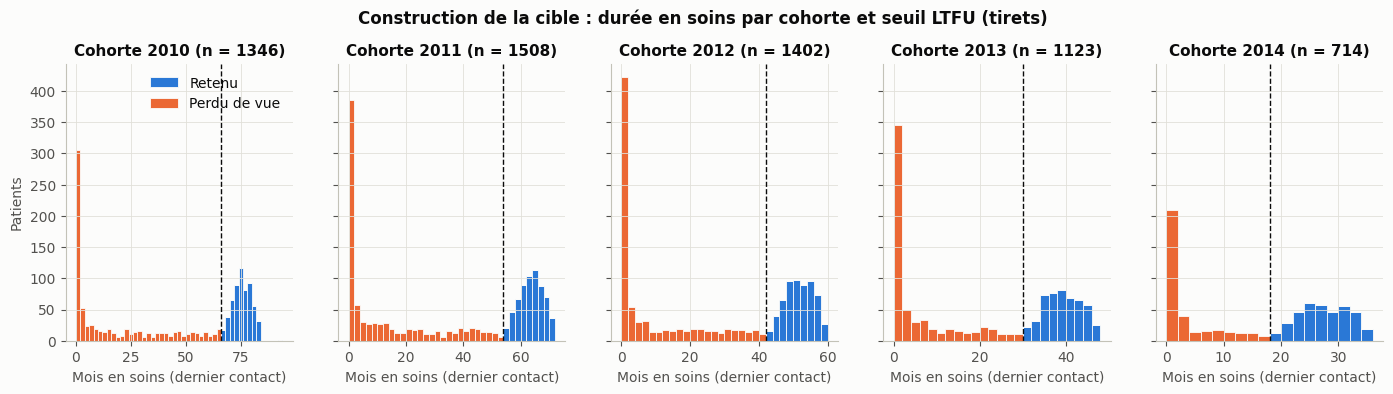

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6), sharey=True)
for ax, (annee, g) in zip(axes, df.groupby('Cohort year')):
    bins = np.arange(0, g['MonthsInCare'].max() + 3, 2)
    ax.hist([g.loc[g.LTFU == 0, 'MonthsInCare'], g.loc[g.LTFU == 1, 'MonthsInCare']], bins=bins,
            stacked=True, color=[C_RET, C_LTFU], label=list(CLASSES.values()), edgecolor=SURFACE, linewidth=0.6)
    ax.axvline(12 * (DATE_REF_ANNEE - annee) - DELAI_LTFU, color=INK, ls='--', lw=1)
    ax.set_title(f'Cohorte {annee} (n = {len(g)})')
    ax.set_xlabel('Mois en soins (dernier contact)')
axes[0].set_ylabel('Patients')
axes[0].legend(loc='upper right')
fig.suptitle('Construction de la cible : durée en soins par cohorte et seuil LTFU (tirets)', y=1.03, fontweight='bold')
savefig(fig, '01_construction_cible')
plt.show()

**Interprétation.**
* Les maxima observés de `MonthsInCare` (71, 59, 47 et 35 mois pour 2011 à 2014) correspondent **exactement** aux maxima théoriques d'un suivi arrêté au 31/12/2016, ce qui valide notre lecture de la variable. Seule exception : un patient de 2010 affiche 92 mois au lieu de 83 au maximum, une anomalie isolée et sans effet sur la cible (il est classé retenu dans tous les cas).
* La règle conservatrice donne **3 400 LTFU contre 3 397 publiés** (+3, soit 0,09 %). Le tableau de sensibilité montre que k = −6, le seuil déduit de la définition, est aussi celui qui colle le mieux à l'article.
* **418 des 424 patients tracés** (98,6 %) sont classés LTFU. Les 6 restants se trouvent dans la zone d'ambiguïté due au mois d'inclusion inconnu (vraisemblablement des patients inclus en début d'année).
* Les histogrammes montrent deux populations nettement séparées : un **pic massif à 0 mois** (patients jamais revenus après l'inclusion) et un bloc de patients retenus en fin de distribution. Cette séparation explique pourquoi la règle reproduit si bien l'article.

➡️ La cible reconstruite est fiable. Sa principale limite (le mois d'inclusion inconnu) touche quelques patients seulement.

## 3. Audit des variables et des fuites de données

Une **fuite de données** (*data leakage*) se produit quand un prédicteur contient une information indisponible au moment de la prédiction. Le modèle paraît alors excellent mais ne sert à rien en pratique. Chaque colonne est donc classée selon **le moment où elle devient connue** par rapport à T0, la fin du bilan d'inclusion.

In [8]:
LABS = ['ALT', 'CD4Count', 'Creatin', 'Hemoglob', 'Platelet', 'RNAVload', 'TotProt', 'Urea', 'WBC']
LABS2 = [c + '2' for c in LABS]

dictionnaire = pd.DataFrame([
    ('MonthsInCare', "Mois entre l'inclusion et le dernier contact", 'Définit la cible', 'Exclue des prédicteurs (fuite directe) ; sert de durée pour le modèle de Cox'),
    ('Tracking status', 'Patient recherché par traçage', "Après l'évènement (seuls des LTFU sont tracés)", 'Exclue (fuite)'),
    ('Interview status', 'Patient tracé et interrogé', "Après l'évènement", 'Exclue (fuite)'),
    ('Discontinue', 'Décès / transfert documenté', 'Pendant le suivi', "Lignes exclues, comme dans l'étude"),
    ('Age, Sex, MaritalStatus, Education', "Profil à l'inclusion", 'Connu à T0', 'Conservées'),
    ('Cohort year', "Année d'inclusion (2010-2014)", 'Connu à T0', "Transformée en durée d'exposition au risque"),
    ('WHOStage', "Stade clinique OMS à l'inclusion", 'Connu à T0', 'Conservée'),
    ('ALT … WBC (9 examens)', "Bilan biologique à l'inclusion", 'Connu à T0', 'Conservées'),
    ('HCT', "Hématocrite à l'inclusion", 'Connu à T0', 'Retirée : 93,5 % de valeurs manquantes'),
    ('ALT2 … WBC2, HCT2', 'Dernière valeur biologique connue', 'Mesurée pendant tout le suivi', 'Exclues : fuite temporelle (démontrée ci-dessous et en section 13)'),
], columns=['Variable(s)', 'Signification', 'Disponibilité', 'Décision'])
dictionnaire

,Variable(s),Signification,Disponibilité,Décision
0,MonthsInCare,Mois entre l'inclusion et le dernier contact,Définit la cible,Exclue des prédicteurs (fuite directe) ; sert ...
1,Tracking status,Patient recherché par traçage,Après l'évènement (seuls des LTFU sont tracés),Exclue (fuite)
2,Interview status,Patient tracé et interrogé,Après l'évènement,Exclue (fuite)
3,Discontinue,Décès / transfert documenté,Pendant le suivi,"Lignes exclues, comme dans l'étude"
4,"Age, Sex, MaritalStatus, Education",Profil à l'inclusion,Connu à T0,Conservées
5,Cohort year,Année d'inclusion (2010-2014),Connu à T0,Transformée en durée d'exposition au risque
6,WHOStage,Stade clinique OMS à l'inclusion,Connu à T0,Conservée
7,ALT … WBC (9 examens),Bilan biologique à l'inclusion,Connu à T0,Conservées
8,HCT,Hématocrite à l'inclusion,Connu à T0,"Retirée : 93,5 % de valeurs manquantes"
9,"ALT2 … WBC2, HCT2",Dernière valeur biologique connue,Mesurée pendant tout le suivi,Exclues : fuite temporelle (démontrée ci-desso...


**Les colonnes suffixées « 2 » sont-elles des valeurs de fin de suivi ?** Deux indices permettent de le vérifier :
* si `X2` est la dernière valeur sous traitement, les CD4 devraient augmenter et la charge virale chuter entre `X` et `X2` ;
* un patient qui n'est jamais revenu n'a eu qu'un seul bilan, donc `X2 = X`. Cette égalité devrait être bien plus fréquente chez les LTFU.

In [9]:
preuve = pd.DataFrame({
    'médiane inclusion (X)': df[LABS].median().values,
    'médiane dernière valeur (X2)': df[LABS2].median().values,
    '% X2 = X chez les retenus': [100 * (df[c] == df[c + '2'])[df.LTFU == 0].mean() for c in LABS],
    '% X2 = X chez les LTFU': [100 * (df[c] == df[c + '2'])[df.LTFU == 1].mean() for c in LABS],
}, index=LABS)
display(preuve)
print('Tracking status selon la cible reconstruite :')
pd.crosstab(df['LTFU'].map(CLASSES), df['Tracking status'].fillna(0).map({0: 'non tracé', 1: 'tracé'}))

,médiane inclusion (X),médiane dernière valeur (X2),% X2 = X chez les retenus,% X2 = X chez les LTFU
ALT,20.300,18.300,2.079,46.412
CD4Count,229.000,367.000,3.565,50.088
Creatin,83.335,76.080,3.676,46.824
Hemoglob,10.400,11.400,4.864,48.706
Platelet,226.000,234.000,4.085,48.000
RNAVload,"53,069.000",200.000,6.053,52.176
TotProt,91.300,89.500,58.745,64.235
Urea,3.100,3.100,61.864,69.294
WBC,5.300,4.920,5.087,48.618


Tracking status selon la cible reconstruite :


Tracking status,non tracé,tracé
LTFU,,
Perdu de vue,2982,418
Retenu,2687,6


**Interprétation.**
* Entre `X` et `X2`, les CD4 médians passent de 229 à 367 cellules/µL et la charge virale médiane de 53 069 à 200 copies/mL. C'est la signature d'un **traitement antirétroviral efficace** : `X2` est bien une valeur de **fin de suivi**.
* Pour 7 examens sur 9, `X2 = X` chez **46 à 52 % des LTFU** contre **2 à 6 % des retenus**. Cette égalité signifie « le patient n'a eu qu'un seul bilan », donc qu'il n'est pas revenu. Utiliser `X2` reviendrait à donner la réponse au modèle (démonstration chiffrée en section 13, S1). Les protéines totales et l'urée, rarement recontrôlées, sont égales dans environ 60 % des cas dans les deux groupes.
* Le traçage ne concerne que des LTFU (418 contre 6) : `Tracking status` est une conséquence de la cible, pas une cause.

➡️ Seules les variables connues à l'inclusion sont conservées.

## 4. Analyse exploratoire des données (EDA)

### 4.1 Vue d'ensemble des variables disponibles à l'inclusion

In [10]:
LIB = {'Age': 'Âge', 'Sex': 'Sexe', 'MaritalStatus': 'Statut marital', 'Education': "Niveau d'études",
       'WHOStage': 'Stade OMS', 'Cohort year': 'Année de cohorte', 'HCT': 'Hématocrite', 'ALT': 'ALAT',
       'CD4Count': 'CD4', 'Creatin': 'Créatinine', 'Hemoglob': 'Hémoglobine', 'Platelet': 'Plaquettes',
       'RNAVload': 'Charge virale', 'TotProt': 'Protéines totales', 'Urea': 'Urée', 'WBC': 'Leucocytes'}
UNITES = {'Age': 'ans', 'ALT': 'U/L', 'CD4Count': 'cellules/µL', 'Creatin': 'µmol/L', 'Hemoglob': 'g/dL',
          'Platelet': '10⁹/L', 'RNAVload': 'copies/mL', 'TotProt': 'g/L', 'Urea': 'mmol/L', 'WBC': '10⁹/L'}
VARS_INCLUSION = ['Age', 'Sex', 'MaritalStatus', 'Education', 'WHOStage', 'Cohort year', 'HCT'] + LABS

apercu = pd.DataFrame({'type': df[VARS_INCLUSION].dtypes.astype(str),
                       'n manquants': df[VARS_INCLUSION].isna().sum(),
                       '% manquants': 100 * df[VARS_INCLUSION].isna().mean(),
                       'valeurs distinctes': df[VARS_INCLUSION].nunique()})
display(apercu.sort_values('% manquants', ascending=False))
df[['Age', 'HCT'] + LABS].describe().T

,type,n manquants,% manquants,valeurs distinctes
HCT,float64,5697,93.501,201
WHOStage,float64,2637,43.279,4
RNAVload,float64,1648,27.047,3411
TotProt,float64,1562,25.636,1266
Education,object,1385,22.731,4
Urea,float64,1303,21.385,303
MaritalStatus,object,895,14.689,5
Age,float64,804,13.195,68
ALT,float64,685,11.242,949
Creatin,float64,671,11.013,4153


,count,mean,std,min,25%,50%,75%,max
Age,"5,289.000",41.681,9.560,17.000,35.000,41.000,47.000,88.000
HCT,396.000,29.803,7.283,2.470,25.875,30.200,34.000,64.300
ALT,"5,408.000",30.076,55.104,0.100,13.500,20.300,32.825,"2,405.600"
CD4Count,"5,571.000",336.300,"2,957.248",2.000,97.000,229.000,402.000,"204,577.000"
Creatin,"5,422.000",121.597,790.996,4.200,66.662,83.335,104.560,"56,555.000"
Hemoglob,"5,493.000",10.977,16.151,2.400,8.900,10.400,11.900,711.000
Platelet,"5,489.000",243.446,111.014,1.950,181.000,226.000,285.000,"2,567.000"
RNAVload,"4,445.000","265,413.914","695,703.341",0.000,"3,915.484","53,069.000","287,143.000","10,000,000.000"
TotProt,"4,531.000",93.880,91.060,0.700,83.700,91.300,99.900,"6,108.000"
Urea,"4,790.000",4.666,6.811,0.100,2.200,3.100,4.400,97.400


### 4.2 Qualité des données
#### a) Valeurs manquantes : sont-elles aléatoires ?
Si une valeur manque plus souvent chez les futurs perdus de vue, le fait même qu'elle manque est **informatif**. Une valeur absente n'est alors pas manquante au hasard (MNAR). Le test du χ² compare la fréquence des valeurs manquantes entre les deux groupes.

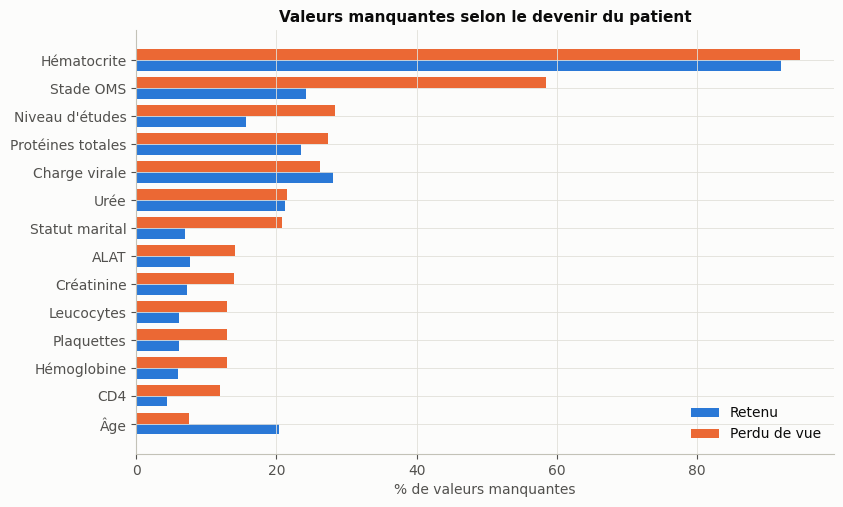

,Retenu,Perdu de vue,p (χ²)
HCT,91.979,94.706,2.3e-05
WHOStage,24.174,58.412,9.0e-158
Education,15.670,28.324,1.7e-31
TotProt,23.543,27.294,9.6e-04
RNAVload,28.110,26.206,1.0e-01
Urea,21.203,21.529,7.8e-01
MaritalStatus,6.981,20.794,1.9e-51
ALT,7.687,14.059,7.3e-15
Creatin,7.241,14.000,8.2e-17
WBC,6.127,12.971,1.1e-18


In [11]:
manq = 100 * pd.DataFrame({'Retenu': df.loc[df.LTFU == 0, VARS_INCLUSION].isna().mean(),
                           'Perdu de vue': df.loc[df.LTFU == 1, VARS_INCLUSION].isna().mean()})
manq = manq[manq.sum(axis=1) > 0]
manq['p (χ²)'] = [f"{stats.chi2_contingency(pd.crosstab(df[c].isna(), df.LTFU))[1]:.1e}" for c in manq.index]
manq = manq.sort_values('Perdu de vue')

fig, ax = plt.subplots(figsize=(9, 5.5))
pos, h = np.arange(len(manq)), 0.38
ax.barh(pos - h / 2, manq['Retenu'], height=h, color=C_RET, label='Retenu')
ax.barh(pos + h / 2, manq['Perdu de vue'], height=h, color=C_LTFU, label='Perdu de vue')
ax.set_yticks(pos, [LIB[c] for c in manq.index])
ax.set_xlabel('% de valeurs manquantes')
ax.set_title('Valeurs manquantes selon le devenir du patient')
ax.legend(loc='lower right')
savefig(fig, '02_valeurs_manquantes')
plt.show()
manq.sort_values('Perdu de vue', ascending=False)

#### b) Doublons
On distingue deux cas. Une copie exacte d'un dossier **riche** (bilan biologique identique à la décimale près) est presque certainement une double saisie du même patient. Une copie d'un dossier **quasi vide** (seulement sexe, année et durée) peut tout à fait correspondre à des patients différents.

In [12]:
copies = df[df.duplicated(subset=COLS_ORIG, keep=False)]
print(f"{df.duplicated(subset=COLS_ORIG).sum()} lignes sont des copies exactes d'une ligne précédente "
      f"({len(copies)} lignes impliquées).")
print('Nombre de champs renseignés dans ces lignes :')
print((copies[COLS_ORIG].notna().sum(axis=1)).value_counts().sort_index().rename('lignes').to_string())
print(f"Part de LTFU parmi ces lignes : {copies['LTFU'].mean():.1%}")
print('\nCopies contenant un bilan biologique :')
copies[copies[LABS].notna().any(axis=1)][['id_patient'] + COLS_ORIG[:8] + LABS[:4]]

100 lignes sont des copies exactes d'une ligne précédente (112 lignes impliquées).
Nombre de champs renseignés dans ces lignes :
3     108
5       2
25      2
Part de LTFU parmi ces lignes : 98.2%

Copies contenant un bilan biologique :


,id_patient,MonthsInCare,Tracking status,Interview status,Age,Cohort year,Sex,MaritalStatus,Education,ALT,CD4Count,Creatin,Hemoglob
1346,P1350,69,NaN,NaN,NaN,2011,Male,Married,Secondary,26.100,50.000,69.460,10.600
2853,P2863,69,NaN,NaN,NaN,2011,Male,Married,Secondary,26.100,50.000,69.460,10.600


#### c) Incohérences de modalités

In [13]:
for c in ['Sex', 'MaritalStatus', 'Education']:
    print(f'{c:14s}', df[c].value_counts(dropna=False).to_dict())

Sex            {'Female': 4053, 'Male': 2039, 'FEMALE': 1}
MaritalStatus  {'Married': 3024, 'Single': 1455, nan: 895, 'Widowed': 445, 'Separated': 162, 'Divorced': 112}
Education      {'Secondary': 2312, 'Tertiary': 1394, nan: 1385, 'Primary': 1001, 'Tertiary\nSecondary': 1}


#### d) Anomalies : valeurs physiologiquement impossibles
Les unités sont déduites des médianes (ex. hémoglobine ≈ 10 → g/dL ; créatinine ≈ 83 → µmol/L). Les bornes de plausibilité ci-dessous **excluent les erreurs de saisie ou d'unité, pas les valeurs extrêmes réelles**. Par exemple, une ALAT à 2 400 U/L reste possible lors d'une poussée d'hépatite, ce qui est précisément un cas pertinent pour VIHEPAT. *Ces bornes sont à valider avec le référent clinique de l'équipe.*

,unité,borne basse,borne haute,n < borne,n > borne,min observé,max observé
variable,,,,,,,
Âge,ans,15.000,100.000,0,0,17.000,88.000
ALAT,U/L,1.000,"5,000.000",8,0,0.100,"2,405.600"
CD4,cellules/µL,1.000,"3,000.000",0,4,2.000,"204,577.000"
Créatinine,µmol/L,15.000,"2,000.000",15,8,4.200,"56,555.000"
Hémoglobine,g/dL,2.000,20.000,0,22,2.400,711.000
Plaquettes,10⁹/L,5.000,"1,500.000",12,2,1.950,"2,567.000"
Charge virale,copies/mL,0.000,"10,000,000.000",0,0,0.000,"10,000,000.000"
Protéines totales,g/L,30.000,150.000,21,37,0.700,"6,108.000"
Urée,mmol/L,0.500,100.000,28,0,0.100,97.400


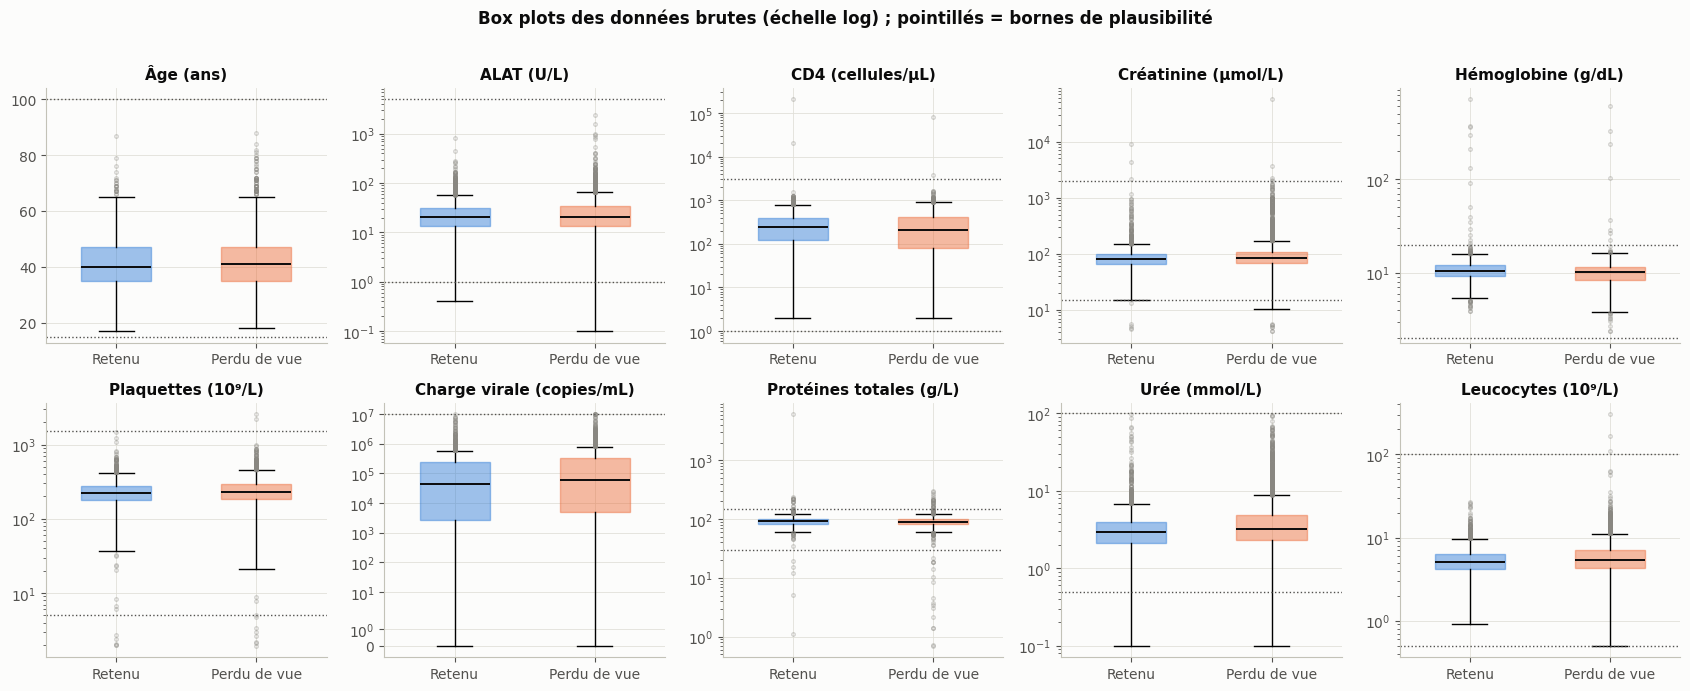

In [14]:
BORNES = {'Age': (15, 100), 'ALT': (1, 5000), 'CD4Count': (1, 3000), 'Creatin': (15, 2000),
          'Hemoglob': (2, 20), 'Platelet': (5, 1500), 'RNAVload': (0, 1e7), 'TotProt': (30, 150),
          'Urea': (0.5, 100), 'WBC': (0.5, 100)}
anomalies = pd.DataFrame([{'variable': LIB[c], 'unité': UNITES[c], 'borne basse': lo, 'borne haute': hi,
                           'n < borne': int((df[c] < lo).sum()), 'n > borne': int((df[c] > hi).sum()),
                           'min observé': df[c].min(), 'max observé': df[c].max()}
                          for c, (lo, hi) in BORNES.items()]).set_index('variable')
display(anomalies)

fig, axes = plt.subplots(2, 5, figsize=(17, 6.8))
for ax, c in zip(axes.flat, BORNES):
    donnees = [df.loc[df.LTFU == k, c].dropna() for k in (0, 1)]
    bp = ax.boxplot(donnees, widths=0.5, patch_artist=True,
                    flierprops=dict(marker='o', markersize=2.5, alpha=0.35, markeredgecolor=MUTED))
    for boite, couleur in zip(bp['boxes'], [C_RET, C_LTFU]):
        boite.set(facecolor=couleur, alpha=0.45, edgecolor=couleur)
    for mediane in bp['medians']:
        mediane.set(color=INK, lw=1.4)
    lo, hi = BORNES[c]
    if c != 'Age':
        ax.set_yscale('symlog' if lo == 0 else 'log')
    ax.axhline(hi, color=INK2, ls=':', lw=1)
    if lo > 0:
        ax.axhline(lo, color=INK2, ls=':', lw=1)
    ax.set_xticks([1, 2], list(CLASSES.values()))
    ax.set_title(f'{LIB[c]} ({UNITES[c]})')
fig.suptitle('Box plots des données brutes (échelle log) ; pointillés = bornes de plausibilité', y=1.01, fontweight='bold')
fig.tight_layout()
savefig(fig, '03_boxplots_anomalies')
plt.show()

### 4.3 Déséquilibre des classes

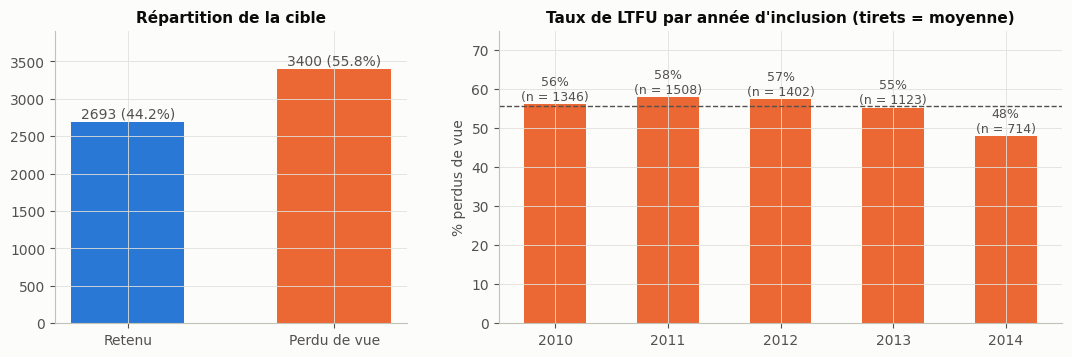

Ratio LTFU / retenus = 1.26


In [15]:
effectifs = df['LTFU'].map(CLASSES).value_counts().reindex(list(CLASSES.values()))
taux_cohorte = df.groupby('Cohort year')['LTFU'].agg(['mean', 'size'])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [1, 1.6]})
axes[0].bar(effectifs.index, effectifs.values, color=[C_RET, C_LTFU], width=0.55)
for i, v in enumerate(effectifs.values):
    axes[0].text(i, v + 50, f'{v} ({v / len(df):.1%})', ha='center', color=INK2)
axes[0].set_ylim(0, effectifs.max() * 1.15)
axes[0].set_title('Répartition de la cible')
axes[1].bar(taux_cohorte.index.astype(str), 100 * taux_cohorte['mean'], color=C_LTFU, width=0.55)
axes[1].axhline(100 * df.LTFU.mean(), color=INK2, ls='--', lw=1)
for i, (t, n) in enumerate(zip(taux_cohorte['mean'], taux_cohorte['size'])):
    axes[1].text(i, 100 * t + 1, f'{t:.0%}\n(n = {n})', ha='center', color=INK2, fontsize=9)
axes[1].set_ylim(0, 75)
axes[1].set_ylabel('% perdus de vue')
axes[1].set_title("Taux de LTFU par année d'inclusion (tirets = moyenne)")
savefig(fig, '04_desequilibre_classes')
plt.show()
print(f"Ratio LTFU / retenus = {effectifs['Perdu de vue'] / effectifs['Retenu']:.2f}")

**Interprétation.** Les perdus de vue sont **majoritaires** : 3 400 sur 6 093, soit 55,8 %, pour un ratio de 1,26. Le déséquilibre est faible et inversé par rapport à la plupart des problèmes médicaux. Trois conséquences :
* aucun rééquilibrage artificiel (SMOTE, sous-échantillonnage) n'est nécessaire ; le découpage est simplement stratifié ;
* l'**accuracy est trompeuse** : prédire « perdu de vue » pour tout le monde donne déjà 55,8 % ;
* le plancher de la PR-AUC est la prévalence, **0,558**, et non 0,5. Tout modèle doit être comparé à ce plancher.

Le taux de LTFU est stable entre 2010 et 2013 (55 à 58 %) et plus bas en 2014 (48 %) : ces patients ont eu moins de temps pour décrocher. D'où la variable de durée d'exposition.

### 4.4 Distributions des variables numériques (après retrait des valeurs impossibles)
Pour l'exploration, les valeurs hors bornes sont neutralisées (même règle que le nettoyage formel de la section 5). Les variables très asymétriques sont représentées en échelle logarithmique.

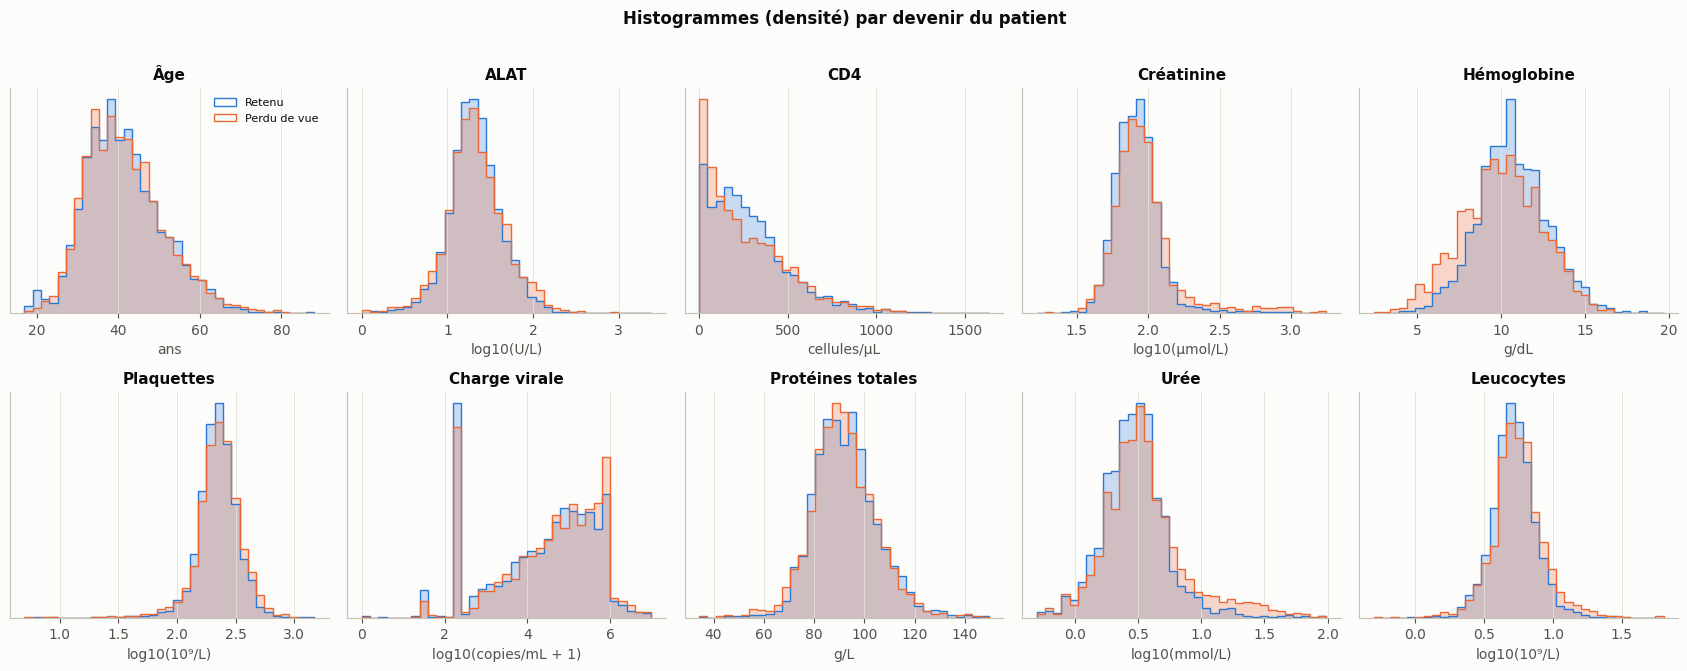

,médiane retenus,médiane LTFU,p (Mann-Whitney),AUC univariée,sens
variable,,,,,
Hémoglobine,10.600,10.200,3.8e-21,0.574,↓ risque
Urée,2.900,3.200,3.1e-14,0.564,↑ risque
Leucocytes,5.100,5.400,2.4e-11,0.552,↑ risque
Créatinine,81.100,85.160,1.0e-10,0.551,↑ risque
Charge virale,"44,926.690","58,447.000",5.0e-05,0.535,↑ risque
CD4,243.000,211.000,6.7e-05,0.531,↓ risque
Plaquettes,222.000,230.000,1.8e-03,0.524,↑ risque
Protéines totales,91.600,90.900,8.0e-02,0.515,↓ risque
ALAT,20.400,20.300,5.7e-01,0.505,↑ risque


In [16]:
def appliquer_bornes(d):
    """Remplace les valeurs physiologiquement impossibles par NaN (aucun paramètre appris)."""
    d = d.copy()
    for c, (lo, hi) in BORNES.items():
        d.loc[(d[c] < lo) | (d[c] > hi), c] = np.nan
    return d


eda = appliquer_bornes(df)
NUM_EDA = ['Age'] + LABS
LOGX = {'ALT', 'Creatin', 'Platelet', 'Urea', 'WBC'}

fig, axes = plt.subplots(2, 5, figsize=(17, 6.6))
for ax, c in zip(axes.flat, NUM_EDA):
    s = eda[c].dropna()
    if c == 'RNAVload':
        s, xl = np.log10(s + 1), 'log10(copies/mL + 1)'
    elif c in LOGX:
        s, xl = np.log10(s), f'log10({UNITES[c]})'
    else:
        xl = UNITES[c]
    bins = np.histogram_bin_edges(s, bins=35)
    for k in (0, 1):
        sk = s[eda.loc[s.index, 'LTFU'] == k]
        ax.hist(sk, bins=bins, density=True, histtype='stepfilled', alpha=0.25, color=[C_RET, C_LTFU][k])
        ax.hist(sk, bins=bins, density=True, histtype='step', lw=1.5, color=[C_RET, C_LTFU][k], label=CLASSES[k])
    ax.set_title(LIB[c])
    ax.set_xlabel(xl)
    ax.set_yticks([])
axes[0, 0].legend(loc='upper right', fontsize=8)
fig.suptitle('Histogrammes (densité) par devenir du patient', y=1.01, fontweight='bold')
fig.tight_layout()
savefig(fig, '05_histogrammes')
plt.show()

tests = []
for c in NUM_EDA:
    a, b = eda.loc[eda.LTFU == 0, c].dropna(), eda.loc[eda.LTFU == 1, c].dropna()
    s = eda[[c, 'LTFU']].dropna()
    auc = roc_auc_score(s['LTFU'], s[c])
    tests.append({'variable': LIB[c], 'médiane retenus': a.median(), 'médiane LTFU': b.median(),
                  'p (Mann-Whitney)': f'{stats.mannwhitneyu(a, b).pvalue:.1e}',
                  'AUC univariée': max(auc, 1 - auc), 'sens': '↑ risque' if auc > 0.5 else '↓ risque'})
pd.DataFrame(tests).set_index('variable').sort_values('AUC univariée', ascending=False)

### 4.5 Variables catégorielles et cible
Le taux de LTFU est présenté avec un intervalle de confiance à 95 % (méthode de Wilson). L'intensité de chaque association est mesurée par le **V de Cramér** : 0 = aucune association, 1 = association parfaite.

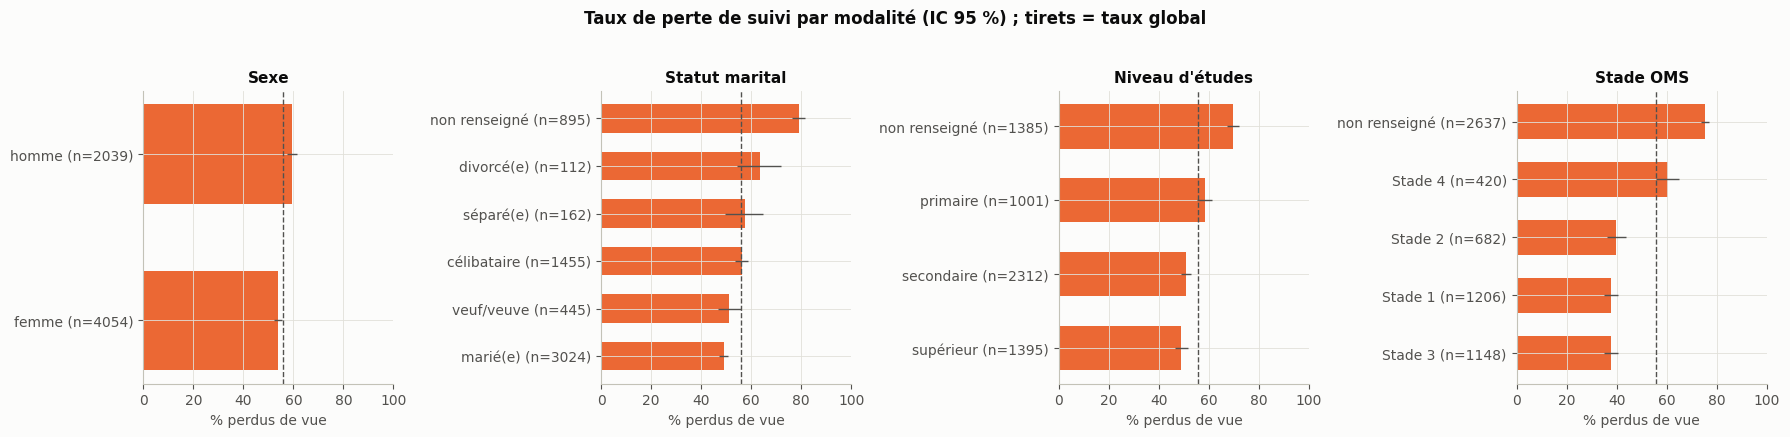

,χ²,ddl,p,V de Cramér
variable,,,,
Sexe,17.128,1,3.5e-05,0.053
Statut marital,257.889,5,1.1e-53,0.206
Niveau d'études,159.766,3,2.1e-34,0.162
Stade OMS,792.782,4,2.8e-170,0.361


In [17]:
TRAD = {'Married': 'marié(e)', 'Single': 'célibataire', 'Divorced': 'divorcé(e)', 'Separated': 'séparé(e)',
        'Widowed': 'veuf/veuve', 'Primary': 'primaire', 'Secondary': 'secondaire', 'Tertiary': 'supérieur',
        'Female': 'femme', 'Male': 'homme', 'Inconnu': 'non renseigné'}


def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    demi = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centre - demi, centre + demi


eda['Sex'] = eda['Sex'].str.capitalize()                                    # FEMALE → Female
eda['Education'] = eda['Education'].replace({'Tertiary\nSecondary': 'Tertiary'})
eda['WHOStage_txt'] = eda['WHOStage'].map(lambda v: f'Stade {int(v)}' if pd.notna(v) else np.nan)
CAT_EDA = {'Sex': 'Sexe', 'MaritalStatus': 'Statut marital', 'Education': "Niveau d'études", 'WHOStage_txt': 'Stade OMS'}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
assoc = []
for ax, (c, titre) in zip(axes, CAT_EDA.items()):
    s = eda[c].fillna('Inconnu')
    t = eda.groupby(s)['LTFU'].agg(['sum', 'size'])
    t['taux'] = t['sum'] / t['size']
    t = t.sort_values('taux')
    ic = np.array([wilson(k, n) for k, n in zip(t['sum'], t['size'])])
    ax.barh(range(len(t)), 100 * t['taux'], color=C_LTFU, height=0.6,
            xerr=[100 * (t['taux'] - ic[:, 0]), 100 * (ic[:, 1] - t['taux'])], error_kw=dict(ecolor=INK2, lw=1))
    ax.set_yticks(range(len(t)), [f"{TRAD.get(i, i)} (n={n})" for i, n in zip(t.index, t['size'])])
    ax.axvline(100 * df.LTFU.mean(), color=INK2, ls='--', lw=1)
    ax.set_xlim(0, 100)
    ax.set_xlabel('% perdus de vue')
    ax.set_title(titre)
    ct = pd.crosstab(s, eda['LTFU'])
    chi2, p, ddl, _ = stats.chi2_contingency(ct)
    assoc.append({'variable': titre, 'χ²': chi2, 'ddl': ddl, 'p': f'{p:.1e}',
                  'V de Cramér': np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))})
fig.suptitle('Taux de perte de suivi par modalité (IC 95 %) ; tirets = taux global', y=1.03, fontweight='bold')
fig.tight_layout()
savefig(fig, '06_categorielles')
plt.show()
pd.DataFrame(assoc).set_index('variable')

### 4.6 Matrice de corrélation
On utilise la corrélation de **Spearman** (rangs), qui résiste mieux que celle de Pearson aux distributions asymétriques et aux valeurs extrêmes. On y ajoute le nombre d'éléments manquants dans le bilan d'inclusion (stade OMS + 9 examens), une variable créée formellement en section 5.

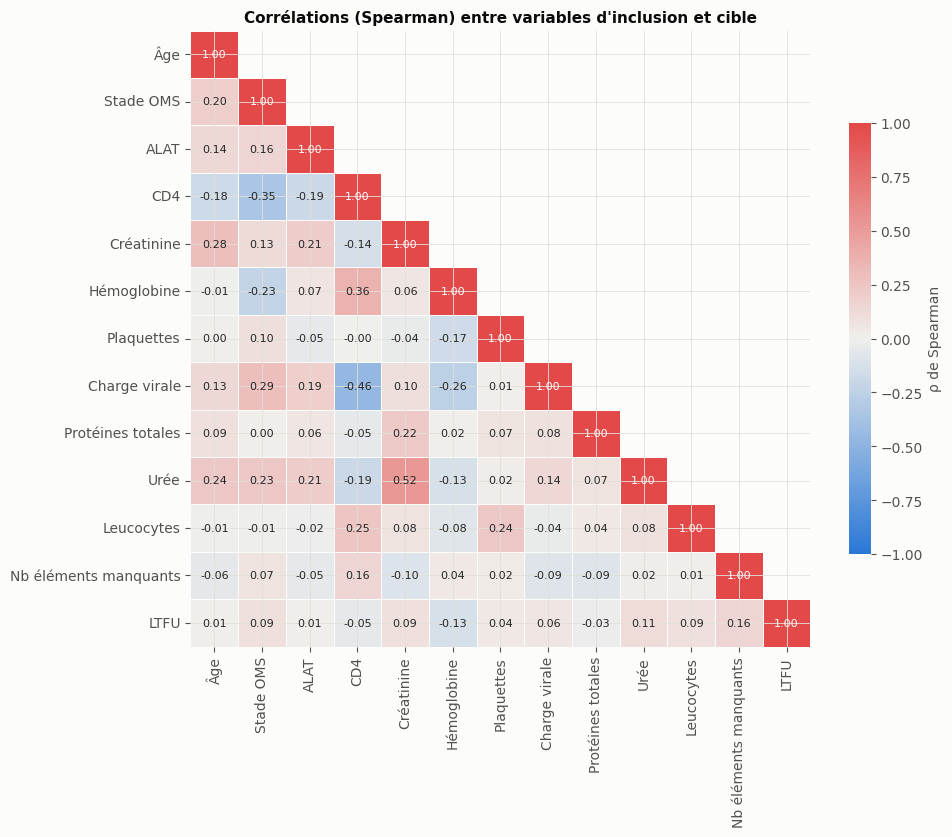

,Nb éléments manquants,Hémoglobine,Urée,Leucocytes,Créatinine,Stade OMS,Charge virale,CD4,Plaquettes,Protéines totales,ALAT,Âge
ρ avec LTFU,0.161,-0.128,0.110,0.090,0.088,0.087,0.061,-0.053,0.042,-0.026,0.008,0.008


In [18]:
eda['nb_examens_manquants'] = df[['WHOStage'] + LABS].isna().sum(axis=1)
cols_corr = ['Age', 'WHOStage'] + LABS + ['nb_examens_manquants', 'LTFU']
noms_corr = [LIB.get(c, c) for c in cols_corr[:-2]] + ['Nb éléments manquants', 'LTFU']
corr = eda[cols_corr].corr(method='spearman')
corr.index = corr.columns = noms_corr

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cmap=CMAP_DIV, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 8}, linewidths=0.5, linecolor=SURFACE,
            cbar_kws={'label': 'ρ de Spearman', 'shrink': 0.7}, ax=ax)
ax.set_title('Corrélations (Spearman) entre variables d\'inclusion et cible')
savefig(fig, '07_correlations')
plt.show()
corr['LTFU'].drop('LTFU').sort_values(key=np.abs, ascending=False).to_frame('ρ avec LTFU').T

### 4.7 Diagrammes de dispersion

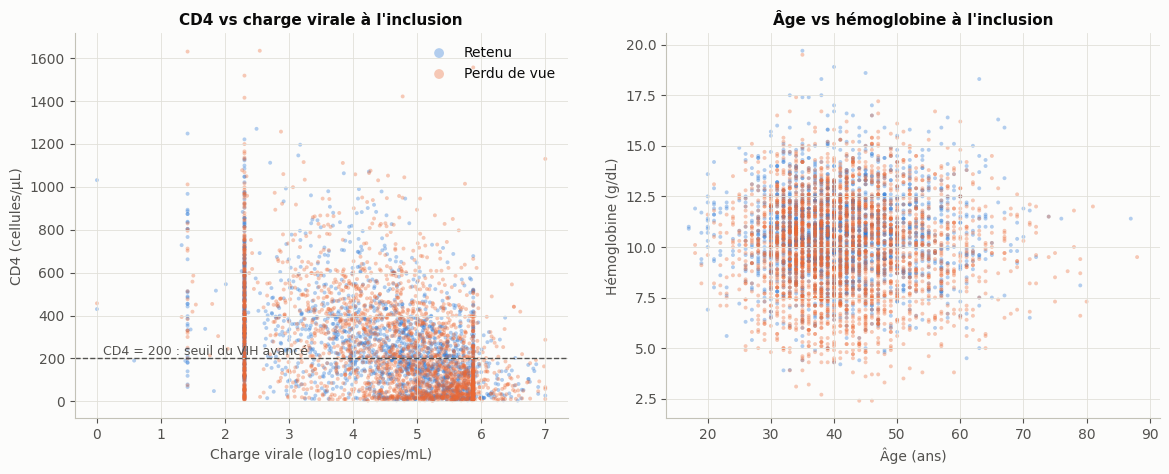

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
s = eda.dropna(subset=['CD4Count', 'RNAVload']).sample(frac=1, random_state=SEED)
for k in (0, 1):
    m = s['LTFU'] == k
    axes[0].scatter(np.log10(s.loc[m, 'RNAVload'] + 1), s.loc[m, 'CD4Count'], s=8, alpha=0.35,
                    color=[C_RET, C_LTFU][k], label=CLASSES[k], edgecolors='none')
axes[0].axhline(200, color=INK2, ls='--', lw=1)
axes[0].text(0.1, 215, 'CD4 = 200 : seuil du VIH avancé', color=INK2, fontsize=9)
axes[0].set_xlabel('Charge virale (log10 copies/mL)')
axes[0].set_ylabel('CD4 (cellules/µL)')
axes[0].set_title('CD4 vs charge virale à l\'inclusion')
axes[0].legend(markerscale=2.5)

s = eda.dropna(subset=['Age', 'Hemoglob']).sample(frac=1, random_state=SEED)
for k in (0, 1):
    m = s['LTFU'] == k
    axes[1].scatter(s.loc[m, 'Age'], s.loc[m, 'Hemoglob'], s=8, alpha=0.35, color=[C_RET, C_LTFU][k],
                    label=CLASSES[k], edgecolors='none')
axes[1].set_xlabel('Âge (ans)')
axes[1].set_ylabel('Hémoglobine (g/dL)')
axes[1].set_title('Âge vs hémoglobine à l\'inclusion')
savefig(fig, '08_dispersion')
plt.show()

### 4.8 Courbes de maintien dans le parcours de soins (Kaplan-Meier)
L'analyse de survie exploite **le moment** de la sortie, alors que la cible binaire ne dit que si elle a eu lieu. Le temps est `MonthsInCare` et l'évènement est la perte de suivi. Les patients retenus sont « censurés » : on sait seulement qu'ils étaient encore suivis à leur dernier contact. Le regroupement du statut marital reprend celui de l'article : divorcé(e), séparé(e) et veuf/veuve ensemble.

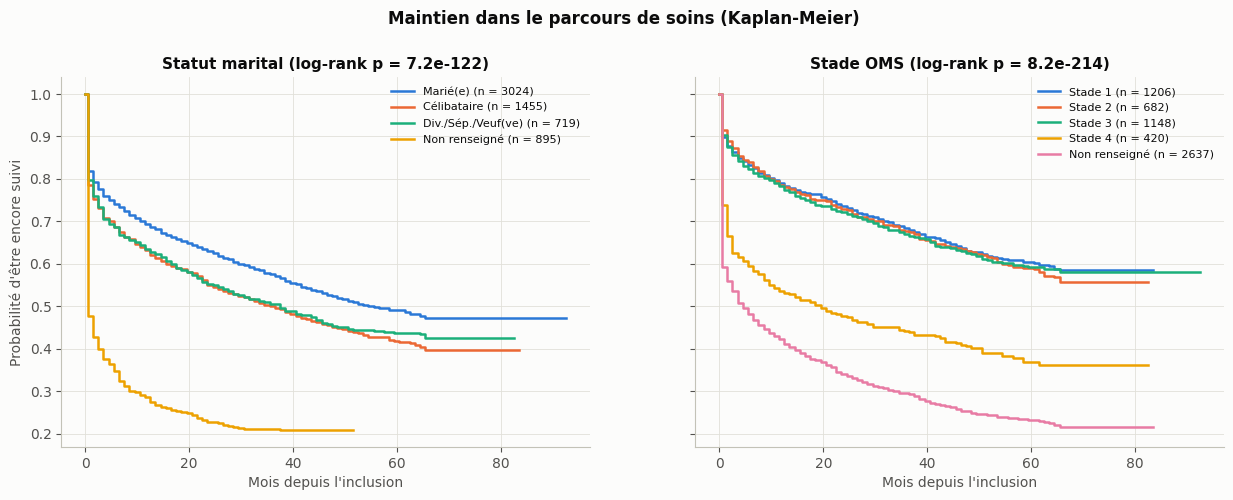

Patients jamais revenus après la visite d'inclusion (MonthsInCare = 0) : 1474 (24.2% de la cohorte, 43.4% des LTFU)


In [20]:
GROUPES_MARITAL = {'Married': 'Marié(e)', 'Single': 'Célibataire', 'Divorced': 'Div./Sép./Veuf(ve)',
                   'Separated': 'Div./Sép./Veuf(ve)', 'Widowed': 'Div./Sép./Veuf(ve)'}
eda['statut_marital_grp'] = eda['MaritalStatus'].map(GROUPES_MARITAL).fillna('Non renseigné')
eda['stade_grp'] = eda['WHOStage_txt'].fillna('Non renseigné')

ORDRE_GROUPES = {'statut_marital_grp': ['Marié(e)', 'Célibataire', 'Div./Sép./Veuf(ve)', 'Non renseigné'],
                 'stade_grp': ['Stade 1', 'Stade 2', 'Stade 3', 'Stade 4', 'Non renseigné']}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
kmf = KaplanMeierFitter()
for ax, (col, titre) in zip(axes, [('statut_marital_grp', 'Statut marital'), ('stade_grp', 'Stade OMS')]):
    for i, g in enumerate(ORDRE_GROUPES[col]):
        d = eda[eda[col] == g]
        kmf.fit(d['MonthsInCare'] + 0.5, d['LTFU'], label=f'{g} (n = {len(d)})')
        kmf.plot_survival_function(ax=ax, ci_show=False, color=SERIES[i], lw=1.8)
    lr = multivariate_logrank_test(eda['MonthsInCare'], eda[col], eda['LTFU'])
    ax.set_title(f'{titre} (log-rank p = {lr.p_value:.1e})')
    ax.set_xlabel("Mois depuis l'inclusion")
    ax.legend(fontsize=8)
axes[0].set_ylabel('Probabilité d\'être encore suivi')
fig.suptitle('Maintien dans le parcours de soins (Kaplan-Meier)', y=1.02, fontweight='bold')
savefig(fig, '09_kaplan_meier')
plt.show()
print(f"Patients jamais revenus après la visite d'inclusion (MonthsInCare = 0) : {(df.MonthsInCare == 0).sum()} "
      f"({(df.MonthsInCare == 0).mean():.1%} de la cohorte, {(df.MonthsInCare == 0).sum() / n_ltfu:.1%} des LTFU)")

### 4.9 Synthèse des observations
| # | Observation | Conséquence pour la modélisation |
|---|---|---|
| 1 | **24,2 % de la cohorte ne revient jamais** après l'inclusion : 1 474 patients, soit 43 % des LTFU | La perte de suivi est d'abord un phénomène **précoce** ; le modèle doit repérer les patients dès l'inclusion |
| 2 | Les **valeurs manquantes sont informatives** : stade OMS manquant chez 58 % des LTFU contre 24 % des retenus, statut marital 21 % contre 7 %, examens environ 13 % contre 6 % (χ², p < 10⁻¹⁴) | Indicateurs « non mesuré », modalité « Inconnu » et score de complétude du bilan |
| 3 | **Exception : l'âge manque plus souvent chez les retenus** (20 % contre 8 %) | Artefact d'enregistrement : pas d'indicateur, imputation aléatoire |
| 4 | Les variables biologiques ont un **pouvoir discriminant univarié faible** (AUC ≤ 0,57 ; la meilleure est l'hémoglobine, plus basse chez les LTFU) | Les performances attendues sont modestes ; il faut combiner les variables |
| 5 | Les associations catégorielles les plus fortes sont le **stade OMS** (V de Cramér 0,36, porté par le « non renseigné » et le stade 4) et le **statut marital** (V 0,21) ; le sexe est significatif mais faible (V 0,05) | Le stade OMS est traité en catégories (relation non monotone) |
| 6 | Courbes de Kaplan-Meier : les **marié(e)s restent plus longtemps** en soins que les célibataires et les divorcé(e)s/séparé(e)s/veufs (log-rank p < 10⁻¹²⁰), ce qui confirme l'article | Validation externe de nos données : nous retrouvons le résultat publié |
| 7 | Les corrélations entre variables explicatives restent modérées (\|ρ\| ≤ 0,52). Les plus fortes sont attendues cliniquement : créatinine-urée (0,52, fonction rénale) et CD4-charge virale (−0,46) | Pas de multicolinéarité gênante ; la régularisation L2 suffit |
| 8 | 160 **valeurs impossibles** (ex. CD4 = 204 577, hémoglobine = 711 g/dL, protéines = 6 108 g/L) et 1 vrai doublon | Neutralisation déterministe (section 5) |
| 9 | Fortes asymétries (charge virale, ALAT, créatinine, urée) | Transformations log / racine |

## 5. Nettoyage et création de variables

### 5.1 Nettoyage
Toutes les opérations de cette étape sont **déterministes** : aucune statistique n'est apprise sur les données (pas de moyenne ni de médiane). On peut donc les appliquer avant le découpage sans risque de fuite. L'imputation, qui apprend des médianes, est faite plus tard, **après** le découpage, dans le pipeline.

| Problème | Traitement | Justification |
|---|---|---|
| 1 doublon informatif | Suppression de la copie | Même patient saisi deux fois ; le garder biaiserait l'évaluation s'il tombait dans deux jeux différents |
| 99 copies de dossiers quasi vides | Conservées | Indiscernables, donc vraisemblablement des patients distincts (l'effectif total correspond aux 6 108 de l'article) |
| `FEMALE`, `Tertiary\nSecondary` | Harmonisées (`Female`, niveau le plus élevé `Tertiary`) | Erreurs de saisie évidentes |
| Valeurs biologiques impossibles | Remplacées par `NaN`, puis imputées comme les autres manquants | Ce sont des erreurs : les écrêter reviendrait à inventer une valeur |
| Valeurs extrêmes plausibles | Conservées, avec transformation logarithmique | Réalité clinique (ex. poussée d'hépatite) ; le log limite leur poids dans les modèles linéaires |
| `HCT` (93,5 % manquants) | Supprimée | Imputer 93 % des valeurs créerait de l'information artificielle |

In [21]:
def nettoyer(d):
    """Nettoyage déterministe. Retourne les données nettoyées et un journal chiffré des opérations."""
    d, journal = d.copy(), {}
    copie = d.duplicated(subset=COLS_ORIG, keep='first')
    informatif = d[LABS].notna().any(axis=1)
    journal['doublons informatifs supprimés'] = int((copie & informatif).sum())
    journal['copies de dossiers vides conservées'] = int((copie & ~informatif).sum())
    d = d.loc[~(copie & informatif)]
    # Complétude du bilan d'inclusion, calculée AVANT le filtre de plausibilité :
    # une valeur saisie mais erronée reste une valeur saisie.
    d['nb_examens_manquants'] = d[['WHOStage'] + LABS].isna().sum(axis=1)
    d['Sex'] = d['Sex'].str.strip().str.capitalize()
    d['Education'] = d['Education'].replace({'Tertiary\nSecondary': 'Tertiary'})
    for c, (lo, hi) in BORNES.items():
        hors = (d[c] < lo) | (d[c] > hi)
        journal[f'{c} : valeurs impossibles → NaN'] = int(hors.sum())
        d.loc[hors, c] = np.nan
    d = d.drop(columns=['HCT'])
    return d.reset_index(drop=True), journal


df_clean, journal_nettoyage = nettoyer(df)
print(f'{len(df)} → {len(df_clean)} patients')
pd.Series(journal_nettoyage, name='lignes / valeurs').to_frame()

6093 → 6092 patients


,lignes / valeurs
doublons informatifs supprimés,1
copies de dossiers vides conservées,99
Age : valeurs impossibles → NaN,0
ALT : valeurs impossibles → NaN,8
CD4Count : valeurs impossibles → NaN,4
Creatin : valeurs impossibles → NaN,23
Hemoglob : valeurs impossibles → NaN,22
Platelet : valeurs impossibles → NaN,14
RNAVload : valeurs impossibles → NaN,0
TotProt : valeurs impossibles → NaN,58


### 5.2 Création de variables
| Variable créée | Définition | Justification |
|---|---|---|
| `nb_examens_manquants` | Nombre d'éléments du bilan d'inclusion non renseignés (stade OMS + 9 examens, de 0 à 10) | Un bilan incomplet signale un patient qui ne termine pas son parcours d'entrée. C'est la variable la plus corrélée à la cible (section 4.6), et VIHEPAT pourra l'observer directement |
| `annees_exposition` | (2016 − année d'inclusion) + 0,5 | Les patients inclus tôt ont eu plus de temps pour décrocher. On ajuste sur cette durée plutôt que d'utiliser l'année brute |
| `log10_CV` | log10(charge virale + 1) | Échelle de référence en virologie VIH ; le +1 gère les charges indétectables codées 0 |
| `log_ALT`, `log_Creatin`, `log_Urea`, `log_WBC`, `log_Platelet` | Logarithme naturel | Réduit une forte asymétrie (voir le tableau ci-dessous) |
| `sqrt_CD4` | Racine carrée des CD4 | Transformation usuelle en épidémiologie du VIH ; le log sur-corrigerait |
| `vih_avance` | CD4 < 200 **ou** stade OMS 3-4 | **Définition OMS du VIH avancé** : seuil clinique interprétable par un soignant |
| `cv_inf_1000` | Charge virale < 1 000 copies/mL dès l'inclusion | Suggère un patient déjà traité ailleurs (transfert entrant), dont le comportement de suivi peut différer |

**Cas particulier de l'âge.** L'âge manque **plus souvent chez les patients retenus** (20 % contre 8 %, section 4.2). Aucun mécanisme comportemental n'explique ce lien, qui ressemble à un artefact d'enregistrement que le modèle ne doit pas exploiter. Il n'a donc **pas d'indicateur « non mesuré »**, et il est imputé par **tirage aléatoire parmi les âges observés**, et non par la médiane. Une première version du notebook imputait la médiane, exactement 41 ans : XGBoost avait appris à reconnaître ces 41 ans artificiels, et l'âge était devenu sa 2ᵉ variable la plus importante, uniquement à cause de l'artefact. Avec le tirage aléatoire, une valeur imputée ne se distingue plus d'une vraie valeur.

,asymétrie brute,variable du modèle,asymétrie après transformation
ALAT,23.035,log_ALT,0.229
CD4,1.275,sqrt_CD4,0.226
Créatinine,6.957,log_Creatin,2.124
Plaquettes,1.947,log_Platelet,-1.165
Charge virale,8.109,log10_CV,-0.587
Urée,6.384,log_Urea,1.058
Leucocytes,5.388,log_WBC,0.313
Hémoglobine,-0.060,Hemoglob,-0.060
Protéines totales,0.279,TotProt,0.279


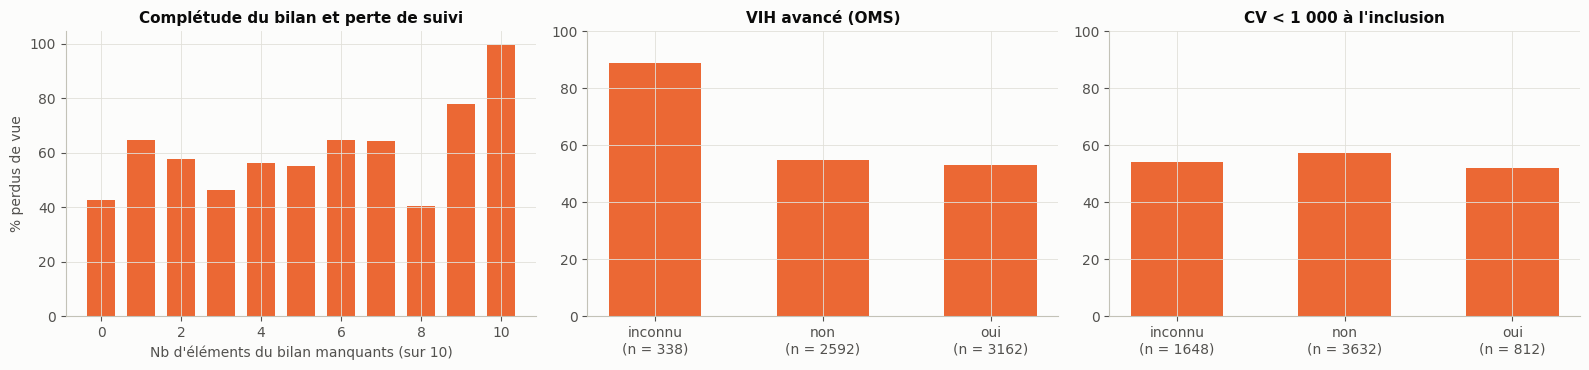

In [22]:
def creer_variables(d):
    """Variables dérivées, calculées ligne par ligne (aucun paramètre appris)."""
    d = d.copy()
    d['annees_exposition'] = (DATE_REF_ANNEE - d['Cohort year']) + 0.5
    d['log10_CV'] = np.log10(d['RNAVload'] + 1)
    for c in ['ALT', 'Creatin', 'Urea', 'WBC', 'Platelet']:
        d[f'log_{c}'] = np.log(d[c])
    d['sqrt_CD4'] = np.sqrt(d['CD4Count'])
    d['cv_inf_1000'] = np.where(d['RNAVload'].isna(), np.nan, (d['RNAVload'] < 1000).astype(float))
    connu = d['WHOStage'].notna() | d['CD4Count'].notna()
    avance = (d['WHOStage'] >= 3) | (d['CD4Count'] < 200)
    d['vih_avance'] = np.where(connu, avance.astype(float), np.nan)
    d['WHOStage'] = d['WHOStage'].map({1.0: '1', 2.0: '2', 3.0: '3', 4.0: '4'})   # catégoriel : relation non monotone
    return d


df_model = creer_variables(df_clean)

TRANSFO = {'ALT': 'log_ALT', 'CD4Count': 'sqrt_CD4', 'Creatin': 'log_Creatin', 'Platelet': 'log_Platelet',
           'RNAVload': 'log10_CV', 'Urea': 'log_Urea', 'WBC': 'log_WBC', 'Hemoglob': 'Hemoglob', 'TotProt': 'TotProt'}
display(pd.DataFrame({'asymétrie brute': [stats.skew(df_model[c].dropna()) for c in TRANSFO],
                      'variable du modèle': list(TRANSFO.values()),
                      'asymétrie après transformation': [stats.skew(df_model[v].dropna()) for v in TRANSFO.values()]},
                     index=[LIB[c] for c in TRANSFO]))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
t = df_model.groupby('nb_examens_manquants')['LTFU'].agg(['mean', 'size'])
axes[0].bar(t.index, 100 * t['mean'], color=C_LTFU, width=0.7)
axes[0].set_xlabel("Nb d'éléments du bilan manquants (sur 10)")
axes[0].set_ylabel('% perdus de vue')
axes[0].set_title('Complétude du bilan et perte de suivi')
for ax, v, titre in [(axes[1], 'vih_avance', 'VIH avancé (OMS)'), (axes[2], 'cv_inf_1000', 'CV < 1 000 à l\'inclusion')]:
    t = df_model.groupby(df_model[v].map({0.0: 'non', 1.0: 'oui'}).fillna('inconnu'))['LTFU'].agg(['mean', 'size'])
    ax.bar([f'{i}\n(n = {n})' for i, n in zip(t.index, t['size'])], 100 * t['mean'], color=C_LTFU, width=0.55)
    ax.set_ylim(0, 100)
    ax.set_title(titre)
fig.tight_layout()
savefig(fig, '10_variables_creees')
plt.show()

In [23]:
VARS_GEN = ['Age', 'annees_exposition', 'nb_examens_manquants']          # imputation aléatoire, sans indicateur
VARS_BIO = ['log_ALT', 'sqrt_CD4', 'log_Creatin', 'Hemoglob', 'log_Platelet', 'log10_CV',
            'TotProt', 'log_Urea', 'log_WBC']                               # imputation médiane + indicateur
VARS_BIN = ['vih_avance', 'cv_inf_1000']                                    # imputation par le mode
VARS_CAT = ['Sex', 'MaritalStatus', 'Education', 'WHOStage']                # modalité « Inconnu » + one-hot
FEATURES = VARS_GEN + VARS_BIO + VARS_BIN + VARS_CAT

# Libellé, colonne brute (pour l'affichage) et unité de chaque variable du modèle
VARIABLES = {
    'Age': ('Âge', 'Age', 'ans'), 'annees_exposition': ("Durée d'exposition", 'annees_exposition', 'ans'),
    'nb_examens_manquants': ('Éléments du bilan manquants', 'nb_examens_manquants', ''),
    'log_ALT': ('ALAT', 'ALT', 'U/L'), 'sqrt_CD4': ('CD4', 'CD4Count', 'cellules/µL'),
    'log_Creatin': ('Créatinine', 'Creatin', 'µmol/L'), 'Hemoglob': ('Hémoglobine', 'Hemoglob', 'g/dL'),
    'log_Platelet': ('Plaquettes', 'Platelet', '10⁹/L'), 'log10_CV': ('Charge virale', 'RNAVload', 'copies/mL'),
    'TotProt': ('Protéines totales', 'TotProt', 'g/L'), 'log_Urea': ('Urée', 'Urea', 'mmol/L'),
    'log_WBC': ('Leucocytes', 'WBC', '10⁹/L'), 'vih_avance': ('VIH avancé (OMS)', 'vih_avance', ''),
    'cv_inf_1000': ('CV < 1 000 copies/mL', 'cv_inf_1000', ''), 'Sex': ('Sexe', 'Sex', ''),
    'MaritalStatus': ('Statut marital', 'MaritalStatus', ''), 'Education': ("Niveau d'études", 'Education', ''),
    'WHOStage': ('Stade OMS', 'WHOStage', '')}
print(f'{len(FEATURES)} variables d\'entrée : {FEATURES}')

18 variables d'entrée : ['Age', 'annees_exposition', 'nb_examens_manquants', 'log_ALT', 'sqrt_CD4', 'log_Creatin', 'Hemoglob', 'log_Platelet', 'log10_CV', 'TotProt', 'log_Urea', 'log_WBC', 'vih_avance', 'cv_inf_1000', 'Sex', 'MaritalStatus', 'Education', 'WHOStage']


## 6. Protocole d'évaluation, découpage et prétraitement

### 6.1 Métriques retenues et règle de choix (fixées *avant* d'entraîner les modèles)
| Métrique | Ce qu'elle mesure | Pourquoi ici |
|---|---|---|
| **PR-AUC** (précision moyenne) | Qualité du classement des patients à risque | **Métrique principale** : directement liée à l'usage, qui est d'ordonner une file de relances |
| ROC-AUC | Discrimination globale | Standard en recherche clinique ; permet la comparaison avec la littérature |
| **Sensibilité (rappel)** | Part des futurs LTFU détectés | Manquer un patient qui décroche coûte cher (interruption du traitement, résistances, transmission, décès) |
| Spécificité, VPP, VPN | Erreurs de chaque type | La VPP indique la charge de travail utile pour l'équipe soignante |
| Brier, log-loss, courbe de calibration | Fiabilité des probabilités | VIHEPAT affiche un pourcentage de risque : il doit être fidèle à la réalité |
| Bénéfice net (*decision curve*) | Utilité clinique selon le seuil | Méthode de référence pour évaluer un modèle de prédiction clinique (Vickers, 2006) |
| Rappel @ capacité | Part des LTFU captés en appelant les *k* % les plus à risque | Traduit directement la contrainte opérationnelle d'un centre |
| C-index | Concordance du modèle de survie | Équivalent de l'AUC pour des données censurées |

L'accuracy n'est pas utilisée seule : elle masque le type d'erreur commis.

**Règle de sélection.** On retient le modèle ayant la meilleure PR-AUC en validation. *Principe de parcimonie :* si son avantage sur la régression logistique n'est pas significatif (l'intervalle de confiance à 95 % de la différence, obtenu par bootstrap apparié, contient 0), on garde la régression logistique, plus simple et plus explicable.

**Seuil de décision.** On le choisit sur la validation. C'est le seuil le plus élevé qui atteint une **sensibilité d'au moins 80 %**, ce qui donne la meilleure précision possible sous cette contrainte.

### 6.2 Découpage train / validation / test (60 / 20 / 20)
* **Entraînement (60 %)** : apprentissage, et choix des hyperparamètres par validation croisée stratifiée à 5 plis. Le prétraitement est réappris à chaque pli pour éviter toute fuite.
* **Validation (20 %)** : courbes de perte par epoch, comparaison des modèles, choix du seuil.
* **Test (20 %)** : **utilisé une seule fois**, à la fin, pour l'évaluation finale.
* **Stratification croisée cible × année de cohorte** : chaque jeu garde la même proportion de LTFU et la même répartition des durées d'exposition.
* Le découpage est aléatoire et non temporel. La robustesse au temps est testée à part en section 13 (entraînement sur 2010-2012, test sur 2013-2014).

In [24]:
X, y = df_model[FEATURES], df_model['LTFU']
strate = df_model['LTFU'].astype(str) + '_' + df_model['Cohort year'].astype(str)
idx_trval, idx_test = train_test_split(df_model.index, test_size=0.20, stratify=strate, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trval, test_size=0.25, stratify=strate.loc[idx_trval], random_state=SEED)
X_train, X_val, X_test = X.loc[idx_train], X.loc[idx_val], X.loc[idx_test]
y_train, y_val, y_test = y.loc[idx_train], y.loc[idx_val], y.loc[idx_test]

pd.DataFrame({jeu: {'patients': len(i), '% du total': 100 * len(i) / len(df_model), '% LTFU': 100 * y.loc[i].mean(),
                    **{f'% cohorte {a}': 100 * (df_model.loc[i, 'Cohort year'] == a).mean() for a in range(2010, 2015)}}
              for jeu, i in [('Entraînement', idx_train), ('Validation', idx_val), ('Test', idx_test)]}).T

,patients,% du total,% LTFU,% cohorte 2010,% cohorte 2011,% cohorte 2012,% cohorte 2013,% cohorte 2014
Entraînement,"3,654.000",59.980,55.802,22.085,24.713,23.043,18.446,11.713
Validation,"1,219.000",20.010,55.783,22.067,24.774,22.970,18.458,11.731
Test,"1,219.000",20.010,55.865,22.149,24.774,22.970,18.376,11.731


### 6.3 Prétraitement : imputation, standardisation, encodage
| Bloc | Traitement | Justification |
|---|---|---|
| Âge, exposition, nb d'éléments manquants | Imputation par **tirage aléatoire** parmi les valeurs observées, puis standardisation | Seul l'âge a des valeurs manquantes ; le tirage empêche le modèle d'exploiter l'artefact décrit en 5.2 |
| 9 examens biologiques | Médiane **+ indicateur binaire « non mesuré »**, puis standardisation | L'absence d'un examen est informative (section 4.2). L'indicateur conserve ce signal au lieu de le gommer |
| Indicateurs cliniques binaires | Valeur la plus fréquente | Leur caractère « inconnu » est déjà porté par les indicateurs des examens |
| Sexe, statut marital, études, stade OMS | Modalité explicite **« Inconnu »**, puis **one-hot** | Variables nominales, sans ordre : le one-hot évite d'imposer une hiérarchie artificielle. Le stade OMS est traité en catégories car son lien avec le risque n'est pas monotone (section 4.5) |

**Standardisation (centrer-réduire).** Elle est indispensable pour la régression logistique, car la pénalité L2 doit traiter toutes les variables à la même échelle, et pour le réseau de neurones, dont la descente de gradient converge mal sur des échelles hétérogènes. Elle n'a aucun effet sur les arbres, qui sont invariants aux transformations monotones. On utilise donc **un seul préprocesseur pour tous les modèles** : ils voient exactement la même information, ce qui rend la comparaison équitable.

**Rééquilibrage des classes** (SMOTE, sous-échantillonnage) : **non utilisé**. Le déséquilibre est faible (ratio 1,26) et le rééquilibrage fausse les probabilités, alors que VIHEPAT doit afficher un risque calibré.

**Variante « stricte »** (section 13) : toutes les valeurs manquantes y sont imputées par tirage aléatoire, sans indicateur ni modalité « Inconnu ». Le modèle n'a alors **aucun moyen** de savoir qu'une valeur manquait.

In [25]:
class ImputationAleatoire(BaseEstimator, TransformerMixin):
    """Remplace chaque valeur manquante par une valeur tirée au hasard parmi les valeurs observées à l'entraînement.
    Contrairement à la médiane, la valeur imputée est indiscernable d'une vraie valeur : un modèle à base d'arbres
    ne peut pas s'en servir pour repérer les dossiers incomplets. Le tirage est reproductible (random_state)."""

    def __init__(self, random_state=SEED):
        self.random_state = random_state

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.valeurs_ = [X[c].dropna().to_numpy() for c in X.columns]
        return self

    def transform(self, X):
        X, rng = pd.DataFrame(X).copy(), np.random.default_rng(self.random_state)
        for j, c in enumerate(X.columns):
            manquant = X[c].isna().to_numpy()
            if manquant.any():
                X.loc[manquant, c] = rng.choice(self.valeurs_[j], manquant.sum())
        return X.to_numpy()

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def construire_preprocesseur(avec_completude=True, vars_gen=VARS_GEN, vars_bio=VARS_BIO,
                             vars_bin=VARS_BIN, vars_cat=VARS_CAT):
    """avec_completude=False : variante « stricte » sans aucune information sur les valeurs manquantes."""
    if not avec_completude:
        vars_gen = [v for v in vars_gen if v != 'nb_examens_manquants']
    imp_bio = SimpleImputer(strategy='median', add_indicator=True) if avec_completude else ImputationAleatoire()
    imp_bin = SimpleImputer(strategy='most_frequent') if avec_completude else ImputationAleatoire()
    imp_cat = SimpleImputer(strategy='constant', fill_value='Inconnu') if avec_completude else ImputationAleatoire()
    return ColumnTransformer([
        ('gen', Pipeline([('imp', ImputationAleatoire()), ('sc', StandardScaler())]), list(vars_gen)),
        ('bio', Pipeline([('imp', imp_bio), ('sc', StandardScaler())]), list(vars_bio)),
        ('bin', imp_bin, list(vars_bin)),
        ('cat', Pipeline([('imp', imp_cat),
                          ('ohe', OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False))]),
         list(vars_cat)),
    ], verbose_feature_names_out=False)


def var_modele(nom):
    """Nom d'une colonne transformée → variable d'origine du modèle."""
    if nom.startswith('missingindicator_'):
        return nom[len('missingindicator_'):]
    if nom in VARIABLES:
        return nom
    return next((c for c in VARS_CAT if nom.startswith(c + '_')), nom)


def libelle(nom):
    v = var_modele(nom)
    lab = VARIABLES.get(v, (v,))[0]
    if nom.startswith('missingindicator_'):
        return f'{lab} : non mesuré'
    if v in VARS_CAT and nom != v:
        valeur = nom[len(v) + 1:]
        return f'{lab} = {TRAD.get(valeur, valeur)}'
    return lab


prep_fit = construire_preprocesseur().fit(X_train)                   # appris sur l'entraînement uniquement
A_train, A_val, A_test = (prep_fit.transform(d) for d in (X_train, X_val, X_test))
NOMS_A = prep_fit.get_feature_names_out()
print(f'{A_train.shape[1]} colonnes après prétraitement :')
print([libelle(n) for n in NOMS_A])

39 colonnes après prétraitement :
['Âge', "Durée d'exposition", 'Éléments du bilan manquants', 'ALAT', 'CD4', 'Créatinine', 'Hémoglobine', 'Plaquettes', 'Charge virale', 'Protéines totales', 'Urée', 'Leucocytes', 'ALAT : non mesuré', 'CD4 : non mesuré', 'Créatinine : non mesuré', 'Hémoglobine : non mesuré', 'Plaquettes : non mesuré', 'Charge virale : non mesuré', 'Protéines totales : non mesuré', 'Urée : non mesuré', 'Leucocytes : non mesuré', 'VIH avancé (OMS)', 'CV < 1 000 copies/mL', 'Sexe = homme', 'Statut marital = divorcé(e)', 'Statut marital = non renseigné', 'Statut marital = marié(e)', 'Statut marital = séparé(e)', 'Statut marital = célibataire', 'Statut marital = veuf/veuve', "Niveau d'études = non renseigné", "Niveau d'études = primaire", "Niveau d'études = secondaire", "Niveau d'études = supérieur", 'Stade OMS = 1', 'Stade OMS = 2', 'Stade OMS = 3', 'Stade OMS = 4', 'Stade OMS = non renseigné']


## 7. Modélisation

Cinq approches de complexité croissante, plus une analyse de survie :

| Modèle | Rôle | Hypothèse |
|---|---|---|
| Référence naïve | Plancher : prédit la prévalence pour tout le monde | Aucun signal |
| Régression logistique | Référence **interprétable** (odds ratios) | Effets additifs sur le log-odds |
| Random Forest | Non linéaire, robuste, peu sensible au réglage | Interactions captées par bagging d'arbres |
| XGBoost | Boosting de gradient, souvent le meilleur sur données tabulaires | Interactions captées séquentiellement |
| MLP (réseau de neurones) | Approche *deep learning* | Représentation non linéaire apprise |
| Modèle de Cox | Analyse complémentaire du **temps** jusqu'à la perte de suivi | Risques proportionnels |

In [26]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {'pr_auc': 'average_precision', 'roc_auc': 'roc_auc'}
NOMS_MODELES = ['Référence naïve', 'Régression logistique', 'Random Forest', 'XGBoost', 'MLP']
COULEUR = {'Régression logistique': SERIES[0], 'Random Forest': SERIES[1], 'XGBoost': SERIES[2],
           'MLP': SERIES[3], 'Cox': SERIES[4]}
modeles, historiques = {}, {}


def auc_roc(y_vrai, p):
    """ROC-AUC via la statistique de Mann-Whitney : identique à roc_auc_score, bien plus rapide en bootstrap."""
    y_vrai, rangs = np.asarray(y_vrai), stats.rankdata(p)
    n1 = y_vrai.sum()
    return (rangs[y_vrai == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * (len(y_vrai) - n1))


def metriques(y_vrai, p, seuil=0.5):
    """Métriques de discrimination, de calibration et de décision au seuil donné."""
    y_vrai, p = np.asarray(y_vrai).astype(int), np.asarray(p, dtype=float)
    signale, malade = p >= seuil, y_vrai == 1
    tp, fp = int((signale & malade).sum()), int((signale & ~malade).sum())
    fn, tn = int((~signale & malade).sum()), int((~signale & ~malade).sum())
    pc = np.clip(p, 1e-6, 1 - 1e-6)
    return {'ROC-AUC': auc_roc(y_vrai, p), 'PR-AUC': average_precision_score(y_vrai, p),
            'Brier': np.mean((p - y_vrai) ** 2), 'Log-loss': -np.mean(y_vrai * np.log(pc) + (1 - y_vrai) * np.log(1 - pc)),
            'Sensibilité': tp / (tp + fn), 'Spécificité': tn / (tn + fp),
            'VPP': tp / (tp + fp) if tp + fp else np.nan, 'VPN': tn / (tn + fn) if tn + fn else np.nan,
            'F1': 2 * tp / (2 * tp + fp + fn), 'F2': 5 * tp / (5 * tp + 4 * fn + fp)}


def tracer_courbes(hist, x, titre, nom_fig, marque=None, refs=None):
    """Évolution de la perte et de l'AUC sur l'entraînement et la validation."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.9))
    for ax, m, ylab in [(axes[0], 'loss', 'Log-loss (entropie croisée)'), (axes[1], 'auc', 'ROC-AUC')]:
        ax.plot(hist[x], hist[f'{m}_train'], color=SERIES[0], label='Entraînement')
        ax.plot(hist[x], hist[f'{m}_val'], color=SERIES[1], label='Validation')
        if marque is not None:
            ax.axvline(marque, color=INK2, ls='--', lw=1, label=f'retenu : {marque}')
        if refs and m in refs:
            for etiquette, valeur, couleur in refs[m]:
                ax.axhline(valeur, color=couleur, ls=':', lw=1.2, label=etiquette)
        ax.set_xlabel(x)
        ax.set_ylabel(ylab)
        ax.legend(fontsize=8)
    fig.suptitle(titre, y=1.02, fontweight='bold')
    savefig(fig, nom_fig)
    plt.show()

### 7.1 Référence naïve

In [27]:
modeles['Référence naïve'] = Pipeline([('prep', construire_preprocesseur()),
                                       ('clf', DummyClassifier(strategy='prior'))]).fit(X_train, y_train)
pd.Series(metriques(y_val, modeles['Référence naïve'].predict_proba(X_val)[:, 1]), name='validation').to_frame().T

,ROC-AUC,PR-AUC,Brier,Log-loss,Sensibilité,Spécificité,VPP,VPN,F1,F2
validation,0.500,0.558,0.247,0.686,1.000,0.000,0.558,NaN,0.716,0.863


### 7.2 Régression logistique (référence interprétable)
L'intensité de la régularisation L2 (paramètre `C`) est choisie par validation croisée à 5 plis sur l'entraînement.

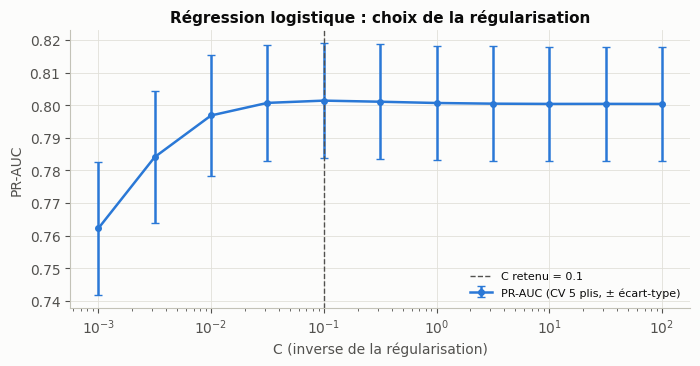

C optimal = 0.1 | PR-AUC CV = 0.801 ± 0.018


In [28]:
grille_lr = GridSearchCV(
    Pipeline([('prep', construire_preprocesseur()), ('clf', LogisticRegression(max_iter=5000))]),
    {'clf__C': np.logspace(-3, 2, 11)}, scoring=SCORING, refit='pr_auc', cv=CV, n_jobs=-1).fit(X_train, y_train)
modeles['Régression logistique'] = grille_lr.best_estimator_
C_OPT = grille_lr.best_params_['clf__C']

cvr = pd.DataFrame(grille_lr.cv_results_)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.errorbar(cvr['param_clf__C'].astype(float), cvr['mean_test_pr_auc'], yerr=cvr['std_test_pr_auc'],
            color=SERIES[0], marker='o', ms=4, capsize=3, label='PR-AUC (CV 5 plis, ± écart-type)')
ax.axvline(C_OPT, color=INK2, ls='--', lw=1, label=f'C retenu = {C_OPT:.3g}')
ax.set_xscale('log')
ax.set_xlabel('C (inverse de la régularisation)')
ax.set_ylabel('PR-AUC')
ax.set_title('Régression logistique : choix de la régularisation')
ax.legend(fontsize=8)
plt.show()
print(f"C optimal = {C_OPT:.3g} | PR-AUC CV = {grille_lr.best_score_:.3f} ± {cvr.loc[grille_lr.best_index_, 'std_test_pr_auc']:.3f}")

**Évolution de la perte par epoch.** La régression logistique de scikit-learn est résolue par L-BFGS, un optimiseur déterministe sans notion d'epoch. Pour visualiser l'apprentissage, on entraîne **le même modèle** (même pénalité, même préprocesseur) par descente de gradient stochastique : une epoch correspond à un passage complet sur l'entraînement. Les pointillés indiquent la perte de la solution L-BFGS, vers laquelle la SGD doit converger.

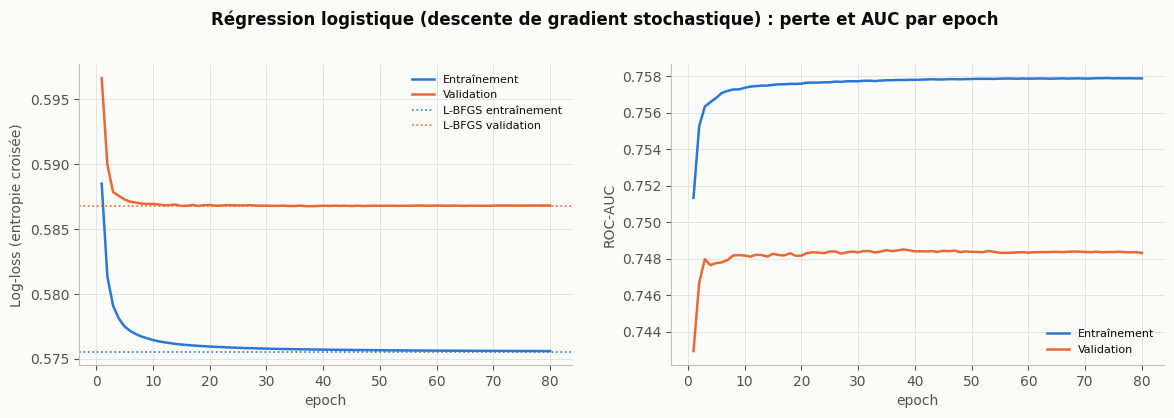

In [29]:
lr_lbfgs = modeles['Régression logistique']
refs_lr = {'loss': [('L-BFGS entraînement', log_loss(y_train, lr_lbfgs.predict_proba(X_train)[:, 1]), SERIES[0]),
                    ('L-BFGS validation', log_loss(y_val, lr_lbfgs.predict_proba(X_val)[:, 1]), SERIES[1])]}
sgd = SGDClassifier(loss='log_loss', penalty='l2', alpha=1 / (C_OPT * len(A_train)), average=True,
                    learning_rate='invscaling', eta0=0.05, power_t=0.25, random_state=SEED)   # SGD moyennée : convergence lisse
rng_sgd, hist = np.random.default_rng(SEED), []
for epoch in range(1, 81):
    ordre = rng_sgd.permutation(len(A_train))
    sgd.partial_fit(A_train[ordre], y_train.values[ordre], classes=[0, 1])
    p_tr, p_va = sgd.predict_proba(A_train)[:, 1], sgd.predict_proba(A_val)[:, 1]
    hist.append({'epoch': epoch, 'loss_train': log_loss(y_train, p_tr), 'loss_val': log_loss(y_val, p_va),
                 'auc_train': roc_auc_score(y_train, p_tr), 'auc_val': roc_auc_score(y_val, p_va)})
historiques['Régression logistique'] = pd.DataFrame(hist)
tracer_courbes(historiques['Régression logistique'], 'epoch',
               'Régression logistique (descente de gradient stochastique) : perte et AUC par epoch',
               '11_courbes_lr', refs=refs_lr)

### 7.3 Random Forest
Recherche aléatoire de 25 combinaisons d'hyperparamètres, en validation croisée à 5 plis. Ces hyperparamètres contrôlent la complexité des arbres, donc le risque de surapprentissage.

Meilleurs hyperparamètres : {'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 8} | PR-AUC CV = 0.809


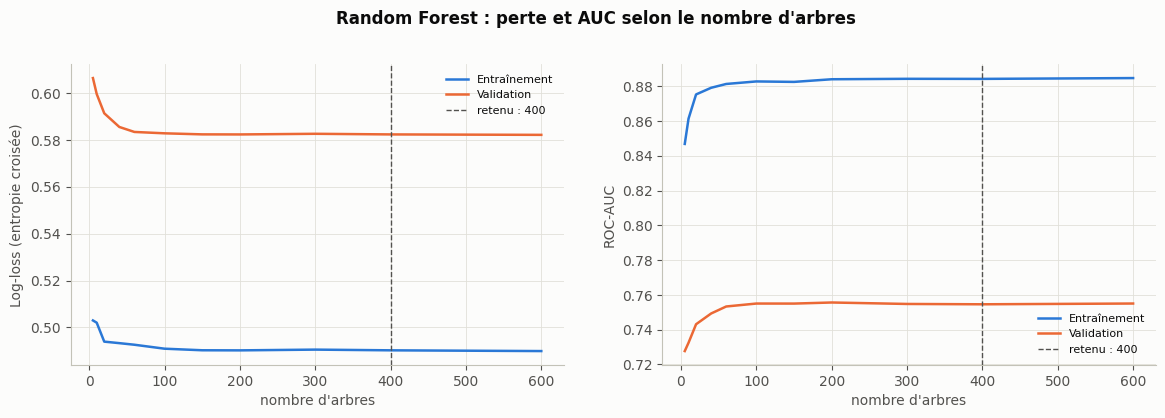

In [30]:
recherche_rf = RandomizedSearchCV(
    Pipeline([('prep', construire_preprocesseur()),
              ('clf', RandomForestClassifier(n_estimators=400, random_state=SEED, n_jobs=1))]),
    {'clf__max_depth': [4, 6, 8, 10, 14, None], 'clf__min_samples_leaf': [1, 3, 5, 10, 20, 40],
     'clf__max_features': ['sqrt', 0.3, 0.5]},
    n_iter=25, scoring=SCORING, refit='pr_auc', cv=CV, random_state=SEED, n_jobs=-1).fit(X_train, y_train)
modeles['Random Forest'] = recherche_rf.best_estimator_
params_rf = {k.replace('clf__', ''): v for k, v in recherche_rf.best_params_.items()}
print(f'Meilleurs hyperparamètres : {params_rf} | PR-AUC CV = {recherche_rf.best_score_:.3f}')

# Courbe de performance en fonction du nombre d'arbres (équivalent des epochs pour le bagging)
rf_courbe, hist = RandomForestClassifier(**params_rf, warm_start=True, random_state=SEED, n_jobs=-1), []
for n in [5, 10, 20, 40, 60, 100, 150, 200, 300, 400, 600]:
    rf_courbe.set_params(n_estimators=n).fit(A_train, y_train)
    p_tr, p_va = rf_courbe.predict_proba(A_train)[:, 1], rf_courbe.predict_proba(A_val)[:, 1]
    hist.append({"nombre d'arbres": n, 'loss_train': log_loss(y_train, np.clip(p_tr, 1e-6, 1 - 1e-6)),
                 'loss_val': log_loss(y_val, np.clip(p_va, 1e-6, 1 - 1e-6)),
                 'auc_train': roc_auc_score(y_train, p_tr), 'auc_val': roc_auc_score(y_val, p_va)})
historiques['Random Forest'] = pd.DataFrame(hist)
tracer_courbes(historiques['Random Forest'], "nombre d'arbres",
               "Random Forest : perte et AUC selon le nombre d'arbres", '12_courbes_rf', marque=400)

### 7.4 XGBoost
Recherche aléatoire de 40 combinaisons en validation croisée à 5 plis. Le nombre d'arbres retenu est **celui de la validation croisée**. Les courbes ci-dessous, sur 2 000 itérations avec arrêt anticipé, servent uniquement de **diagnostic** : elles vérifient que ce choix est proche de l'optimum observé sur la validation, sans utiliser la validation pour régler le modèle.

Meilleurs hyperparamètres : {'subsample': 0.8, 'reg_lambda': 1, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.02, 'gamma': 0.5, 'colsample_bytree': 0.5} | PR-AUC CV = 0.811


Optimum de la perte en validation : 368 arbres ; retenu par CV : 300


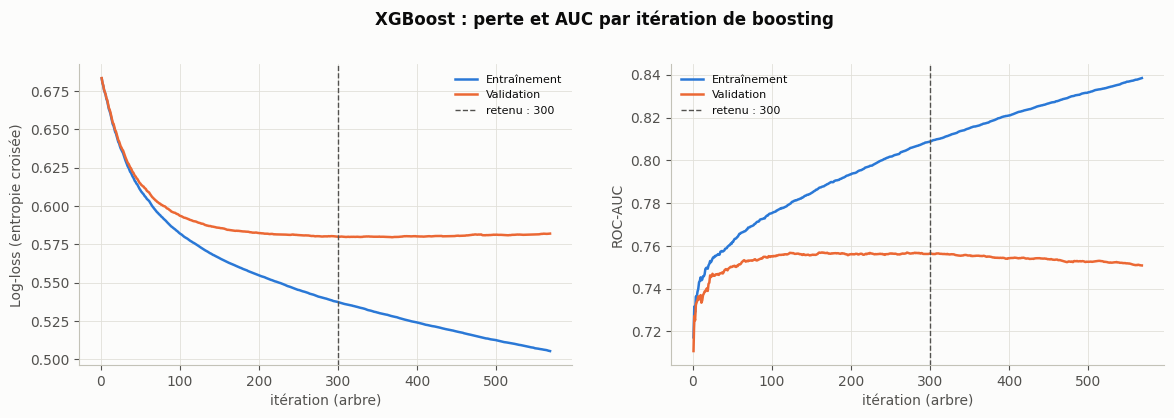

In [31]:
recherche_xgb = RandomizedSearchCV(
    Pipeline([('prep', construire_preprocesseur()),
              ('clf', xgb.XGBClassifier(objective='binary:logistic', tree_method='hist', eval_metric='logloss',
                                        random_state=SEED, n_jobs=1))]),
    {'clf__n_estimators': [100, 200, 300, 500, 800], 'clf__learning_rate': [0.01, 0.02, 0.05, 0.1],
     'clf__max_depth': [2, 3, 4, 5, 6], 'clf__min_child_weight': [1, 5, 10, 20], 'clf__subsample': [0.6, 0.8, 1.0],
     'clf__colsample_bytree': [0.5, 0.7, 1.0], 'clf__reg_lambda': [1, 5, 10, 20], 'clf__gamma': [0, 0.5, 1]},
    n_iter=40, scoring=SCORING, refit='pr_auc', cv=CV, random_state=SEED, n_jobs=-1).fit(X_train, y_train)
modeles['XGBoost'] = recherche_xgb.best_estimator_
params_xgb = {k.replace('clf__', ''): v for k, v in recherche_xgb.best_params_.items()}
print(f'Meilleurs hyperparamètres : {params_xgb} | PR-AUC CV = {recherche_xgb.best_score_:.3f}')

xgb_diag = xgb.XGBClassifier(**{k: v for k, v in params_xgb.items() if k != 'n_estimators'}, n_estimators=2000,
                             early_stopping_rounds=200, eval_metric=['auc', 'logloss'], objective='binary:logistic',
                             tree_method='hist', random_state=SEED, n_jobs=-1)
xgb_diag.fit(A_train, y_train, eval_set=[(A_train, y_train), (A_val, y_val)], verbose=False)
res = xgb_diag.evals_result()
historiques['XGBoost'] = pd.DataFrame({'itération (arbre)': np.arange(1, len(res['validation_0']['logloss']) + 1),
                                       'loss_train': res['validation_0']['logloss'], 'loss_val': res['validation_1']['logloss'],
                                       'auc_train': res['validation_0']['auc'], 'auc_val': res['validation_1']['auc']})
print(f"Optimum de la perte en validation : {xgb_diag.best_iteration + 1} arbres ; retenu par CV : {params_xgb['n_estimators']}")
tracer_courbes(historiques['XGBoost'], 'itération (arbre)', 'XGBoost : perte et AUC par itération de boosting',
               '13_courbes_xgb', marque=params_xgb['n_estimators'])

### 7.5 Réseau de neurones (MLP)
* **Architecture** : 2 couches cachées (32 puis 16 neurones, ReLU) et une sortie sigmoïde. Elle est volontairement petite, car 3 655 patients d'entraînement ne suffisent pas à nourrir un grand réseau.
* **Entraînement** : optimiseur Adam, mini-lots de 64, 300 epochs au plus.
* **Arrêt anticipé** : on garde les poids de l'epoch où la perte de validation est minimale (patience de 25 epochs).
* **Régularisation L2** (`alpha`) : 6 valeurs sont testées, de 0,001 à 10.

Ici, la validation sert à *régler* le réseau (arrêt anticipé et `alpha`). Ses scores de validation sont donc légèrement optimistes ; seul le jeu de test donne une estimation sans biais.

,meilleure epoch,log-loss validation,epochs effectuées
alpha,,,
0.001,12.000,0.592,37.000
0.010,11.000,0.592,36.000
0.100,14.000,0.590,39.000
1.000,26.000,0.585,51.000
3.000,219.000,0.610,244.000
10.000,5.000,0.680,30.000


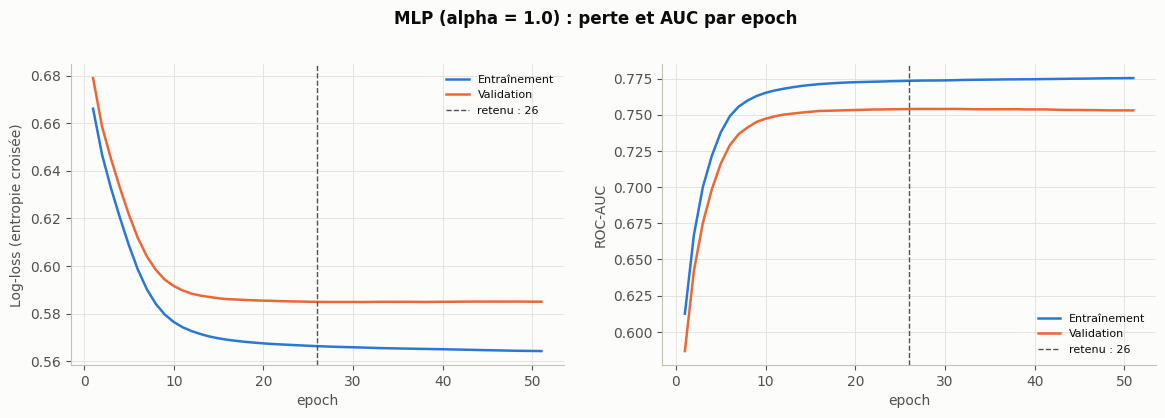

In [32]:
def entrainer_mlp(alpha, max_epochs=300, patience=25):
    mlp = MLPClassifier(hidden_layer_sizes=(32, 16), activation='relu', solver='adam', alpha=alpha,
                        batch_size=64, learning_rate_init=5e-4, random_state=SEED)
    hist, meilleur = [], (np.inf, None, 0)
    for epoch in range(1, max_epochs + 1):
        mlp.partial_fit(A_train, y_train.values, classes=np.array([0, 1]))
        p_tr, p_va = mlp.predict_proba(A_train)[:, 1], mlp.predict_proba(A_val)[:, 1]
        hist.append({'epoch': epoch, 'loss_train': log_loss(y_train, p_tr), 'loss_val': log_loss(y_val, p_va),
                     'auc_train': roc_auc_score(y_train, p_tr), 'auc_val': roc_auc_score(y_val, p_va)})
        if hist[-1]['loss_val'] < meilleur[0] - 1e-4:
            meilleur = (hist[-1]['loss_val'], copy.deepcopy(mlp), epoch)
        elif epoch - meilleur[2] >= patience:
            break
    return {'modele': meilleur[1], 'hist': pd.DataFrame(hist), 'epoch': meilleur[2], 'loss_val': meilleur[0]}


essais_mlp = {alpha: entrainer_mlp(alpha) for alpha in [1e-3, 1e-2, 1e-1, 1.0, 3.0, 10.0]}
display(pd.DataFrame({a: {'meilleure epoch': r['epoch'], 'log-loss validation': r['loss_val'],
                          'epochs effectuées': len(r['hist'])} for a, r in essais_mlp.items()}).T.rename_axis('alpha'))
ALPHA_OPT = min(essais_mlp, key=lambda a: essais_mlp[a]['loss_val'])
mlp_retenu = essais_mlp[ALPHA_OPT]
modeles['MLP'] = Pipeline([('prep', prep_fit), ('clf', mlp_retenu['modele'])])   # préprocesseur déjà appris sur l'entraînement
historiques['MLP'] = mlp_retenu['hist']
tracer_courbes(historiques['MLP'], 'epoch', f'MLP (alpha = {ALPHA_OPT}) : perte et AUC par epoch',
               '14_courbes_mlp', marque=mlp_retenu['epoch'])

### 7.6 Courbes d'apprentissage selon la taille de l'échantillon
Elles montrent si un modèle souffre plutôt de **biais** (les deux courbes sont proches et basses) ou de **variance** (grand écart entre entraînement et validation). Elles indiquent aussi si **davantage de données** améliorerait le modèle, ce qui est un argument pour la boucle d'apprentissage de VIHEPAT.

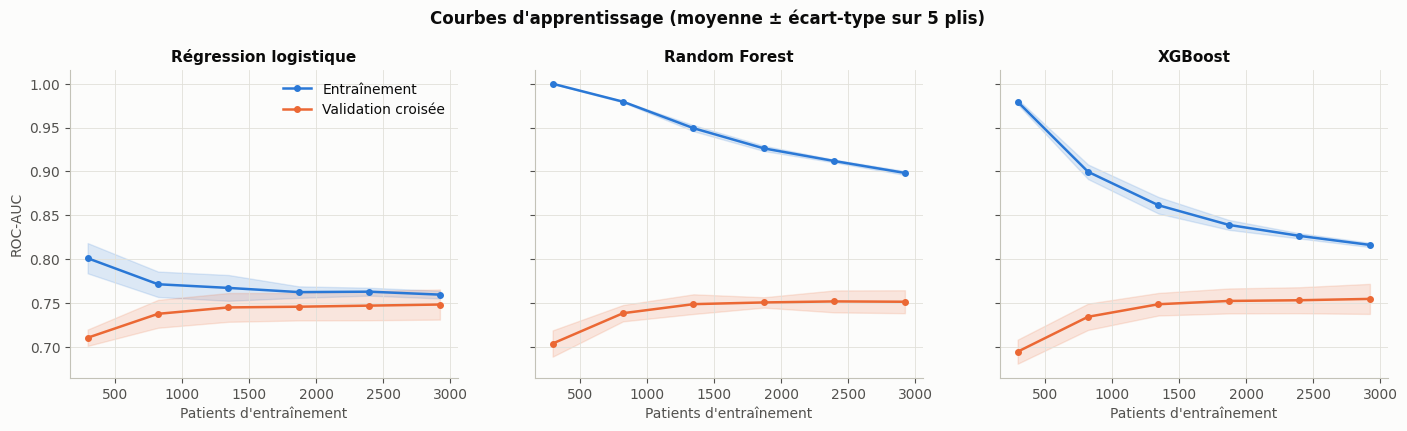

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, nom in zip(axes, ['Régression logistique', 'Random Forest', 'XGBoost']):
    tailles, sc_tr, sc_va = learning_curve(clone(modeles[nom]), X_train, y_train, cv=CV, scoring='roc_auc',
                                           train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, shuffle=True,
                                           random_state=SEED)
    for sc, couleur, etiquette in [(sc_tr, SERIES[0], 'Entraînement'), (sc_va, SERIES[1], 'Validation croisée')]:
        ax.plot(tailles, sc.mean(axis=1), 'o-', color=couleur, ms=4, label=etiquette)
        ax.fill_between(tailles, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), color=couleur, alpha=0.15)
    ax.set_title(nom)
    ax.set_xlabel("Patients d'entraînement")
axes[0].set_ylabel('ROC-AUC')
axes[0].legend()
fig.suptitle("Courbes d'apprentissage (moyenne ± écart-type sur 5 plis)", y=1.03, fontweight='bold')
savefig(fig, '15_courbes_apprentissage')
plt.show()

**Interprétation des courbes de perte et d'apprentissage.**
* **Régression logistique (SGD)** : la perte converge en une dizaine d'epochs vers la solution L-BFGS (pointillés), puis se stabilise sur l'entraînement comme sur la validation. L'écart entre les deux reste faible (0,576 contre 0,587) : **pas de surapprentissage**, ce qui est attendu pour un modèle linéaire régularisé.
* **Random Forest** : la perte de validation se stabilise dès environ 100 arbres ; 400 arbres est donc un choix sûr. L'écart entre entraînement (AUC 0,88) et validation (0,755) indique une **variance** notable, contenue par la profondeur limitée (8).
* **XGBoost** : l'optimum de la perte de validation (368 arbres) est proche du choix de la validation croisée (300). La perte d'entraînement continue de baisser alors que celle de validation stagne : au-delà, le modèle **mémoriserait** les patients d'entraînement.
* **MLP** : avec une régularisation faible (alpha ≤ 0,1), le réseau surapprend dès la 12ᵉ epoch environ. La meilleure configuration (alpha = 1) s'arrête à l'epoch 26 avec un écart réduit entre entraînement et validation. Trop de régularisation (alpha = 10) l'empêche au contraire d'apprendre.
* **Courbes d'apprentissage** : pour la régression logistique, entraînement et validation se rejoignent vers 0,75 : le modèle est limité par **le biais**, c'est-à-dire par l'information contenue dans les variables, et non par le nombre de patients. Les arbres gardent un écart (variance), mais leur validation plafonne au même niveau.

➡️ **Ajouter des patients du même type n'améliorera pas beaucoup le modèle ; ajouter de nouveaux *types* de variables, si.** Les données de suivi dynamiques (rendez-vous honorés, délais depuis le dernier contact, réponses aux relances) sont exactement ce que VIHEPAT collectera.

### 7.7 Analyse de survie : modèle de Cox
Le modèle de Cox estime des **hazard ratios** (HR), qui traduisent l'effet de chaque facteur sur la *vitesse* de sortie du parcours de soins. Il prend naturellement en compte les différences de durée de suivi, ce qui en fait un complément à la question binaire. On compare ensuite nos résultats à ceux de l'article, qui identifie le statut marital comme facteur associé : célibataire HR 1,21, divorcé/séparé/veuf HR 1,30, avec marié comme référence.

* **Durée** : `MonthsInCare` + 0,5 mois (contact au cours du mois). **Évènement** : LTFU.
* **Références** : femme, marié(e), études secondaires, stade OMS 1. Les valeurs continuelles manquantes sont remplacées par la médiane de l'entraînement.
* Une pénalisation légère (0,01) stabilise les estimations face aux variables corrélées.

C-index : entraînement = 0.715 | validation = 0.721


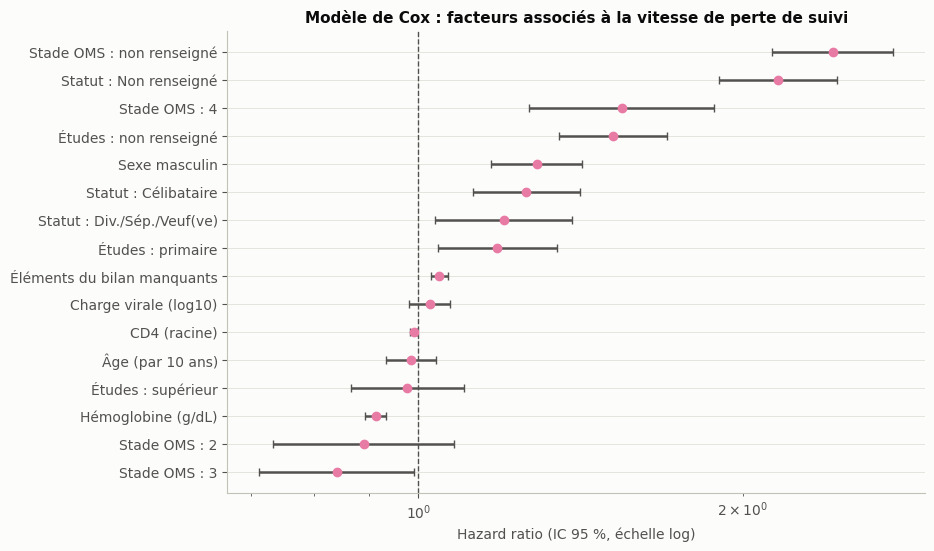

,HR,IC95 bas,IC95 haut,p
covariate,,,,
Âge (par 10 ans),0.984,0.933,1.038,5.6e-01
Sexe masculin,1.287,1.167,1.420,4.5e-07
Statut : Célibataire,1.260,1.124,1.412,7.3e-05
Statut : Div./Sép./Veuf(ve),1.200,1.037,1.389,1.4e-02
Statut : Non renseigné,2.155,1.900,2.444,6.6e-33
Études : primaire,1.183,1.042,1.343,9.3e-03
Études : supérieur,0.977,0.865,1.103,7.1e-01
Études : non renseigné,1.516,1.351,1.701,1.5e-12
Stade OMS : 2,0.890,0.733,1.080,2.4e-01


In [34]:
MED_COX = X_train[['Age', 'sqrt_CD4', 'log10_CV', 'Hemoglob']].median()


def design_cox(idx):
    d = df_model.loc[idx]
    Z = pd.DataFrame(index=idx)
    Z['Âge (par 10 ans)'] = d['Age'].fillna(MED_COX['Age']) / 10
    Z['Sexe masculin'] = (d['Sex'] == 'Male').astype(int)
    statut = d['MaritalStatus'].map(GROUPES_MARITAL).fillna('Non renseigné')
    for g in ['Célibataire', 'Div./Sép./Veuf(ve)', 'Non renseigné']:
        Z[f'Statut : {g}'] = (statut == g).astype(int)
    etudes = d['Education'].fillna('Inconnu')
    for g in ['Primary', 'Tertiary', 'Inconnu']:
        Z[f'Études : {TRAD[g]}'] = (etudes == g).astype(int)
    stade = d['WHOStage'].fillna('Inconnu')
    for g in ['2', '3', '4', 'Inconnu']:
        Z[f'Stade OMS : {TRAD.get(g, g)}'] = (stade == g).astype(int)
    Z['CD4 (racine)'] = d['sqrt_CD4'].fillna(MED_COX['sqrt_CD4'])
    Z['Charge virale (log10)'] = d['log10_CV'].fillna(MED_COX['log10_CV'])
    Z['Hémoglobine (g/dL)'] = d['Hemoglob'].fillna(MED_COX['Hemoglob'])
    Z['Éléments du bilan manquants'] = d['nb_examens_manquants']
    Z['duree'] = d['MonthsInCare'] + 0.5
    Z['evenement'] = d['LTFU']
    return Z


Z_train, Z_val, Z_test = design_cox(idx_train), design_cox(idx_val), design_cox(idx_test)
cox = CoxPHFitter(penalizer=0.01).fit(Z_train, duration_col='duree', event_col='evenement')
resume_cox = cox.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']].rename(
    columns={'exp(coef)': 'HR', 'exp(coef) lower 95%': 'IC95 bas', 'exp(coef) upper 95%': 'IC95 haut'})
print(f"C-index : entraînement = {cox.concordance_index_:.3f} | validation = "
      f"{cox.score(Z_val, scoring_method='concordance_index'):.3f}")

fig, ax = plt.subplots(figsize=(9, 6))
r = resume_cox.sort_values('HR')
ax.errorbar(r['HR'], range(len(r)), xerr=[r['HR'] - r['IC95 bas'], r['IC95 haut'] - r['HR']], fmt='o',
            color=COULEUR['Cox'], ecolor=INK2, capsize=3, ms=6)
ax.axvline(1, color=INK2, ls='--', lw=1)
ax.set_yticks(range(len(r)), r.index)
ax.set_xscale('log')
ax.set_xlabel('Hazard ratio (IC 95 %, échelle log)')
ax.set_title('Modèle de Cox : facteurs associés à la vitesse de perte de suivi')
savefig(fig, '16_cox_hazard_ratios')
plt.show()
resume_cox.assign(p=resume_cox['p'].map(lambda v: f'{v:.1e}'))

In [35]:
# Comparaison avec l'article (modèle multivarié sur 3 603 patients à données complètes)
comparaison = pd.DataFrame({
    'HR article (IC 95 %)': ['1,21 (1,08-1,36)', '1,30 (1,12-1,50)'],
    'HR notre modèle (IC 95 %)': [f"{resume_cox.loc[k, 'HR']:.2f} ({resume_cox.loc[k, 'IC95 bas']:.2f}-{resume_cox.loc[k, 'IC95 haut']:.2f})"
                                  for k in ['Statut : Célibataire', 'Statut : Div./Sép./Veuf(ve)']]},
    index=['Célibataire vs marié(e)', 'Divorcé/séparé/veuf vs marié(e)'])
display(comparaison)

# Hypothèse des risques proportionnels (test des résidus de Schoenfeld)
test_ph = proportional_hazard_test(cox, Z_train, time_transform='rank').summary
print(f"Variables violant l'hypothèse des risques proportionnels (p < 0,05) : {(test_ph['p'] < 0.05).sum()} / {len(test_ph)}")
test_ph.sort_values('p').head(8).assign(p=lambda t: t['p'].map(lambda v: f'{v:.1e}'))

,HR article (IC 95 %),HR notre modèle (IC 95 %)
Célibataire vs marié(e),"1,21 (1,08-1,36)",1.26 (1.12-1.41)
Divorcé/séparé/veuf vs marié(e),"1,30 (1,12-1,50)",1.20 (1.04-1.39)


Variables violant l'hypothèse des risques proportionnels (p < 0,05) : 5 / 16


,test_statistic,p,-log2(p)
CD4 (racine),10.833,1.0e-03,9.970
Stade OMS : non renseigné,9.238,2.4e-03,8.721
Hémoglobine (g/dL),4.928,2.6e-02,5.242
Charge virale (log10),4.525,3.3e-02,4.904
Stade OMS : 4,4.279,3.9e-02,4.695
Âge (par 10 ans),3.180,7.5e-02,3.746
Études : primaire,1.376,2.4e-01,2.055
Éléments du bilan manquants,1.246,2.6e-01,1.919


**Interprétation du modèle de Cox.**
* **Réplication de l'article** : célibataire HR 1,26 [1,12-1,41] (article : 1,21) ; divorcé/séparé/veuf HR 1,20 [1,04-1,39] (article : 1,30). Les intervalles de confiance se recouvrent : **nous retrouvons le résultat publié**, malgré un ajustement plus large et des données imputées.
* Les autres facteurs associés à une sortie plus rapide sont le **sexe masculin** (HR 1,29), le **stade OMS 4** (HR 1,54), une **hémoglobine basse** (HR 0,91 par g/dL supplémentaire) et surtout les **informations non renseignées** : stade OMS (HR 2,42), statut marital (HR 2,16) et études (HR 1,52).
* Le stade 4 et l'anémie suggèrent qu'une partie des « perdus de vue » sont des **patients gravement malades, dont certains sont décédés sans que le décès soit enregistré**. L'article a d'ailleurs retrouvé 16 % de décès parmi les patients tracés.
* **Limite** : l'hypothèse des risques proportionnels est rejetée pour 5 covariables sur 16 (CD4, stade non renseigné, hémoglobine, charge virale, stade 4). Leur effet est concentré sur les premières semaines, quand la plupart des sorties ont lieu. Les HR doivent donc se lire comme des **effets moyens** sur la période.
* C-index de 0,72 en validation et 0,72 en test : une discrimination comparable à celle des classifieurs.

## 8. Comparaison des modèles et choix du modèle final

### 8.1 Validation croisée (entraînement) et jeu de validation

In [36]:
cv_resume = pd.DataFrame({nom: {'PR-AUC CV (moyenne)': r.cv_results_['mean_test_pr_auc'][r.best_index_],
                               'PR-AUC CV (écart-type)': r.cv_results_['std_test_pr_auc'][r.best_index_],
                               'ROC-AUC CV (moyenne)': r.cv_results_['mean_test_roc_auc'][r.best_index_],
                               'ROC-AUC CV (écart-type)': r.cv_results_['std_test_roc_auc'][r.best_index_]}
                          for nom, r in [('Régression logistique', grille_lr), ('Random Forest', recherche_rf),
                                         ('XGBoost', recherche_xgb)]}).T
display(cv_resume)

p_val = {nom: modeles[nom].predict_proba(X_val)[:, 1] for nom in NOMS_MODELES}
risque_cox_val = cox.predict_partial_hazard(Z_val).values
tab_val = pd.DataFrame({nom: metriques(y_val, p) for nom, p in p_val.items()}).T
tab_val.loc['Cox (score de risque)'] = {'ROC-AUC': roc_auc_score(y_val, risque_cox_val),
                                         'PR-AUC': average_precision_score(y_val, risque_cox_val)}
print('Jeu de validation (métriques à seuil calculées à 0,5) :')
tab_val

,PR-AUC CV (moyenne),PR-AUC CV (écart-type),ROC-AUC CV (moyenne),ROC-AUC CV (écart-type)
Régression logistique,0.801,0.018,0.748,0.018
Random Forest,0.809,0.015,0.751,0.014
XGBoost,0.811,0.015,0.753,0.016


Jeu de validation (métriques à seuil calculées à 0,5) :


,ROC-AUC,PR-AUC,Brier,Log-loss,Sensibilité,Spécificité,VPP,VPN,F1,F2
Référence naïve,0.500,0.558,0.247,0.686,1.000,0.000,0.558,NaN,0.716,0.863
Régression logistique,0.748,0.792,0.202,0.587,0.725,0.659,0.728,0.655,0.727,0.726
Random Forest,0.755,0.796,0.200,0.582,0.719,0.670,0.733,0.654,0.726,0.722
XGBoost,0.757,0.798,0.199,0.579,0.721,0.683,0.741,0.659,0.731,0.725
MLP,0.754,0.791,0.200,0.585,0.726,0.662,0.731,0.657,0.729,0.727
Cox (score de risque),0.738,0.783,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


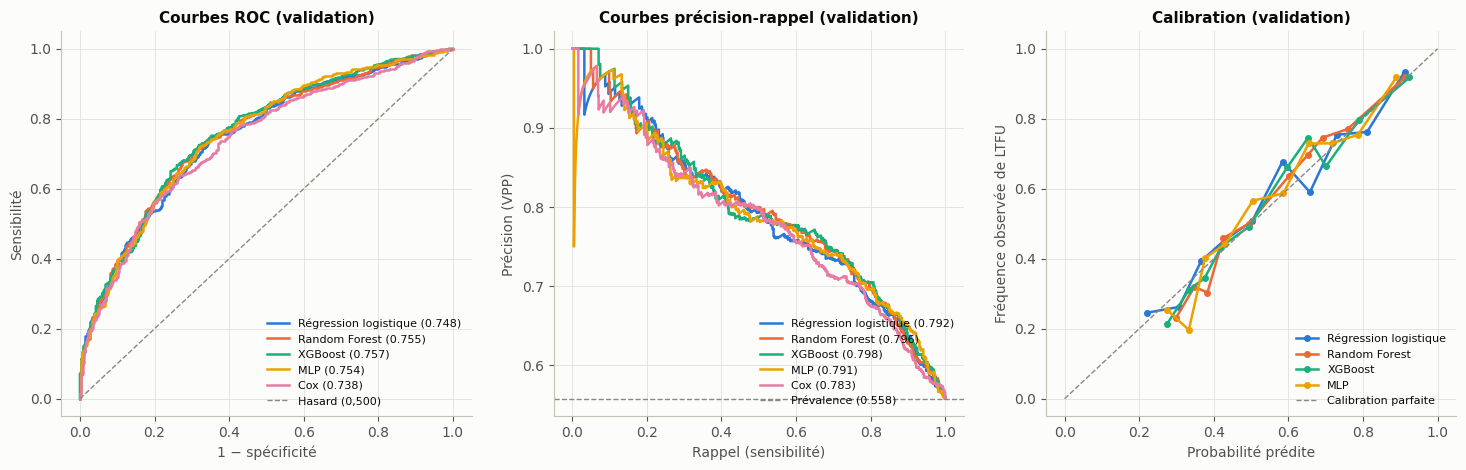

In [37]:
p_courbes = {**{n: p_val[n] for n in NOMS_MODELES[1:]}, 'Cox': risque_cox_val}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for nom, p in p_courbes.items():
    fpr, tpr, _ = roc_curve(y_val, p)
    axes[0].plot(fpr, tpr, color=COULEUR[nom], label=f'{nom} ({roc_auc_score(y_val, p):.3f})')
    prec, rec, _ = precision_recall_curve(y_val, p)
    axes[1].plot(rec, prec, color=COULEUR[nom], label=f'{nom} ({average_precision_score(y_val, p):.3f})')
axes[0].plot([0, 1], [0, 1], color=MUTED, ls='--', lw=1, label='Hasard (0,500)')
axes[0].set(xlabel='1 − spécificité', ylabel='Sensibilité', title='Courbes ROC (validation)')
axes[1].axhline(y_val.mean(), color=MUTED, ls='--', lw=1, label=f'Prévalence ({y_val.mean():.3f})')
axes[1].set(xlabel='Rappel (sensibilité)', ylabel='Précision (VPP)', title='Courbes précision-rappel (validation)')
for nom in NOMS_MODELES[1:]:
    frac, moy = calibration_curve(y_val, p_val[nom], n_bins=10, strategy='quantile')
    axes[2].plot(moy, frac, 'o-', ms=4, color=COULEUR[nom], label=nom)
axes[2].plot([0, 1], [0, 1], color=MUTED, ls='--', lw=1, label='Calibration parfaite')
axes[2].set(xlabel='Probabilité prédite', ylabel='Fréquence observée de LTFU', title='Calibration (validation)')
for ax in axes:
    ax.legend(fontsize=8, loc='lower right')
savefig(fig, '17_comparaison_validation')
plt.show()

### 8.2 Les écarts sont-ils significatifs ? Bootstrap apparié
On rééchantillonne 1 000 fois les patients de validation. Pour chaque tirage, on calcule l'écart entre chaque modèle et la régression logistique *sur les mêmes patients*. Si l'intervalle à 95 % contient 0, l'écart n'est pas significatif.

In [38]:
def bootstrap_diff(y_vrai, p1, p2, fn, n=1000, seed=SEED):
    r, y_vrai, ecarts = np.random.default_rng(seed), np.asarray(y_vrai), []
    for _ in range(n):
        i = r.integers(0, len(y_vrai), len(y_vrai))
        ecarts.append(fn(y_vrai[i], p1[i]) - fn(y_vrai[i], p2[i]))
    return np.mean(ecarts), *np.percentile(ecarts, [2.5, 97.5])


ecarts = []
for nom in ['Random Forest', 'XGBoost', 'MLP']:
    for metrique, fn in [('PR-AUC', average_precision_score), ('ROC-AUC', auc_roc)]:
        m, bas, haut = bootstrap_diff(y_val, p_val[nom], p_val['Régression logistique'], fn)
        ecarts.append({'modèle': nom, 'métrique': metrique, 'écart vs régression logistique': m,
                       'IC95 bas': bas, 'IC95 haut': haut, 'significatif': 'oui' if bas > 0 or haut < 0 else 'non'})
ecarts = pd.DataFrame(ecarts).set_index(['modèle', 'métrique'])
ecarts

écart vs régression logistique  IC95 bas  IC95 haut significatif
modèle        métrique                                                                  
Random Forest PR-AUC                             0.004    -0.009      0.017          non
              ROC-AUC                            0.006    -0.006      0.018          non
XGBoost       PR-AUC                             0.006    -0.005      0.017          non
              ROC-AUC                            0.008    -0.003      0.019          non
MLP           PR-AUC                            -0.001    -0.009      0.006          non
              ROC-AUC                            0.005    -0.000      0.011          non

In [39]:
# Application de la règle de sélection déclarée en 6.1
candidats = ['Régression logistique', 'Random Forest', 'XGBoost', 'MLP']
meilleur = max(candidats, key=lambda n: tab_val.loc[n, 'PR-AUC'])
if meilleur != 'Régression logistique' and ecarts.loc[(meilleur, 'PR-AUC'), 'IC95 bas'] > 0:
    NOM_FINAL = meilleur
    raison = f"PR-AUC de validation la plus élevée et gain significatif sur la régression logistique"
else:
    NOM_FINAL = 'Régression logistique'
    raison = ('meilleur modèle' if meilleur == 'Régression logistique'
              else f"{meilleur} n'apporte pas de gain significatif : parcimonie")
modele_final = modeles[NOM_FINAL]
print(f'Meilleure PR-AUC de validation : {meilleur} ({tab_val.loc[meilleur, "PR-AUC"]:.3f})')
print(f'MODÈLE FINAL : {NOM_FINAL} ({raison})')

Meilleure PR-AUC de validation : XGBoost (0.798)
MODÈLE FINAL : Régression logistique (XGBoost n'apporte pas de gain significatif : parcimonie)


### 8.3 Choix du seuil de décision (sur la validation)
* **Seuil d'alerte** : le plus élevé qui garantit une sensibilité ≥ 80 % (règle 6.1).
* **Seuil « risque élevé »** : le plus bas à partir duquel au moins 85 % des patients signalés sont réellement perdus de vue, la précision restant ≥ 85 % pour tous les seuils supérieurs. Ce seuil sert à afficher trois niveaux dans VIHEPAT : **faible**, **modéré**, **élevé**.

Seuil d'alerte (sensibilité ≥ 80 %) : 0.422 | seuil maximisant F1 : 0.370 | seuil « risque élevé » : 0.77


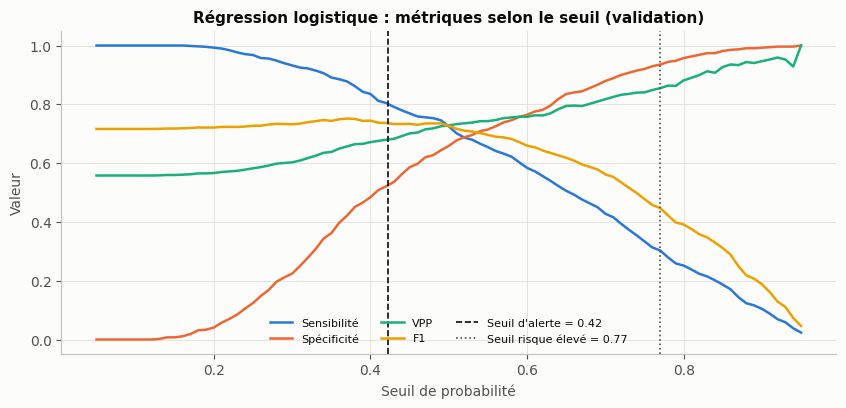

,ROC-AUC,PR-AUC,Brier,Log-loss,Sensibilité,Spécificité,VPP,VPN,F1,F2
seuil alerte (0.42),0.748,0.792,0.202,0.587,0.800,0.527,0.681,0.676,0.736,0.773
seuil F1 (0.37),0.748,0.792,0.202,0.587,0.878,0.423,0.657,0.733,0.752,0.823
"seuil 0,50",0.748,0.792,0.202,0.587,0.725,0.659,0.728,0.655,0.727,0.726


In [40]:
OBJECTIF_SENSIBILITE, OBJECTIF_PRECISION_ELEVE = 0.80, 0.85
p_val_final = p_val[NOM_FINAL]
prec, rec, seuils = precision_recall_curve(y_val, p_val_final)
SEUIL = float(seuils[rec[:-1] >= OBJECTIF_SENSIBILITE].max())
f1_par_seuil = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
SEUIL_F1 = float(seuils[f1_par_seuil.argmax()])

grille = np.round(np.arange(0.30, 0.99, 0.01), 2)
prec_grille = pd.Series({t: y_val[p_val_final >= t].mean() for t in grille
                         if (p_val_final >= t).sum() >= 30})
ok = (prec_grille >= OBJECTIF_PRECISION_ELEVE).astype(int)[::-1].cummin()[::-1].astype(bool)  # précision ≥ 85 % pour tous les seuils supérieurs
SEUIL_ELEVE = float(prec_grille.index[ok.values].min()) if ok.any() else None


def niveau_risque(p):
    if SEUIL_ELEVE is not None and p >= SEUIL_ELEVE:
        return 'élevé'
    return 'modéré' if p >= SEUIL else 'faible'


print(f'Seuil d\'alerte (sensibilité ≥ 80 %) : {SEUIL:.3f} | seuil maximisant F1 : {SEUIL_F1:.3f} '
      f'| seuil « risque élevé » : {SEUIL_ELEVE}')

grille_fine = np.linspace(0.05, 0.95, 91)
courbe = pd.DataFrame([metriques(y_val, p_val_final, t) for t in grille_fine], index=grille_fine)
fig, ax = plt.subplots(figsize=(10, 4.2))
for m, couleur in [('Sensibilité', SERIES[0]), ('Spécificité', SERIES[1]), ('VPP', SERIES[2]), ('F1', SERIES[3])]:
    ax.plot(courbe.index, courbe[m], color=couleur, label=m)
ax.axvline(SEUIL, color=INK, ls='--', lw=1.2, label=f'Seuil d\'alerte = {SEUIL:.2f}')
if SEUIL_ELEVE is not None:
    ax.axvline(SEUIL_ELEVE, color=INK2, ls=':', lw=1.2, label=f'Seuil risque élevé = {SEUIL_ELEVE:.2f}')
ax.set(xlabel='Seuil de probabilité', ylabel='Valeur', title=f'{NOM_FINAL} : métriques selon le seuil (validation)')
ax.legend(fontsize=8, ncol=3, loc='lower center')
savefig(fig, '18_choix_seuil')
plt.show()
pd.DataFrame({f'seuil alerte ({SEUIL:.2f})': metriques(y_val, p_val_final, SEUIL),
              f'seuil F1 ({SEUIL_F1:.2f})': metriques(y_val, p_val_final, SEUIL_F1),
              'seuil 0,50': metriques(y_val, p_val_final, 0.5)}).T

**Interprétation de la comparaison.**
* Les quatre modèles appris sont **très proches** : ROC-AUC de 0,748 à 0,757 et PR-AUC de 0,791 à 0,798 en validation. Tous dépassent nettement la référence naïve (PR-AUC 0,558) et sont **bien calibrés**, leurs courbes de calibration suivant la diagonale.
* Le bootstrap apparié montre qu'**aucun écart avec la régression logistique n'est significatif** : tous les intervalles à 95 % contiennent 0. Par la règle de parcimonie déclarée en 6.1, le **modèle final est la régression logistique**. Elle est la plus simple, la plus stable, directement interprétable en odds ratios et la plus facile à intégrer dans le back-end de VIHEPAT.
* *Leçon méthodologique* : dans une première version, l'âge était imputé par la médiane et XGBoost semblait nettement supérieur (PR-AUC en validation croisée 0,850, contre 0,811 aujourd'hui). Son avantage venait **entièrement de l'artefact de l'âge manquant**, qu'il savait repérer (section 5.2). Une fois l'artefact neutralisé, la supériorité disparaît.
* **Seuil** : 0,42 garantit une sensibilité de 80 % en validation, pour une spécificité de 53 % et une VPP de 68 %. Le seuil « risque élevé » (0,77) isole un groupe où au moins 85 % des patients signalés décrochent réellement.

## 9. Évaluation finale sur le jeu de test
Le jeu de test n'a servi à **aucune** décision jusqu'ici. Les intervalles de confiance à 95 % sont obtenus par bootstrap (1 000 rééchantillonnages).

In [41]:
def bootstrap_metriques(y_vrai, p, seuil, n=1000, seed=SEED):
    r, y_vrai, p = np.random.default_rng(seed), np.asarray(y_vrai), np.asarray(p)
    tirages = []
    for _ in range(n):
        i = r.integers(0, len(y_vrai), len(y_vrai))
        tirages.append(metriques(y_vrai[i], p[i], seuil))
    return pd.DataFrame(tirages).quantile([0.025, 0.975]).T


p_test = {nom: modeles[nom].predict_proba(X_test)[:, 1] for nom in NOMS_MODELES}
risque_cox_test = cox.predict_partial_hazard(Z_test).values
p_final_test = p_test[NOM_FINAL]

ic_test = bootstrap_metriques(y_test, p_final_test, SEUIL)
resultats_test = pd.DataFrame({'valeur': pd.Series(metriques(y_test, p_final_test, SEUIL)),
                               'IC95 bas': ic_test[0.025], 'IC95 haut': ic_test[0.975]})
print(f'{NOM_FINAL} sur le jeu de test (n = {len(y_test)}, seuil d\'alerte = {SEUIL:.3f}) :')
display(resultats_test)

tab_test = pd.DataFrame({nom: {k: v for k, v in metriques(y_test, p).items() if k in ('ROC-AUC', 'PR-AUC', 'Brier')}
                         for nom, p in p_test.items()}).T
tab_test.loc['Cox (score de risque)'] = {'ROC-AUC': roc_auc_score(y_test, risque_cox_test),
                                          'PR-AUC': average_precision_score(y_test, risque_cox_test)}
print(f"C-index du modèle de Cox sur le test : {cox.score(Z_test, scoring_method='concordance_index'):.3f}")
print('Transparence : tous les modèles sur le test (aucun choix ne repose sur ce tableau) :')
tab_test

Régression logistique sur le jeu de test (n = 1219, seuil d'alerte = 0.422) :


,valeur,IC95 bas,IC95 haut
ROC-AUC,0.765,0.738,0.789
PR-AUC,0.817,0.790,0.844
Brier,0.195,0.186,0.205
Log-loss,0.570,0.550,0.593
Sensibilité,0.814,0.782,0.842
Spécificité,0.532,0.493,0.570
VPP,0.687,0.655,0.718
VPN,0.692,0.648,0.734
F1,0.745,0.719,0.769
F2,0.785,0.757,0.811


C-index du modèle de Cox sur le test : 0.723
Transparence : tous les modèles sur le test (aucun choix ne repose sur ce tableau) :


,ROC-AUC,PR-AUC,Brier
Référence naïve,0.500,0.559,0.247
Régression logistique,0.765,0.817,0.195
Random Forest,0.765,0.817,0.196
XGBoost,0.772,0.820,0.193
MLP,0.767,0.819,0.195
Cox (score de risque),0.744,0.803,NaN


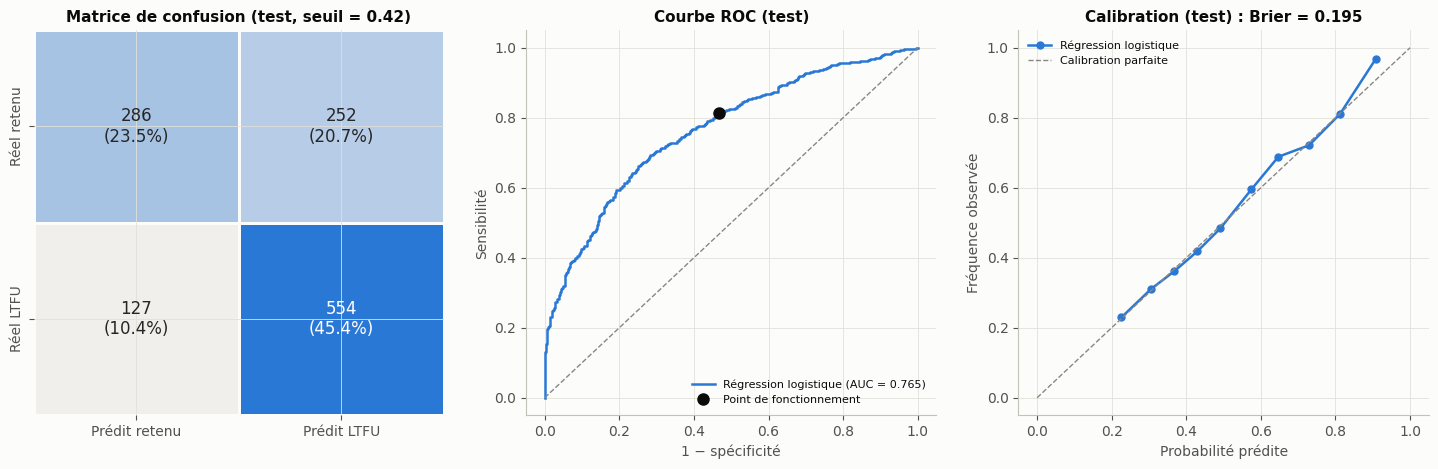

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cm = confusion_matrix(y_test, (p_final_test >= SEUIL).astype(int))
sns.heatmap(cm, annot=np.array([[f'{v}\n({v / cm.sum():.1%})' for v in ligne] for ligne in cm]), fmt='',
            cmap=LinearSegmentedColormap.from_list('seq', ['#f0efec', '#2a78d6']), cbar=False, ax=axes[0],
            xticklabels=['Prédit retenu', 'Prédit LTFU'], yticklabels=['Réel retenu', 'Réel LTFU'],
            annot_kws={'size': 12}, linewidths=2, linecolor=SURFACE)
axes[0].set_title(f'Matrice de confusion (test, seuil = {SEUIL:.2f})')

fpr, tpr, _ = roc_curve(y_test, p_final_test)
axes[1].plot(fpr, tpr, color=COULEUR[NOM_FINAL], label=f'{NOM_FINAL} (AUC = {roc_auc_score(y_test, p_final_test):.3f})')
if NOM_FINAL != 'Régression logistique':
    fpr2, tpr2, _ = roc_curve(y_test, p_test['Régression logistique'])
    axes[1].plot(fpr2, tpr2, color=COULEUR['Régression logistique'], lw=1.2,
                 label=f"Régression logistique (AUC = {roc_auc_score(y_test, p_test['Régression logistique']):.3f})")
axes[1].plot([0, 1], [0, 1], color=MUTED, ls='--', lw=1)
pt = metriques(y_test, p_final_test, SEUIL)
axes[1].plot(1 - pt['Spécificité'], pt['Sensibilité'], 'o', color=INK, ms=8, label='Point de fonctionnement')
axes[1].set(xlabel='1 − spécificité', ylabel='Sensibilité', title='Courbe ROC (test)')
axes[1].legend(fontsize=8, loc='lower right')

frac, moy = calibration_curve(y_test, p_final_test, n_bins=10, strategy='quantile')
axes[2].plot(moy, frac, 'o-', color=COULEUR[NOM_FINAL], ms=5, label=NOM_FINAL)
axes[2].plot([0, 1], [0, 1], color=MUTED, ls='--', lw=1, label='Calibration parfaite')
axes[2].set(xlabel='Probabilité prédite', ylabel='Fréquence observée',
            title=f"Calibration (test) : Brier = {brier_score_loss(y_test, p_final_test):.3f}")
axes[2].legend(fontsize=8)
savefig(fig, '19_evaluation_test')
plt.show()

### 9.1 Utilité clinique : courbe de décision et rappel selon la capacité de relance
* **Courbe de décision** : le *bénéfice net* soustrait aux vrais positifs les faux positifs, pondérés par le seuil de probabilité. Le seuil représente l'arbitrage du soignant : « je relance si le risque dépasse *p* ». Un modèle est utile là où sa courbe dépasse à la fois « relancer tout le monde » et « ne relancer personne ».
* **Capacité de relance** : un centre ne peut pas appeler tout le monde. Si l'on appelle les *k* % de patients les plus à risque, quelle part des futurs perdus de vue atteint-on ?

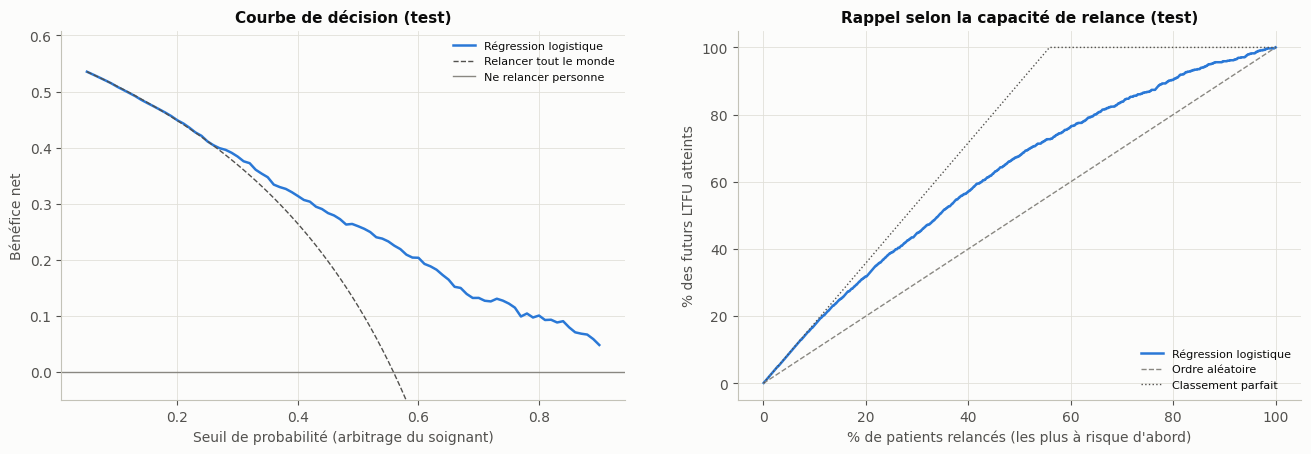

,patients relancés,% des LTFU atteints,précision (LTFU parmi relancés),gain vs hasard (×)
% relancés,,,,
10%,122,17.327,96.721,1.731
20%,244,31.865,88.934,1.592
30%,366,44.787,83.333,1.492
40%,488,57.122,79.713,1.427
50%,610,67.841,75.738,1.356


In [43]:
def benefice_net(y_vrai, p, seuil):
    y_vrai, signale, n = np.asarray(y_vrai), np.asarray(p) >= seuil, len(y_vrai)
    vp, fp = (signale & (y_vrai == 1)).sum(), (signale & (y_vrai == 0)).sum()
    return vp / n - fp / n * seuil / (1 - seuil)


seuils_dca = np.linspace(0.05, 0.90, 86)
prev = y_test.mean()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
axes[0].plot(seuils_dca, [benefice_net(y_test, p_final_test, s) for s in seuils_dca], color=COULEUR[NOM_FINAL], label=NOM_FINAL)
if NOM_FINAL != 'Régression logistique':
    axes[0].plot(seuils_dca, [benefice_net(y_test, p_test['Régression logistique'], s) for s in seuils_dca],
                 color=COULEUR['Régression logistique'], lw=1.2, label='Régression logistique')
axes[0].plot(seuils_dca, prev - (1 - prev) * seuils_dca / (1 - seuils_dca), color=INK2, ls='--', lw=1, label='Relancer tout le monde')
axes[0].axhline(0, color=MUTED, lw=1, label='Ne relancer personne')
axes[0].set_ylim(-0.05, prev + 0.05)
axes[0].set(xlabel='Seuil de probabilité (arbitrage du soignant)', ylabel='Bénéfice net', title='Courbe de décision (test)')
axes[0].legend(fontsize=8)

ordre = np.argsort(-p_final_test)
y_trie = y_test.values[ordre]
part = np.arange(1, len(y_trie) + 1) / len(y_trie)
axes[1].plot(100 * part, 100 * np.cumsum(y_trie) / y_trie.sum(), color=COULEUR[NOM_FINAL], label=NOM_FINAL)
axes[1].plot([0, 100], [0, 100], color=MUTED, ls='--', lw=1, label='Ordre aléatoire')
axes[1].plot(100 * np.minimum(part, 1), 100 * np.minimum(part / prev, 1), color=INK2, ls=':', lw=1, label='Classement parfait')
axes[1].set(xlabel='% de patients relancés (les plus à risque d\'abord)', ylabel='% des futurs LTFU atteints',
            title='Rappel selon la capacité de relance (test)')
axes[1].legend(fontsize=8, loc='lower right')
savefig(fig, '20_utilite_clinique')
plt.show()

capacite = []
for k in [0.10, 0.20, 0.30, 0.40, 0.50]:
    n_k = int(round(k * len(y_trie)))
    capacite.append({'% relancés': f'{k:.0%}', 'patients relancés': n_k,
                     '% des LTFU atteints': 100 * y_trie[:n_k].sum() / y_trie.sum(),
                     'précision (LTFU parmi relancés)': 100 * y_trie[:n_k].mean(),
                     'gain vs hasard (×)': y_trie[:n_k].mean() / prev})
pd.DataFrame(capacite).set_index('% relancés')

In [44]:
# Niveaux de risque affichés dans VIHEPAT : fréquence observée de LTFU par niveau (test)
niveaux = pd.Series([niveau_risque(p) for p in p_final_test], index=X_test.index)
pd.DataFrame({'patients': niveaux.value_counts(), '% des patients': 100 * niveaux.value_counts(normalize=True),
              '% réellement perdus de vue': 100 * y_test.groupby(niveaux).mean()}).reindex(['faible', 'modéré', 'élevé'])

,patients,% des patients,% réellement perdus de vue
faible,413,33.880,30.751
modéré,559,45.857,60.107
élevé,247,20.263,88.259


**Interprétation de l'évaluation finale.**
* Sur des patients **jamais vus**, la régression logistique obtient une **ROC-AUC de 0,765** [0,738-0,789] et une **PR-AUC de 0,817** [0,790-0,844]. C'est légèrement mieux qu'en validation (0,748), ce qui reste compatible avec la variabilité d'échantillonnage : les intervalles se recouvrent. Les autres modèles confirment sur le test qu'ils sont équivalents (ROC-AUC de 0,765 à 0,772).
* Au seuil d'alerte, le modèle détecte **81 % des futurs perdus de vue**, et 69 % des patients signalés le seront réellement. La contrepartie est une spécificité de 53 % : **près de la moitié des patients qui resteront en soins sont aussi signalés**. Le score ne doit donc pas servir de filtre binaire, mais d'**outil de priorisation**.
* **C'est la priorisation qui crée la valeur.** En relançant d'abord les 10 % de patients les plus à risque, 97 % des appels touchent un futur perdu de vue ; à 20 %, la précision est encore de 89 % (contre 56 % au hasard, soit 1,6 fois mieux).
* **Niveaux de risque** : faible = 31 % de LTFU observés, modéré = 60 %, élevé = 88 %. Le gradient est net et les niveaux sont bien calibrés : le soignant peut leur faire confiance.
* **Courbe de décision** : le modèle apporte un bénéfice net supérieur à « relancer tout le monde » dès que le soignant fixe son seuil d'action au-delà d'environ 0,25, et reste toujours au-dessus de « ne relancer personne ». Il est donc cliniquement utile sur toute la plage de seuils raisonnables.

## 10. Explicabilité
Un soignant ne fera confiance au score que s'il comprend **pourquoi** un patient est signalé. On croise trois éclairages :
1. **Odds ratios de la régression logistique** : effet moyen et lisible de chaque facteur.
2. **SHAP** (*SHapley Additive exPlanations*) sur le modèle final : contribution de chaque variable à *chaque* prédiction.
3. **Importance par permutation** : perte de performance quand on brouille une variable. Cette méthode ne dépend pas du type de modèle.

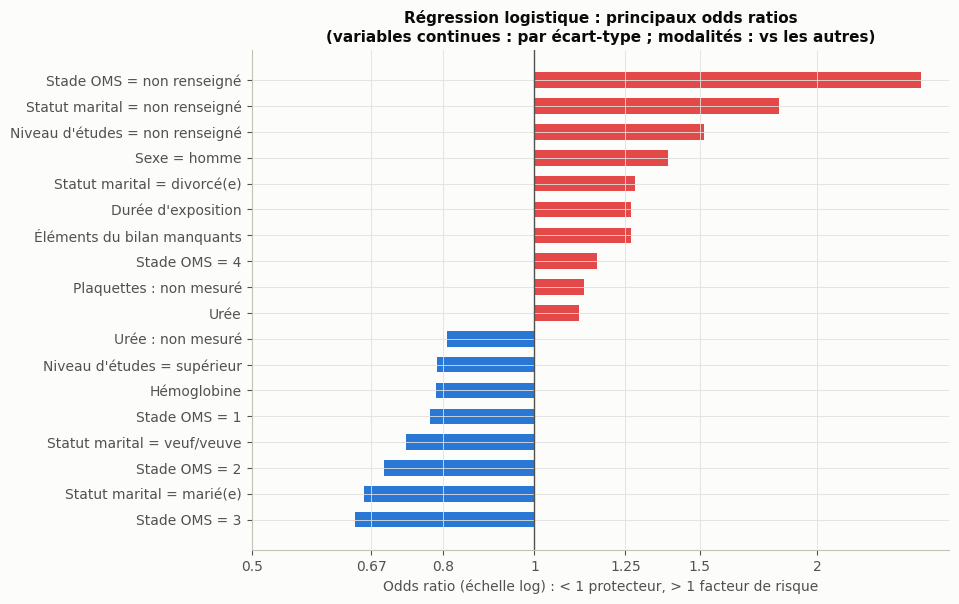

In [45]:
lr = modeles['Régression logistique']
coefs = pd.Series(lr.named_steps['clf'].coef_[0], index=[libelle(n) for n in lr.named_steps['prep'].get_feature_names_out()])
odds = np.exp(coefs).sort_values()
extremes = pd.concat([odds.head(8), odds.tail(10)])

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(range(len(extremes)), np.log(extremes.values), color=[SERIES[0] if v < 1 else SERIES[7] for v in extremes.values], height=0.6)
ax.set_yticks(range(len(extremes)), extremes.index)
ticks = [0.5, 0.67, 0.8, 1, 1.25, 1.5, 2]
ax.set_xticks(np.log(ticks), [str(t) for t in ticks])
ax.axvline(0, color=INK2, lw=1)
ax.set_xlabel('Odds ratio (échelle log) : < 1 protecteur, > 1 facteur de risque')
ax.set_title('Régression logistique : principaux odds ratios\n(variables continues : par écart-type ; modalités : vs les autres)')
savefig(fig, '21_odds_ratios')
plt.show()

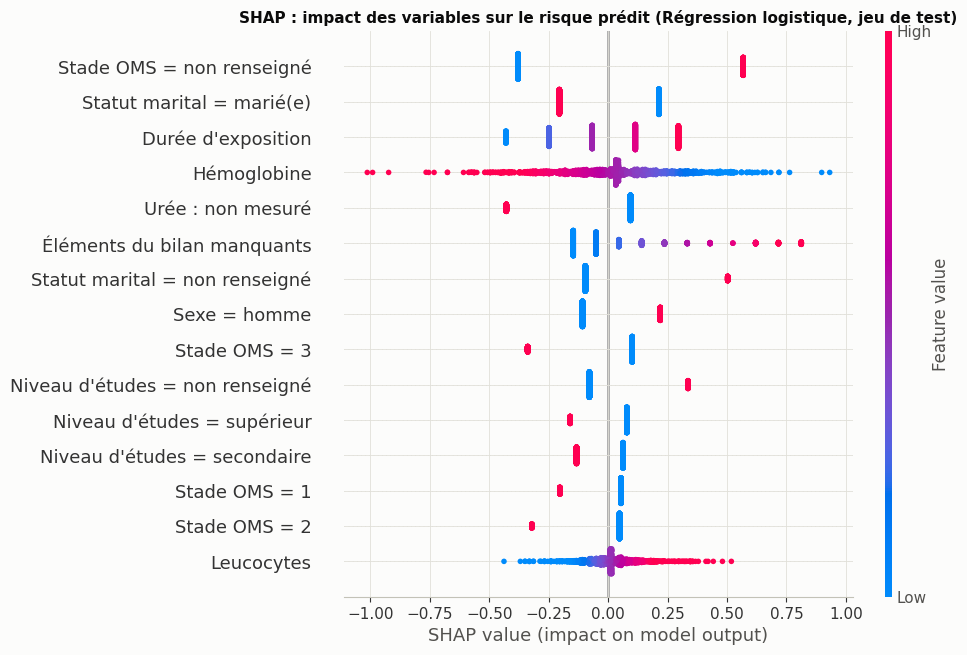

In [46]:
def valeurs_shap(modele, X_fond, X_cible):
    """Valeurs SHAP adaptées au type de modèle (log-odds pour XGBoost et la régression logistique)."""
    prep, clf = modele.named_steps['prep'], modele.named_steps['clf']
    A_fond, A_cible = prep.transform(X_fond), prep.transform(X_cible)
    if isinstance(clf, xgb.XGBClassifier):
        # TreeSHAP exact calculé nativement par XGBoost (contourne une incompatibilité shap 0.49 / xgboost 3)
        contributions = clf.get_booster().predict(xgb.DMatrix(A_cible), pred_contribs=True)
        sv, base = contributions[:, :-1], float(contributions[0, -1])
    elif isinstance(clf, RandomForestClassifier):
        explicateur = shap.TreeExplainer(clf)
        sv = explicateur.shap_values(A_cible)
        sv = sv[1] if isinstance(sv, list) else sv
        sv = sv[:, :, 1] if sv.ndim == 3 else sv
        base = np.ravel(explicateur.expected_value)[-1]
    elif isinstance(clf, LogisticRegression):
        explicateur = shap.LinearExplainer(clf, A_fond)
        sv, base = explicateur.shap_values(A_cible), explicateur.expected_value
    else:
        fond = shap.sample(A_fond, 100, random_state=SEED)
        explicateur = shap.KernelExplainer(lambda a: clf.predict_proba(a)[:, 1], fond)
        sv, base = explicateur.shap_values(A_cible, nsamples=200), explicateur.expected_value
    return np.asarray(sv), base, A_cible, prep.get_feature_names_out()


sv_test, base_shap, A_shap, noms_shap = valeurs_shap(modele_final, X_train, X_test)
shap.summary_plot(sv_test, A_shap, feature_names=[libelle(n) for n in noms_shap], max_display=15, show=False, plot_size=(10, 6.5))
plt.title(f'SHAP : impact des variables sur le risque prédit ({NOM_FINAL}, jeu de test)', fontweight='bold')
savefig(plt.gcf(), '22_shap_beeswarm')
plt.show()

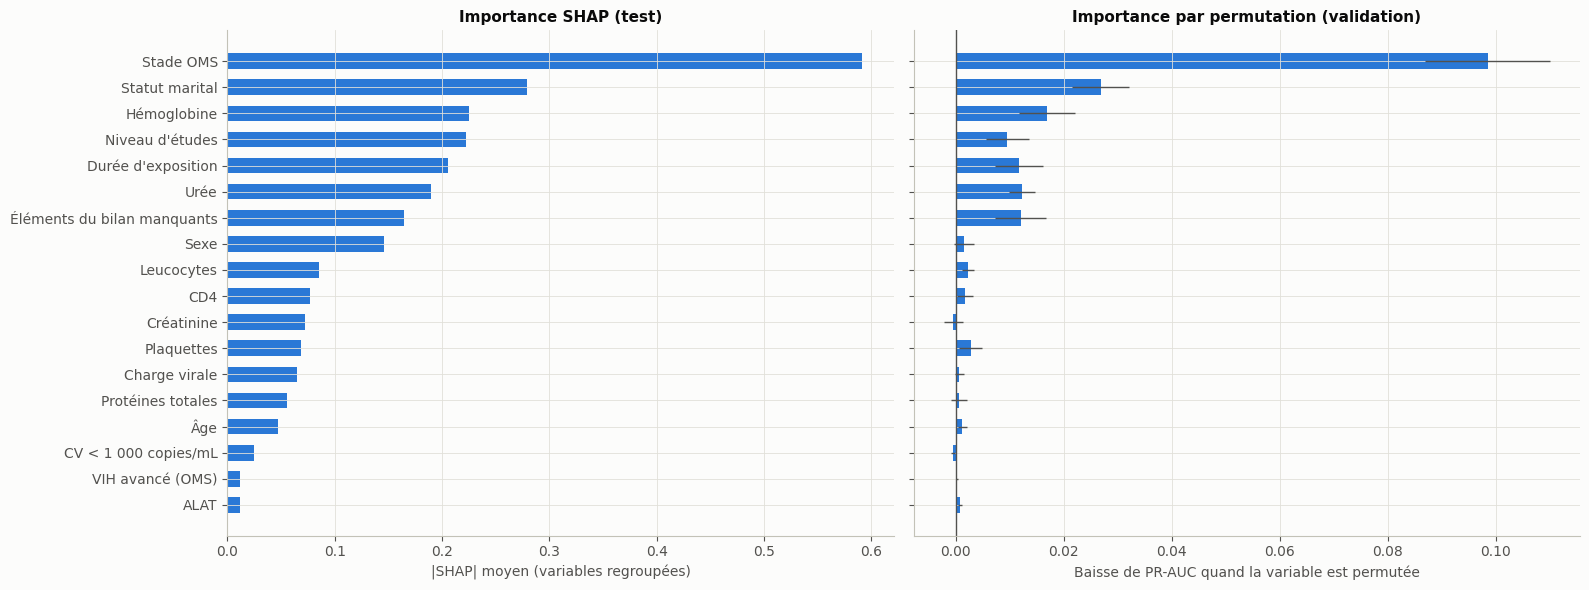

In [47]:
# Importance agrégée par variable d'origine : valeur + indicateur « non mesuré », ou ensemble des modalités
contrib_groupes = pd.DataFrame(sv_test, columns=noms_shap).T.groupby(var_modele).sum().T
imp_shap = contrib_groupes.abs().mean().rename(index=lambda v: VARIABLES[v][0]).sort_values()

perm = permutation_importance(modele_final, X_val, y_val, scoring='average_precision', n_repeats=10,
                              random_state=SEED, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=[VARIABLES[c][0] for c in X_val.columns]).reindex(imp_shap.index)
err_perm = pd.Series(perm.importances_std, index=[VARIABLES[c][0] for c in X_val.columns]).reindex(imp_shap.index)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
axes[0].barh(imp_shap.index, imp_shap.values, color=COULEUR[NOM_FINAL], height=0.6)
axes[0].set(xlabel='|SHAP| moyen (variables regroupées)', title='Importance SHAP (test)')
axes[1].barh(imp_perm.index, imp_perm.values, xerr=err_perm.values, color=COULEUR[NOM_FINAL], height=0.6,
             error_kw=dict(ecolor=INK2, lw=1))
axes[1].axvline(0, color=INK2, lw=1)
axes[1].set(xlabel='Baisse de PR-AUC quand la variable est permutée', title='Importance par permutation (validation)')
fig.tight_layout()
savefig(fig, '23_importances')
plt.show()

### 10.1 Carte patient : l'affichage prévu dans VIHEPAT
Pour chaque patient, le soignant voit son niveau de risque et les **3 facteurs qui l'augmentent le plus**. Les contributions SHAP de la valeur d'un examen et de son indicateur « non mesuré » sont additionnées, ainsi que celles des modalités d'une même variable catégorielle.

In [48]:
def valeur_affichee(var, ligne):
    lab, col, unite = VARIABLES[var]
    v = ligne[col]
    if pd.isna(v):
        return f'{lab} : non renseigné'
    if var in ('vih_avance', 'cv_inf_1000'):
        return f"{lab} : {'oui' if v == 1 else 'non'}"
    if isinstance(v, str):
        return f"{lab} : {TRAD.get(v, v if var != 'WHOStage' else 'stade ' + v)}"
    if var == 'nb_examens_manquants':
        return f'{lab} : {int(v)} sur 10'
    return f"{lab} : {f'{v:,.0f}'.replace(',', ' ') if abs(v) >= 1000 else f'{v:.3g}'} {unite}"


def carte_patient(pos, contributions=contrib_groupes, probas=p_final_test, X_ref=X_test):
    ligne = df_model.loc[X_ref.index[pos]]
    c = contributions.iloc[pos].sort_values()
    sortie = [f"Patient {ligne['id_patient']} : risque de perte de suivi {probas[pos]:.0%} (niveau {niveau_risque(probas[pos])})",
              '  Facteurs qui augmentent le risque :']
    sortie += [f'    ↑ {valeur_affichee(v, ligne)}   (+{x:.2f})' for v, x in c[c > 0][::-1].head(3).items()]
    sortie.append('  Facteurs qui diminuent le risque :')
    sortie += [f'    ↓ {valeur_affichee(v, ligne)}   ({x:.2f})' for v, x in c[c < 0].head(2).items()]
    issue = 'PERDU DE VUE' if ligne['LTFU'] else 'resté dans le parcours de soins'
    sortie.append(f"  Issue réelle : {issue} (dernier contact {ligne['MonthsInCare']} mois après l'inclusion)")
    print('\n'.join(sortie) + '\n')


for pos in np.argsort(-p_final_test)[[0, len(p_final_test) // 2]]:
    carte_patient(pos)

Patient P2651 : risque de perte de suivi 98% (niveau élevé)
  Facteurs qui augmentent le risque :
    ↑ Stade OMS : non renseigné   (+0.77)
    ↑ Statut marital : non renseigné   (+0.75)
    ↑ Urée : 78.6 mmol/L   (+0.64)
  Facteurs qui diminuent le risque :
    ↓ Protéines totales : 109 g/L   (-0.12)
    ↓ Sexe : femme   (-0.11)
  Issue réelle : PERDU DE VUE (dernier contact 2 mois après l'inclusion)

Patient P2907 : risque de perte de suivi 53% (niveau modéré)
  Facteurs qui augmentent le risque :
    ↑ Hémoglobine : 7.5 g/dL   (+0.39)
    ↑ Créatinine : non renseigné   (+0.25)
    ↑ Éléments du bilan manquants : 4 sur 10   (+0.24)
  Facteurs qui diminuent le risque :
    ↓ Urée : non renseigné   (-0.43)
    ↓ Statut marital : marié(e)   (-0.27)
  Issue réelle : PERDU DE VUE (dernier contact 11 mois après l'inclusion)



**Interprétation de l'explicabilité.** Les trois méthodes concordent :
1. **Le stade OMS domine** : c'est de loin la variable la plus importante par permutation (perte d'environ 0,10 de PR-AUC). Ce qui compte surtout est qu'il soit **non renseigné** (OR ≈ 2,5) : un patient dont l'évaluation clinique initiale n'a pas été faite est un patient qui ne termine pas son parcours d'entrée. Le stade 4 (maladie avancée) augmente aussi le risque.
2. **Les facteurs sociaux** viennent ensuite : statut marital (non renseigné et divorcé(e) à risque, marié(e) protecteur), niveau d'études et **sexe masculin** (OR ≈ 1,4). Ce sont des résultats classiques de la littérature sur la rétention en soins VIH, en accord avec l'article.
3. **Les examens biologiques** pèsent peu, sauf l'**hémoglobine** (l'anémie augmente le risque) et l'**urée** (plus élevée chez les LTFU). Ces marqueurs d'un état général dégradé sont compatibles avec des décès non enregistrés.
4. La **durée d'exposition** joue un rôle modéré : un patient inclus plus tôt a eu plus de temps pour décrocher.

**Point de vigilance.** L'indicateur « Urée : non mesuré » a un effet *protecteur* (OR ≈ 0,8), ce qui est contre-intuitif. Il s'agit d'une **compensation statistique** entre indicateurs corrélés et non d'un effet clinique. L'urée manque autant chez les LTFU que chez les retenus (21 %), mais une fois les autres manques pris en compte, « urée seule manquante » signale plutôt une pratique de laboratoire chez des patients suivis. Cela rend certaines cartes patient moins lisibles ; la section 15 propose une correction.

**Cartes patient.** La première (98 %, niveau élevé) cumule un stade OMS et un statut marital non renseignés et une urée à 78,6 mmol/L, signe d'une insuffisance rénale sévère : un tableau cohérent avec une sortie rapide, ici à 2 mois.

## 11. Analyse des erreurs : exemples de succès et d'échecs
### 11.1 Quels perdus de vue le modèle détecte-t-il ?

,patients,sensibilite,risque_moyen_predit
moment de la sortie,,,
jamais revenu (0 mois),302,0.921,0.727
1 à 6 mois,140,0.786,0.601
7 à 24 mois,121,0.769,0.571
plus de 24 mois,118,0.619,0.515


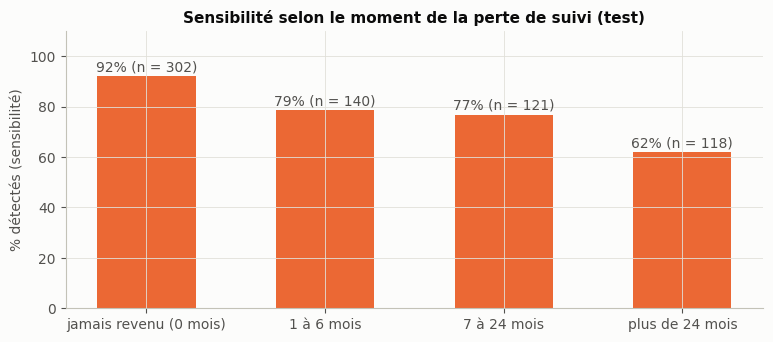

In [49]:
analyse = df_model.loc[idx_test].copy()
analyse['p'] = p_final_test
analyse['signalé'] = (analyse['p'] >= SEUIL).astype(int)
analyse['type'] = np.select([(analyse.signalé == 1) & (analyse.LTFU == 1), (analyse.signalé == 0) & (analyse.LTFU == 0),
                             (analyse.signalé == 1) & (analyse.LTFU == 0), (analyse.signalé == 0) & (analyse.LTFU == 1)],
                            ['Vrai positif', 'Vrai négatif', 'Faux positif', 'Faux négatif'], default='')
ltfu_test = analyse[analyse.LTFU == 1].copy()
ltfu_test['moment de la sortie'] = pd.cut(ltfu_test['MonthsInCare'], [-1, 0, 6, 24, 100],
                                          labels=['jamais revenu (0 mois)', '1 à 6 mois', '7 à 24 mois', 'plus de 24 mois'])
par_moment = ltfu_test.groupby('moment de la sortie', observed=True).agg(
    patients=('p', 'size'), sensibilite=('signalé', 'mean'), risque_moyen_predit=('p', 'mean'))
display(par_moment)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(par_moment.index.astype(str), 100 * par_moment['sensibilite'], color=C_LTFU, width=0.55)
for i, (s, n) in enumerate(zip(par_moment['sensibilite'], par_moment['patients'])):
    ax.text(i, 100 * s + 2, f'{s:.0%} (n = {n})', ha='center', color=INK2)
ax.set_ylim(0, 110)
ax.set_ylabel('% détectés (sensibilité)')
ax.set_title('Sensibilité selon le moment de la perte de suivi (test)')
savefig(fig, '24_sensibilite_moment')
plt.show()

In [50]:
# Profil des erreurs : en quoi les faux négatifs ressemblent-ils aux retenus, et les faux positifs aux LTFU ?
profil = analyse.groupby('type').agg(
    patients=('p', 'size'), risque_moyen=('p', 'mean'),
    elements_bilan_manquants=('nb_examens_manquants', 'mean'),
    pct_stade_OMS_inconnu=('WHOStage', lambda s: 100 * s.isna().mean()),
    pct_statut_marital_inconnu=('MaritalStatus', lambda s: 100 * s.isna().mean()),
    pct_marie=('MaritalStatus', lambda s: 100 * (s == 'Married').mean()),
    age_median=('Age', 'median'), cd4_median=('CD4Count', 'median'),
    mois_en_soins_median=('MonthsInCare', 'median'))
profil.reindex(['Vrai positif', 'Faux négatif', 'Vrai négatif', 'Faux positif'])

,patients,risque_moyen,elements_bilan_manquants,pct_stade_OMS_inconnu,pct_statut_marital_inconnu,pct_marie,age_median,cd4_median,mois_en_soins_median
type,,,,,,,,,
Vrai positif,554,0.708,2.525,69.675,25.271,37.906,40.000,222.500,0.000
Faux négatif,127,0.325,0.701,0.000,0.787,62.992,40.500,234.000,12.000
Vrai négatif,286,0.307,0.972,0.699,4.196,66.434,40.000,273.000,54.000
Faux positif,252,0.588,1.635,46.429,9.921,47.222,39.000,215.000,58.000


### 11.2 Exemples concrets
Quatre patients du jeu de test : le succès le plus net dans chaque classe, et l'erreur la plus grossière dans chaque sens.

In [51]:
exemples = {
    'SUCCÈS : vrai positif le plus confiant': analyse.index.get_indexer([analyse[analyse.type == 'Vrai positif']['p'].idxmax()])[0],
    'SUCCÈS : vrai négatif le plus confiant': analyse.index.get_indexer([analyse[analyse.type == 'Vrai négatif']['p'].idxmin()])[0],
    'ÉCHEC : faux négatif le plus grossier': analyse.index.get_indexer([analyse[analyse.type == 'Faux négatif']['p'].idxmin()])[0],
    'ÉCHEC : faux positif le plus grossier': analyse.index.get_indexer([analyse[analyse.type == 'Faux positif']['p'].idxmax()])[0],
}
for titre, pos in exemples.items():
    print(f'=== {titre} ===')
    carte_patient(pos)

=== SUCCÈS : vrai positif le plus confiant ===
Patient P2651 : risque de perte de suivi 98% (niveau élevé)
  Facteurs qui augmentent le risque :
    ↑ Stade OMS : non renseigné   (+0.77)
    ↑ Statut marital : non renseigné   (+0.75)
    ↑ Urée : 78.6 mmol/L   (+0.64)
  Facteurs qui diminuent le risque :
    ↓ Protéines totales : 109 g/L   (-0.12)
    ↓ Sexe : femme   (-0.11)
  Issue réelle : PERDU DE VUE (dernier contact 2 mois après l'inclusion)

=== SUCCÈS : vrai négatif le plus confiant ===
Patient P5329 : risque de perte de suivi 13% (niveau faible)
  Facteurs qui augmentent le risque :
    ↑ Éléments du bilan manquants : 3 sur 10   (+0.14)
    ↑ Leucocytes : 6.1 10⁹/L   (+0.04)
    ↑ Protéines totales : non renseigné   (+0.01)
  Facteurs qui diminuent le risque :
    ↓ Stade OMS : stade 3   (-0.62)
    ↓ Urée : non renseigné   (-0.43)
  Issue réelle : resté dans le parcours de soins (dernier contact 30 mois après l'inclusion)

=== ÉCHEC : faux négatif le plus grossier ===
Patient

**Interprétation de l'analyse des erreurs.**

**Ce que le modèle détecte bien, ce qu'il rate.** La sensibilité dépend fortement du **moment** de la sortie :

| Moment de la perte de suivi | Sensibilité |
|---|---|
| Jamais revenu après l'inclusion | **92 %** |
| 1 à 6 mois | 79 % |
| 7 à 24 mois | 77 % |
| Plus de 24 mois | **62 %** |

Le modèle repère très bien les **décrochages précoces**, mais mal ceux qui surviennent après des années de suivi. C'est logique : ce qui pousse un patient stable à partir au bout de 3 ans (déménagement, perte d'emploi, lassitude du traitement) **n'existe pas encore à l'inclusion**.

**Profil des erreurs.**
* **Faux négatifs** (127) : des dossiers **complets** (0 % de stade OMS manquant contre 70 % chez les vrais positifs), des patients majoritairement marié(e)s (63 %), qui décrochent tard (médiane de 12 mois en soins). Ce sont des « patients modèles » à l'inclusion.
* **Faux positifs** (252) : des dossiers souvent **incomplets** (46 % de stade OMS manquant), mais des patients restés en soins longtemps (médiane de 58 mois). Le signal de complétude **mélange le comportement du patient et les pratiques de saisie** de la clinique.

**Analyse des quatre exemples.**
1. **Vrai positif (P2651, 98 %)** : stade OMS et statut marital non renseignés, urée à 78,6 mmol/L. Patient gravement malade avec un bilan incomplet, sorti à 2 mois. Le modèle a raison pour de bonnes raisons.
2. **Vrai négatif (P5329, 13 %)** : stade OMS 3 documenté. Le stade 3 conduit à une mise sous traitement rapide, donc à un patient engagé dans le parcours. Il est resté 30 mois.
3. **Faux négatif le plus grossier (P5717, 9 %)** : un seul facteur emporte la décision, une **hémoglobine à 19,5 g/dL** (contribution −0,96). Cette valeur est extrême, au-dessus de la norme masculine, et très suspecte chez un patient VIH à l'inclusion : probablement une erreur de saisie (9,5 ?). Elle passe sous notre borne de 20 g/dL, et la régression logistique l'**extrapole linéairement** en un effet très protecteur. Le patient n'est jamais revenu. Causes : une borne de plausibilité trop permissive et la linéarité du modèle. Pistes : resserrer la borne avec le référent clinique, ou écrêter les valeurs extrêmes.
4. **Faux positif le plus grossier (P4388, 93 %)** : **les 10 éléments du bilan manquent**, ainsi que le stade OMS et le statut marital. Tout signale un patient « fantôme », pourtant suivi 35 mois. Le dossier n'a probablement jamais été complété (transfert entrant dont le dossier est resté ailleurs, retard de saisie). Cause : la complétude mesure aussi la qualité de l'enregistrement. Dans VIHEPAT, le soignant verra pourquoi le score est élevé, pourra **compléter le dossier**, et le score sera alors recalculé.

## 12. Équité et biais
On vérifie que le modèle fonctionne aussi bien pour tous les groupes de patients. L'indicateur clé est l'**égalité des chances** : un futur perdu de vue doit avoir la même probabilité d'être détecté, qu'il soit homme ou femme, jeune ou âgé.

patients  % LTFU  ROC-AUC  sensibilité  taux de faux positifs   VPP  % signalés
dimension       groupe                                                                                        
Sexe            femme               806  53.102    0.752        0.797                  0.471 0.657      64.392
                homme               413  61.259    0.788        0.842                  0.463 0.742      69.492
Tranche d'âge   30-44 ans           646  58.978    0.775        0.819                  0.438 0.729      66.254
                < 30 ans             60  51.667    0.709        0.774                  0.552 0.600      66.667
                non renseigné       160  31.875    0.908        0.941                  0.523 0.457      65.625
                ≥ 45 ans            353  61.756    0.734        0.780                  0.467 0.730      66.006
Niveau d'études non renseigné       286  69.930    0.801        0.935                  0.767 0.739      88.462
                primaire            188  56.383    0.771        0.840                  0.524 0.674      70.213
                secondaire          481  52.599    0.741        0.727                  0.373 0.684      55.925
                supérieur           264  46.212    0.726        0.770                  0.408 0.618      57.576
Cohorte         2010                270  56.296    0.700        0.822                  0.542 0.661      70.000
                2011                302  57.947    0.742        0.777                  0.504 0.680      66.225
                2012                280  57.500    0.792        0.832                  0.454 0.713      67.143
                2013                224  55.357    0.826        0.879                  0.470 0.699      69.643
                2014                143  48.252    0.744        0.725                  0.311 0.685      51.049

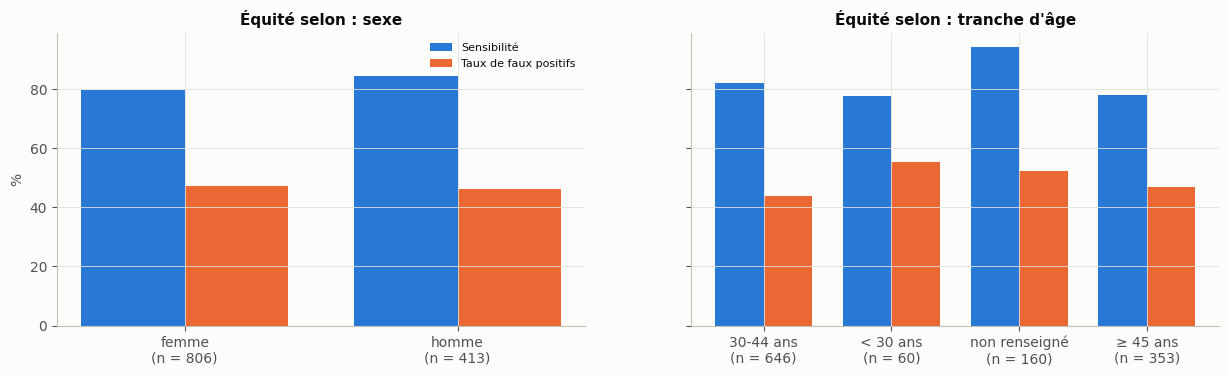

In [52]:
groupes_equite = {
    'Sexe': analyse['Sex'].map(TRAD),
    "Tranche d'âge": pd.cut(analyse['Age'], [0, 29, 44, 200], labels=['< 30 ans', '30-44 ans', '≥ 45 ans']).astype(str).replace('nan', 'non renseigné'),
    "Niveau d'études": analyse['Education'].map(TRAD).fillna('non renseigné'),
    'Cohorte': analyse['Cohort year'].astype(str)}
lignes = []
for dimension, g in groupes_equite.items():
    for modalite, sous in analyse.groupby(g):
        if len(sous) < 30 or sous.LTFU.nunique() < 2:
            continue
        m = metriques(sous.LTFU, sous.p, SEUIL)
        lignes.append({'dimension': dimension, 'groupe': modalite, 'patients': len(sous), '% LTFU': 100 * sous.LTFU.mean(),
                       'ROC-AUC': m['ROC-AUC'], 'sensibilité': m['Sensibilité'], 'taux de faux positifs': 1 - m['Spécificité'],
                       'VPP': m['VPP'], '% signalés': 100 * sous.signalé.mean()})
equite = pd.DataFrame(lignes).set_index(['dimension', 'groupe'])
display(equite)

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
for ax, dimension in zip(axes, ['Sexe', "Tranche d'âge"]):
    t = equite.loc[dimension]
    pos, h = np.arange(len(t)), 0.38
    ax.bar(pos - h / 2, 100 * t['sensibilité'], width=h, color=SERIES[0], label='Sensibilité')
    ax.bar(pos + h / 2, 100 * t['taux de faux positifs'], width=h, color=SERIES[1], label='Taux de faux positifs')
    ax.set_xticks(pos, [f'{i}\n(n = {n})' for i, n in zip(t.index, t['patients'])])
    ax.set_title(f'Équité selon : {dimension.lower()}')
axes[0].set_ylabel('%')
axes[0].legend(fontsize=8)
savefig(fig, '25_equite')
plt.show()

**Interprétation de l'équité.**
* **Sexe** : sensibilité de 80 % chez les femmes et 84 % chez les hommes, taux de faux positifs presque identiques (47 % et 46 %). L'égalité des chances est **globalement respectée**, avec un écart de 4 points.
* **Âge** : performances comparables entre 30-44 ans et 45 ans et plus. Le groupe de moins de 30 ans est trop petit (n = 60) pour conclure.
* **⚠️ Biais lié à la complétude** : les patients dont le **niveau d'études n'est pas renseigné** sont signalés dans 88 % des cas, avec un **taux de faux positifs de 77 %** contre 37 à 52 % ailleurs. Le modèle pénalise donc les patients dont les données sociales n'ont pas été saisies. Le défaut tient au **dossier** et non au patient, et il expose ces patients à des relances inutiles, avec un risque de stigmatisation ou de lassitude.
  * *Atténuation dans VIHEPAT* : rendre ces champs obligatoires ou faciles à compléter, afficher les facteurs du score pour que le soignant repère un « risque administratif », et surveiller le taux de faux positifs par groupe après le déploiement.
* **Cohortes** : l'AUC varie de 0,70 (2010) à 0,83 (2013). La performance dépend des pratiques d'enregistrement de chaque période, d'où l'importance de **recalibrer le modèle sur les données de VIHEPAT**.

## 13. Analyses de sensibilité
Chaque variante ré-entraîne **le même type de modèle avec les mêmes hyperparamètres** que le modèle final, sur l'entraînement, et l'évalue sur la validation. Le jeu de test reste intact. Une exception : l'analyse temporelle (S4) suit son propre découpage par cohorte.

| Variante | Question |
|---|---|
| **S1. Fuite volontaire** : ajout des valeurs biologiques de fin de suivi (`X2`) | Que se passerait-il si l'on ignorait l'audit de la section 3 ? |
| **S2. Modèle strict** : aucune information sur les valeurs manquantes | Quelle part de la performance vient de la complétude du dossier ? |
| **S3. Horizon fixe de 24 mois** : cible = perte de suivi dans les 2 premières années | Les conclusions tiennent-elles avec une durée d'observation identique pour tous ? |
| **S4. Validation temporelle** : entraînement sur 2010-2012, évaluation sur 2013-2014 | Le modèle reste-t-il valable quand les pratiques évoluent ? |

In [53]:
def evaluer_variante(nom_modele, idx_tr, idx_ev, cible=None, donnees=None, **kw_prep):
    donnees = df_model if donnees is None else donnees
    cible = donnees['LTFU'] if cible is None else cible
    prep = construire_preprocesseur(**kw_prep)
    colonnes = [c for _, _, cols in prep.transformers for c in cols]
    modele = Pipeline([('prep', prep), ('clf', clone(modeles[nom_modele].named_steps['clf']))])
    modele.fit(donnees.loc[idx_tr, colonnes], cible.loc[idx_tr])
    p = modele.predict_proba(donnees.loc[idx_ev, colonnes])[:, 1]
    return {'ROC-AUC': roc_auc_score(cible.loc[idx_ev], p), 'PR-AUC': average_precision_score(cible.loc[idx_ev], p),
            'prévalence': cible.loc[idx_ev].mean()}


# Variables de « fuite » pour S1 : dernière valeur (log) et égalité X2 = X
df_fuite = df_model.copy()
for c in LABS:
    df_fuite[f'{c}2_log'] = np.log1p(df_fuite[f'{c}2'].clip(lower=0))
    df_fuite[f'{c}_egal'] = (df_fuite[c] == df_fuite[f'{c}2']).astype(float)
vars_fuite = [f'{c}2_log' for c in LABS] + [f'{c}_egal' for c in LABS]

sans_expo = [v for v in VARS_GEN if v != 'annees_exposition']
cible_24m = (df_model['MonthsInCare'] < 24 - DELAI_LTFU).astype(int)       # dernier contact avant 18 mois
idx_anciens = df_model.index[df_model['Cohort year'] <= 2012]
idx_recents = df_model.index[df_model['Cohort year'] >= 2013]

variantes = {}
for nom in dict.fromkeys([NOM_FINAL, 'Régression logistique', 'XGBoost']):
    variantes[(nom, 'Modèle de référence')] = evaluer_variante(nom, idx_train, idx_val)
    variantes[(nom, 'S1. Fuite : + valeurs de fin de suivi')] = evaluer_variante(nom, idx_train, idx_val, donnees=df_fuite, vars_bio=VARS_BIO + vars_fuite)
    variantes[(nom, 'S2. Strict : sans information de complétude')] = evaluer_variante(nom, idx_train, idx_val, avec_completude=False)
    variantes[(nom, 'S3. Horizon fixe de 24 mois')] = evaluer_variante(nom, idx_train, idx_val, cible=cible_24m, vars_gen=sans_expo)
    variantes[(nom, 'S4. Temporel : 2010-12 → 2013-14')] = evaluer_variante(nom, idx_anciens, idx_recents, vars_gen=sans_expo)
sensibilite = pd.DataFrame(variantes).T
sensibilite.index.names = ['modèle', 'variante']
print(f"Cible à 24 mois : {cible_24m.sum()} LTFU ({cible_24m.mean():.1%})")
sensibilite

Cible à 24 mois : 2596 LTFU (42.6%)


ROC-AUC  PR-AUC  prévalence
modèle                variante                                                                
Régression logistique Modèle de référence                            0.748   0.792       0.558
                      S1. Fuite : + valeurs de fin de suivi          0.931   0.951       0.558
                      S2. Strict : sans information de complétude    0.619   0.674       0.558
                      S3. Horizon fixe de 24 mois                    0.774   0.725       0.420
                      S4. Temporel : 2010-12 → 2013-14               0.773   0.808       0.525
XGBoost               Modèle de référence                            0.757   0.798       0.558
                      S1. Fuite : + valeurs de fin de suivi          0.947   0.961       0.558
                      S2. Strict : sans information de complétude    0.642   0.685       0.558
                      S3. Horizon fixe de 24 mois                    0.788   0.744       0.420
                      S4. Temporel : 2010-12 → 2013-14               0.775   0.811       0.525

**Interprétation des analyses de sensibilité.**
* **S1, fuite volontaire** : avec les valeurs de fin de suivi, l'AUC bondit à **0,93** (régression logistique) et **0,95** (XGBoost). Ce modèle « spectaculaire » serait **inutilisable** : il exploite une information qui n'existe qu'une fois le patient parti. C'est la justification chiffrée de l'audit de la section 3.
* **S2, modèle strict** : sans aucune information sur les valeurs manquantes, l'AUC tombe à **0,62 à 0,64**. Environ **la moitié du pouvoir discriminant** (au-delà du hasard) vient donc de la **complétude du dossier**. Les valeurs cliniques et sociales seules ont un pouvoir modeste, ce qui rejoint l'article, où seul le statut marital ressortait. Ce chiffre est la **borne basse honnête** de la performance.
* **S3, horizon fixe de 24 mois** : avec la même durée d'observation pour tous, l'AUC est de 0,77 à 0,79 ; la PR-AUC est plus basse car la prévalence n'est que de 42,6 %. Les conclusions **ne dépendent pas** des différences de durée d'exposition entre cohortes.
* **S4, validation temporelle** : entraîné sur 2010-2012 et évalué sur 2013-2014, le modèle conserve une AUC de **0,77**, **sans dégradation**. Il est robuste au passage du temps sur ce site.

## 14. Limites
Nous les présentons en toute transparence, conformément aux directives (section 6.2 : « être transparent sur les limites et faiblesses »).

1. **Transposabilité** : un seul site (LUTH, Lagos), une période ancienne (inclusions 2010-2014), avant la politique « tester et traiter » de l'OMS (2016). VIHEPAT visera des patients béninois en 2026, avec des pratiques différentes. **Le modèle devra être recalibré et validé sur des données béninoises avant tout usage réel.**
2. **La cible « LTFU » n'équivaut pas à un décrochage réel.** Selon l'article, parmi les patients tracés, 16 % étaient décédés et 36 % des patients interrogés s'étaient **transférés ailleurs sans le signaler**. Une partie de ce que le modèle prédit est donc une « disparition des registres » plutôt qu'un abandon de traitement. Ce bruit sur l'étiquette limite la performance atteignable.
3. **Cible reconstruite** : le mois d'inclusion est inconnu. La règle conservatrice reproduit l'article à 3 patients près, mais reste approximative pour les patients inclus en début d'année.
4. **Dépendance à la complétude** : la moitié du signal vient des informations non renseignées. Ce signal mêle comportement du patient et pratiques de saisie, et il n'est **pas garanti qu'il se transpose** à un outil numérique comme VIHEPAT, où les champs peuvent être obligatoires. La borne basse (modèle strict) est une AUC de 0,62.
5. **Données de l'inclusion uniquement** : les décrochages tardifs (après 24 mois) sont mal détectés (sensibilité de 62 %).
6. **Discrimination modérée** (AUC 0,77) et **spécificité de 53 %** au seuil d'alerte : environ un patient retenu sur deux est signalé. Le score est une aide à la priorisation, pas un tri automatique.
7. **Lisibilité** : certains indicateurs de valeur manquante ont des coefficients contre-intuitifs (urée), par compensation statistique.
8. **Modèle de Cox** : l'hypothèse des risques proportionnels est violée pour 5 covariables.
9. **Bornes de plausibilité** : elles ne sont pas encore validées cliniquement ; la valeur d'hémoglobine à 19,5 g/dL en montre les conséquences.
10. **Périmètre** : le jeu ne concerne que le VIH. Les hépatites B et C, couvertes par VIHEPAT, ne sont pas représentées.

## 15. Pistes d'amélioration
| Priorité | Piste | Problème traité |
|---|---|---|
| ★★★ | **Variables dynamiques issues de VIHEPAT** : délai depuis le dernier contact, rendez-vous manqués (lien avec le modèle 2), confirmations de prise, réponses aux relances. Recalcul du score à chaque contact (*landmarking*, modèles de survie à covariables dépendantes du temps) | Limites 5 et 6 ; les courbes d'apprentissage montrent que c'est l'information qui manque, pas le volume |
| ★★★ | **Boucle d'apprentissage** : recalibration puis validation externe sur les données béninoises collectées avec consentement, et suivi de la dérive (MLflow, Evidently) | Limites 1 et 4 |
| ★★☆ | Remplacer les 9 indicateurs « non mesuré » par **un score de complétude unique** ou une régularisation par groupe, et distinguer manque administratif et examen non réalisé | Limite 7 ; explications plus lisibles |
| ★★☆ | **Valider les bornes de plausibilité** avec le référent clinique (ex. hémoglobine > 18 g/dL) et écrêter les extrêmes pour la régression logistique | Limite 9 ; faux négatif P5717 |
| ★★☆ | Exploiter le jeu **S4** (268 patients tracés et interrogés) pour distinguer décès, transferts silencieux et vrais décrochages, puis passer à un modèle multi-classes | Limite 2 |
| ★☆☆ | Modèles de survie plus souples : Cox stratifié ou à coefficients variables, gradient boosting de survie | Limite 8 |
| ★☆☆ | Suivi de l'équité en production : taux de faux positifs par groupe, plafonnement des relances | Biais lié à la complétude (section 12) |
| ★☆☆ | **Industrialisation** : extraire `nettoyer`, `creer_variables` et `ImputationAleatoire` dans un module Python versionné, exposé par une API (FastAPI) au back-end Node de VIHEPAT | Intégration |

## 16. Export du modèle et journal des expérimentations
Le pipeline complet (prétraitement et modèle) est sauvegardé avec ses métadonnées : variables attendues, seuils, performances et version des données. Ce fichier est celui que le back-end de VIHEPAT chargera.

In [54]:
CHEMIN_MODELE = MODEL_DIR / 'ltfu_modele_final.joblib'
joblib.dump(modele_final, CHEMIN_MODELE)
assert np.allclose(joblib.load(CHEMIN_MODELE).predict_proba(X_test)[:, 1], p_final_test)   # rechargement vérifié

metadonnees = {
    'modele': NOM_FINAL, 'version': '1.0.0', 'date': date.today().isoformat(),
    'usage': "Aide à la priorisation des relances ; ne constitue pas une décision clinique.",
    'cible': 'Perte de suivi (>= 6 mois sans service) au 31/12/2016, cohorte LUTH 2010-2014',
    'donnees': {'source': 'Balogun et al., PLoS ONE 2019, doi:10.1371/journal.pone.0219903 (S3, CC BY 4.0)',
                'sha256': SHA256_ATTENDU, 'patients': len(df_model), 'ltfu': int(df_model['LTFU'].sum())},
    'variables_entree': FEATURES,
    'pretraitement_requis': ("nettoyer() puis creer_variables() (sections 5.1-5.2) ; la classe ImputationAleatoire "
                             "(section 6.3) doit être importable pour recharger le pipeline"),
    'hyperparametres': {k: (v if isinstance(v, (int, float, str, type(None))) else str(v))
                        for k, v in modele_final.named_steps['clf'].get_params().items()
                        if k in {'C', 'n_estimators', 'max_depth', 'learning_rate', 'min_child_weight', 'subsample',
                                 'colsample_bytree', 'reg_lambda', 'gamma', 'min_samples_leaf', 'max_features', 'alpha'}},
    'seuils': {'alerte_sensibilite_80': SEUIL, 'risque_eleve_precision_85': SEUIL_ELEVE},
    'performances_test': {k: {'valeur': float(v), 'ic95': [float(resultats_test.loc[k, 'IC95 bas']), float(resultats_test.loc[k, 'IC95 haut'])]}
                          for k, v in resultats_test['valeur'].items()},
    'environnement': versions,
}
(MODEL_DIR / 'ltfu_modele_final.json').write_text(json.dumps(metadonnees, indent=2, ensure_ascii=False), encoding='utf-8')
print(f'Modèle : {CHEMIN_MODELE.relative_to(ROOT)}\nMétadonnées : models/ltfu_modele_final.json')

Modèle : models\ltfu_modele_final.joblib
Métadonnées : models/ltfu_modele_final.json


In [55]:
def f3(v):
    return f'{v:.3f}'


journal = pd.DataFrame([
    ('E01', 'Reconstruction de la cible (règle conservatrice, k = −6)', f"{n_ltfu} LTFU vs 3 397 publiés ; {df.loc[traces, 'LTFU'].mean():.1%} des tracés retrouvés", 'Règle retenue'),
    ('E02', 'Audit des variables X2 (fin de suivi)', f"CD4 : X2 = X chez {preuve.loc['CD4Count', '% X2 = X chez les LTFU']:.0f} % des LTFU vs {preuve.loc['CD4Count', '% X2 = X chez les retenus']:.0f} % des retenus", 'X2 exclues'),
    ('E03', 'Référence naïve', f"PR-AUC val = {f3(tab_val.loc['Référence naïve', 'PR-AUC'])}", 'Plancher'),
    ('E04', f'Régression logistique (C = {C_OPT:.3g})', f"PR-AUC val = {f3(tab_val.loc['Régression logistique', 'PR-AUC'])}, ROC-AUC = {f3(tab_val.loc['Régression logistique', 'ROC-AUC'])}", 'Référence interprétable'),
    ('E05', 'Random Forest (25 combinaisons, CV 5 plis)', f"PR-AUC val = {f3(tab_val.loc['Random Forest', 'PR-AUC'])}, ROC-AUC = {f3(tab_val.loc['Random Forest', 'ROC-AUC'])}", 'Comparé'),
    ('E06', 'XGBoost (40 combinaisons, CV 5 plis)', f"PR-AUC val = {f3(tab_val.loc['XGBoost', 'PR-AUC'])}, ROC-AUC = {f3(tab_val.loc['XGBoost', 'ROC-AUC'])}", 'Comparé'),
    ('E07', f'MLP 32-16 (alpha = {ALPHA_OPT}, arrêt epoch {mlp_retenu["epoch"]})', f"PR-AUC val = {f3(tab_val.loc['MLP', 'PR-AUC'])}, ROC-AUC = {f3(tab_val.loc['MLP', 'ROC-AUC'])}", 'Comparé'),
    ('E08', 'Modèle de Cox', f"C-index val = {f3(cox.score(Z_val, scoring_method='concordance_index'))}", 'Analyse complémentaire'),
    ('E09', 'Sélection (règle 6.1)', f'{NOM_FINAL} : {raison}', 'Modèle final'),
    ('E10', 'Seuil (sensibilité ≥ 80 % en validation)', f'seuil = {SEUIL:.3f} ; risque élevé ≥ {SEUIL_ELEVE}', 'Retenu'),
    ('E11', 'Évaluation test', f"ROC-AUC = {f3(resultats_test.loc['ROC-AUC', 'valeur'])}, PR-AUC = {f3(resultats_test.loc['PR-AUC', 'valeur'])}, sensibilité = {f3(resultats_test.loc['Sensibilité', 'valeur'])}", 'Résultat final'),
    ('E12', 'S1 : fuite volontaire (X2)', f"ROC-AUC val = {f3(sensibilite.loc[(NOM_FINAL, 'S1. Fuite : + valeurs de fin de suivi'), 'ROC-AUC'])}", 'Démontre la fuite, rejeté'),
    ('E13', 'S2 : modèle strict sans complétude', f"ROC-AUC val = {f3(sensibilite.loc[(NOM_FINAL, 'S2. Strict : sans information de complétude'), 'ROC-AUC'])}", 'Borne basse documentée'),
    ('E14', 'S3 : horizon fixe 24 mois', f"ROC-AUC val = {f3(sensibilite.loc[(NOM_FINAL, 'S3. Horizon fixe de 24 mois'), 'ROC-AUC'])}", 'Robustesse vérifiée'),
    ('E15', 'S4 : validation temporelle', f"ROC-AUC = {f3(sensibilite.loc[(NOM_FINAL, 'S4. Temporel : 2010-12 → 2013-14'), 'ROC-AUC'])}", 'Robustesse vérifiée'),
], columns=['ID', 'Expérience', 'Résultat', 'Décision'])
journal.to_csv(REPORT_DIR / 'journal_experiences.csv', index=False, encoding='utf-8-sig')
pd.concat({'validation': tab_val, 'test': tab_test}).to_csv(REPORT_DIR / 'metriques_modeles.csv', encoding='utf-8-sig')
print(f'Durée totale d\'exécution : {(time.time() - T_DEBUT) / 60:.1f} min')
journal.set_index('ID')

Durée totale d'exécution : 3.4 min


,Expérience,Résultat,Décision
ID,,,
E01,Reconstruction de la cible (règle conservatric...,3400 LTFU vs 3 397 publiés ; 98.6% des tracés ...,Règle retenue
E02,Audit des variables X2 (fin de suivi),CD4 : X2 = X chez 50 % des LTFU vs 4 % des ret...,X2 exclues
E03,Référence naïve,PR-AUC val = 0.558,Plancher
E04,Régression logistique (C = 0.1),"PR-AUC val = 0.792, ROC-AUC = 0.748",Référence interprétable
E05,"Random Forest (25 combinaisons, CV 5 plis)","PR-AUC val = 0.796, ROC-AUC = 0.755",Comparé
E06,"XGBoost (40 combinaisons, CV 5 plis)","PR-AUC val = 0.798, ROC-AUC = 0.757",Comparé
E07,"MLP 32-16 (alpha = 1.0, arrêt epoch 26)","PR-AUC val = 0.791, ROC-AUC = 0.754",Comparé
E08,Modèle de Cox,C-index val = 0.721,Analyse complémentaire
E09,Sélection (règle 6.1),Régression logistique : XGBoost n'apporte pas ...,Modèle final


## 17. Conclusion
* **Démarche** : la cible a été reconstruite et validée face à l'article (3 400 contre 3 397 LTFU), deux fuites de données ont été identifiées et neutralisées, et cinq approches ont été comparées avec une règle de choix fixée avant de voir les résultats. Le jeu de test, intact jusqu'au bout, a été accompagné d'intervalles de confiance, d'une analyse d'erreurs, d'une analyse d'équité et de quatre analyses de sensibilité.
* **Résultat** : une **régression logistique** explicable, avec une ROC-AUC de 0,765 et une PR-AUC de 0,817 sur le test. Elle détecte 81 % des futurs perdus de vue et atteint 89 % de précision sur les 20 % de patients les plus à risque. Les modèles plus complexes n'apportent pas de gain significatif.
* **Enseignement pour VIHEPAT** : avec les seules données d'inclusion, le signal le plus fort est le **désengagement lui-même** (un bilan d'entrée qui n'est pas complété). Les variables cliniques seules plafonnent à une AUC d'environ 0,62. C'est l'argument scientifique central du projet : **pour anticiper les ruptures, il faut observer l'engagement du patient en continu**. C'est ce que fera VIHEPAT, avant de réentraîner ce modèle sur ses propres données.

### Sources
1. Balogun M., Meloni S.T., Igwilo U.U. *et al.* (2019). Status of HIV-infected patients classified as lost to follow up from a large antiretroviral program in southwest Nigeria. *PLoS ONE* 14(7): e0219903. doi:10.1371/journal.pone.0219903. Données S3 sous licence CC BY 4.0.
2. World Health Organization (2017). *Guidelines for managing advanced HIV disease and rapid initiation of antiretroviral therapy* (définition du VIH avancé : CD4 < 200 ou stade OMS 3-4).
3. Vickers A.J., Elkin E.B. (2006). Decision curve analysis: a novel method for evaluating prediction models. *Medical Decision Making* 26(6): 565-574.
4. Lundberg S.M., Lee S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS* (SHAP).
5. Chen T., Guestrin C. (2016). XGBoost: a scalable tree boosting system. *KDD*.
6. Pedregosa F. *et al.* (2011). Scikit-learn: machine learning in Python. *JMLR* 12: 2825-2830.
7. Davidson-Pilon C. (2019). lifelines: survival analysis in Python. *Journal of Open Source Software* 4(40): 1317.
8. NEURACTIF (2026). *Directives techniques des participants*, Hackathon AI4Youth Lomé 2026.
9. Équipe TechMakers (2026). *VIHEPAT-Bénin : note de cadrage des modèles de Machine Learning.*